# Day 26 — Historical Lexical-Instability Characterization

Construct and freeze the historical-only lexical-instability predictor.

In [ ]:
# Imports
import json
from pathlib import Path

In [ ]:
# Project paths
def find_project_root():
    current = Path.cwd().resolve()
    for path in [current, *current.parents]:
        if (path / "README.md").exists():
            return path
    raise RuntimeError(
        "Project root not found. Run this notebook from inside the repository."
    )

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"

def resolve_artifact_paths(value):
    """Rebase legacy project paths in loaded metadata; never rewrite artifacts.

    Keep all non-path values, model identifiers, and scientific settings intact.
    Support the original project name and the public repository name.
    """
    if isinstance(value, dict):
        return {key: resolve_artifact_paths(item) for key, item in value.items()}
    if isinstance(value, list):
        return [resolve_artifact_paths(item) for item in value]
    if isinstance(value, str):
        normalized = value.replace("\\", "/")
        for name in ("FinGPT_Project", "FinGPT-Temporal-Generalization"):
            marker = "/" + name + "/"
            if marker in normalized and "\n" not in normalized:
                # Only standalone filesystem references, never prose containing a path.
                prefix, relative = normalized.split(marker, 1)
                if prefix.startswith("/") or (len(prefix) > 1 and prefix[1] == ":"):
                    if not any(char.isspace() for char in relative):
                        return str(PROJECT_ROOT / relative)
    return value

def load_artifact_json(stream, *args, **kwargs):
    return resolve_artifact_paths(json.load(stream, *args, **kwargs))


In [ ]:
# Reproducibility settings
# Original seeds and deterministic settings remain at their original workflow
# positions below, including stage-specific RNG resets. No new seed is introduced.

**ColabFinGPT — Historical-Only Mechanism Validation**

---

## Frozen Research Question

> Do lexical features whose sentiment-label associations are unstable across historical time contribute to higher future classification error?

### Primary Hypothesis — H1

Tokens with less stable historical sentiment-label associations will be associated with higher future classification error.

\[
\text{Historical lexical-label instability} \uparrow
\quad\Longrightarrow\quad
\text{Future classification error association} \uparrow
\]

### Null Hypothesis — H0

Historical lexical-label instability is not systematically associated with future classification error.

---

## Day 26 Endpoint

Day 26 **does not test H1**.

The sole scientific endpoint of Day 26 is to construct, audit, and freeze a historical-only lexical instability predictor:

\[
A(v,c,t)
=
\log\frac{n_{11}+\alpha}{n_{10}+\alpha}
-
\log\frac{n_{01}+\alpha}{n_{00}+\alpha},
\qquad
\alpha=0.5
\]

followed by

\[
I(v,c)
=
SD_t[A(v,c,t)]
\]

and

\[
I(v)
=
\max_c I(v,c).
\]

The resulting frozen token-level instability ranking will become the predictor used for the Day 27 out-of-time hypothesis test.

---

## Pre-Registered Primary Settings

- Historical temporal windows: **4 chronological non-overlapping windows (H1–H4)**
- Feasibility fallback: **3 windows only if minimum class support fails**
- Features: **lowercased unigrams + bigrams**
- Stop-word removal: **None**
- Maximum document frequency: **0.95**
- Minimum historical document frequency: **20**
- Minimum temporal support: **presence in at least 3 historical windows**
- Association weighting: **binary document presence**
- Association metric: **smoothed one-vs-rest log-odds**
- Smoothing constant: **α = 0.5**
- Primary instability: **sample SD across historical windows, ddof=1**
- Token-level instability: **maximum class-specific instability**
- Deterministic class tie order: **negative → neutral → positive**

---

## Scientific Firewall

### Allowed

- Historical pre-future observations
- Historical labels
- Historical timestamps and sources
- Day 25 outputs as motivating context only
- Frozen upstream artifacts and hashes for identity verification

### Forbidden

- Using F1–F6 labels or future prediction errors to construct the Day 26 predictor
- Using Day 25 error-associated terms as a vocabulary whitelist
- Selecting thresholds based on future performance
- Trying multiple primary instability definitions and selecting the strongest result
- New model training or fine-tuning
- Prompt modification
- Checkpoint reselection
- Future threshold tuning
- Redefining the primary endpoint after inspecting Day 27 results

---

## Interpretation Boundary

Day 26 may conclude that:

> A historical-only lexical-label instability estimator was constructed and frozen.

Day 26 **must not conclude** that:

> lexical instability causes future errors

or that:

> H1 is supported.

Those claims are reserved for the Day 27 out-of-time test.

In [2]:
# ============================================================
# DAY 26 — CODE CELL 2
# Canonical project paths + core helper functions
# ============================================================

from pathlib import Path
import hashlib
import json
import os
import sys
import platform
from datetime import datetime, timezone

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Canonical project paths
# ------------------------------------------------------------


# PROJECT_ROOT is discovered in the project-path setup cell.

RESULTS_ROOT = PROJECT_ROOT / "results"
NOTEBOOKS_ROOT = PROJECT_ROOT / "notebooks"

DAY22_DIR = RESULTS_ROOT / "day22"
DAY23_DIR = RESULTS_ROOT / "day23"
DAY24_DIR = RESULTS_ROOT / "day24"
DAY25_DIR = RESULTS_ROOT / "day25"

DAY26_DIR = RESULTS_ROOT / "day26"

DAY26_NOTEBOOK_PATH = (
    NOTEBOOKS_ROOT /
    "day26_historical_temporal_lexical_instability.ipynb"
)


# Day 26 output directory may be created now.
# No upstream scientific artifact is modified.
DAY26_DIR.mkdir(parents=True, exist_ok=True)
NOTEBOOKS_ROOT.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Hash helpers
# ------------------------------------------------------------

def sha256_file(path, chunk_size=1024 * 1024):
    """
    Compute SHA256 for a file without loading the full file into memory.
    """
    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(f"File not found: {path}")

    h = hashlib.sha256()

    with path.open("rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)

    return h.hexdigest()


def sha256_text(text):
    """
    Compute SHA256 of a UTF-8 string.
    """
    return hashlib.sha256(
        str(text).encode("utf-8")
    ).hexdigest()


def ordered_values_sha256(values):
    """
    Deterministic hash for an ordered sequence.
    Order is preserved intentionally.
    """
    payload = "\n".join(map(str, values))
    return sha256_text(payload)


# ------------------------------------------------------------
# 3. JSON helpers
# ------------------------------------------------------------

def save_json(obj, path):
    """
    Save JSON deterministically with readable indentation.
    """
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    with path.open("w", encoding="utf-8") as f:
        json.dump(
            obj,
            f,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
            default=str
        )


def load_json(path):
    """
    Load JSON file.
    """
    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(f"JSON file not found: {path}")

    with path.open("r", encoding="utf-8") as f:
        return load_artifact_json(f)


# ------------------------------------------------------------
# 4. DataFrame integrity helpers
# ------------------------------------------------------------

def dataframe_exact_hash(df):
    """
    Deterministic SHA256 based on dataframe content,
    row order, column order, and index-free CSV serialization.
    """
    payload = df.to_csv(
        index=False,
        lineterminator="\n"
    )
    return sha256_text(payload)


def require_columns(df, required_columns, object_name="dataframe"):
    """
    Fail immediately if required columns are missing.
    """
    required_columns = list(required_columns)

    missing = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{object_name} missing required columns: {missing}"
        )


def require_unique(df, column, object_name="dataframe"):
    """
    Verify uniqueness of a stable identity column.
    """
    if column not in df.columns:
        raise ValueError(
            f"{column} not found in {object_name}"
        )

    duplicated = int(df[column].duplicated().sum())

    if duplicated != 0:
        raise ValueError(
            f"{object_name}: {duplicated} duplicated values in {column}"
        )


# ------------------------------------------------------------
# 5. Basic environment identity
# ------------------------------------------------------------

ENVIRONMENT_IDENTITY = {
    "python_version": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
}


# ------------------------------------------------------------
# 6. Structural checks only
# ------------------------------------------------------------

checks = {
    "drive_root_exists": PROJECT_ROOT.exists(),
    "project_root_exists": PROJECT_ROOT.exists(),
    "results_root_exists": RESULTS_ROOT.exists(),
    "notebooks_root_exists": NOTEBOOKS_ROOT.exists(),
    "day26_results_dir_exists": DAY26_DIR.exists(),
}

if not all(checks.values()):
    failed = [k for k, v in checks.items() if not v]
    raise RuntimeError(
        f"Day26 path initialization failed: {failed}"
    )


# ------------------------------------------------------------
# 7. Report
# ------------------------------------------------------------

print("=" * 110)
print("DAY 26 — CANONICAL PROJECT PATHS + CORE HELPERS")
print("=" * 110)

print("\n[PROJECT PATHS]")
print(f"Drive root              : {PROJECT_ROOT}")
print(f"Project root            : {PROJECT_ROOT}")
print(f"Results root            : {RESULTS_ROOT}")
print(f"Notebooks root          : {NOTEBOOKS_ROOT}")
print(f"Day26 results           : {DAY26_DIR}")
print(f"Canonical notebook      : {DAY26_NOTEBOOK_PATH}")

print("\n[UPSTREAM RESULT DIRECTORIES]")
print(f"Day22                   : {DAY22_DIR}")
print(f"Day23                   : {DAY23_DIR}")
print(f"Day24                   : {DAY24_DIR}")
print(f"Day25                   : {DAY25_DIR}")

print("\n[ENVIRONMENT]")
for k, v in ENVIRONMENT_IDENTITY.items():
    print(f"{k:<24}: {v}")

print("\n[STRUCTURAL CHECKS]")
for name, value in checks.items():
    print(f"{'PASS' if value else 'FAIL':<6} — {name}")

print("-" * 110)
print("PASS — canonical Day26 paths and reusable helper functions initialized")
print("NOTE — no scientific dataset or future-label artifact has been read")
print("=" * 110)

DAY 26 — CANONICAL PROJECT PATHS + CORE HELPERS

[PROJECT PATHS]
Drive root              : /content/drive/MyDrive
Project root            : /content/drive/MyDrive/FinGPT_Project
Results root            : /content/drive/MyDrive/FinGPT_Project/results
Notebooks root          : /content/drive/MyDrive/FinGPT_Project/notebooks
Day26 results           : /content/drive/MyDrive/FinGPT_Project/results/day26
Canonical notebook      : /content/drive/MyDrive/FinGPT_Project/notebooks/day26_historical_temporal_lexical_instability.ipynb

[UPSTREAM RESULT DIRECTORIES]
Day22                   : /content/drive/MyDrive/FinGPT_Project/results/day22
Day23                   : /content/drive/MyDrive/FinGPT_Project/results/day23
Day24                   : /content/drive/MyDrive/FinGPT_Project/results/day24
Day25                   : /content/drive/MyDrive/FinGPT_Project/results/day25

[ENVIRONMENT]
python_version          : 3.13.16
platform                : Linux-6.6.122+-x86_64-with-glibc2.39
numpy_version    

In [5]:
# ============================================================
# DAY 26 — CODE CELL 3
# Frozen upstream artifact load + identity audit
# ============================================================

# ------------------------------------------------------------
# 1. Canonical upstream paths
# ------------------------------------------------------------

DAY07_HISTORICAL_SOURCE_PATH = (
    RESULTS_ROOT / "day07" / "temporal_dataset_clean.csv"
)

DAY22_SPLIT_MANIFEST_PATH = (
    DAY22_DIR / "historical_optimization_split_manifest.csv"
)

DAY22_SPLIT_AUDIT_PATH = (
    DAY22_DIR / "historical_optimization_split_audit.json"
)

DAY23_VALIDATION_PREDICTIONS_PATH = (
    DAY23_DIR
    / "final_historical_validation"
    / "final_historical_validation_predictions.csv"
)

DAY23_COMPLETION_PATH = (
    DAY23_DIR
    / "final_integration"
    / "day23_completion_checkpoint.json"
)

DAY24_COMPLETION_PATH = (
    DAY24_DIR / "day24_completion_checkpoint.json"
)

DAY24_PREDICTION_MANIFEST_PATH = (
    DAY24_DIR / "optimized_future_prediction_manifest.json"
)

DAY24_FUTURE_PREDICTIONS_PATH = (
    DAY24_DIR / "optimized_future_predictions.csv"
)

DAY25_ANALYSIS_MANIFEST_PATH = (
    DAY25_DIR / "day25_analysis_manifest.json"
)

DAY25_COMPLETION_PATH = (
    DAY25_DIR / "day25_completion_checkpoint.json"
)


# ------------------------------------------------------------
# 2. Expected immutable hashes established from canonical files
# ------------------------------------------------------------

EXPECTED_DAY07_SOURCE_SHA256 = (
    "a65556ea5bc10ae163efee8ac952f1500"
    "ab64bd225b104a9e2a9c88cd2e9aa03"
)

EXPECTED_DAY24_PREDICTIONS_SHA256 = (
    "c685990ef091d583d7fdc73b240ec8d"
    "c5ee73c579d24ed9badcc16e2f1066f3b"
)


# ------------------------------------------------------------
# 3. Small assertion helper
# ------------------------------------------------------------

def audit_check(name, condition, detail=None):
    condition = bool(condition)

    if condition:
        print(f"PASS   — {name}")
    else:
        print(f"FAIL   — {name}")

        if detail is not None:
            print(f"         {detail}")

        raise RuntimeError(
            f"Day26 upstream identity audit failed: {name}"
        )


# ------------------------------------------------------------
# 4. Required-file existence
# ------------------------------------------------------------

required_upstream_files = {
    "day07_historical_source":
        DAY07_HISTORICAL_SOURCE_PATH,

    "day22_split_manifest":
        DAY22_SPLIT_MANIFEST_PATH,

    "day22_split_audit":
        DAY22_SPLIT_AUDIT_PATH,

    "day23_validation_predictions":
        DAY23_VALIDATION_PREDICTIONS_PATH,

    "day23_completion":
        DAY23_COMPLETION_PATH,

    "day24_completion":
        DAY24_COMPLETION_PATH,

    "day24_prediction_manifest":
        DAY24_PREDICTION_MANIFEST_PATH,

    "day24_future_predictions":
        DAY24_FUTURE_PREDICTIONS_PATH,

    "day25_analysis_manifest":
        DAY25_ANALYSIS_MANIFEST_PATH,

    "day25_completion":
        DAY25_COMPLETION_PATH,
}


print("=" * 120)
print("DAY 26 — FROZEN UPSTREAM ARTIFACT IDENTITY AUDIT")
print("=" * 120)

print("\n[REQUIRED ARTIFACTS]")

for name, path in required_upstream_files.items():
    audit_check(
        f"{name}_exists",
        path.is_file(),
        detail=str(path)
    )


# ------------------------------------------------------------
# 5. Load JSON control artifacts
# ------------------------------------------------------------

day22_audit = load_json(DAY22_SPLIT_AUDIT_PATH)
day23_completion = load_json(DAY23_COMPLETION_PATH)

day24_completion = load_json(DAY24_COMPLETION_PATH)
day24_prediction_manifest = load_json(
    DAY24_PREDICTION_MANIFEST_PATH
)

day25_analysis_manifest = load_json(
    DAY25_ANALYSIS_MANIFEST_PATH
)

day25_completion = load_json(
    DAY25_COMPLETION_PATH
)


# ------------------------------------------------------------
# 6. Day25 completion / scientific firewall
# ------------------------------------------------------------

print("\n[DAY25 COMPLETION + FIREWALL]")

audit_check(
    "day25_status_pass",
    day25_completion.get("status") == "PASS"
)

audit_check(
    "day25_complete",
    day25_completion.get("day25_complete") is True
)

audit_check(
    "day25_scientific_status",
    day25_completion.get("scientific_status")
    == "MECHANISM_DIAGNOSIS_COMPLETE"
)

day25_firewall = day25_completion.get(
    "scientific_firewall", {}
)

for key in [
    "model_retraining_performed",
    "lora_update_performed",
    "checkpoint_reselection_performed",
    "prompt_modification_performed",
    "threshold_tuning_performed",
    "new_full_model_inference_performed",
    "causal_claim_made",
]:
    audit_check(
        f"day25_firewall_{key}_false",
        day25_firewall.get(key) is False
    )


# ------------------------------------------------------------
# 7. Day24 immutable future prediction identity
# ------------------------------------------------------------

print("\n[DAY24 FROZEN FUTURE PREDICTION IDENTITY]")

actual_day24_predictions_sha256 = sha256_file(
    DAY24_FUTURE_PREDICTIONS_PATH
)

audit_check(
    "day24_prediction_file_matches_frozen_sha256",
    actual_day24_predictions_sha256
    == EXPECTED_DAY24_PREDICTIONS_SHA256
)

day24_manifest_record = (
    day24_prediction_manifest
    .get("prediction_artifact", {})
)

day24_completion_record = (
    day24_completion
    .get("future_prediction_artifact", {})
)

day25_frozen_day24_record = (
    day25_completion
    .get("frozen_day24_prediction_artifact", {})
)

audit_check(
    "day24_manifest_status_complete_and_frozen",
    day24_prediction_manifest.get("status")
    == "COMPLETE_AND_FROZEN"
)

audit_check(
    "day24_predictions_immutable",
    day24_prediction_manifest.get(
        "future_predictions_immutable"
    ) is True
)

audit_check(
    "day24_completion_status_pass",
    day24_completion.get("status") == "PASS"
)

audit_check(
    "day24_complete",
    day24_completion.get("day24_complete") is True
)

audit_check(
    "day24_manifest_sha_matches_file",
    day24_manifest_record.get("sha256")
    == actual_day24_predictions_sha256
)

audit_check(
    "day24_completion_sha_matches_file",
    day24_completion_record.get("sha256")
    == actual_day24_predictions_sha256
)

audit_check(
    "day25_frozen_day24_sha_matches_file",
    day25_frozen_day24_record.get("sha256")
    == actual_day24_predictions_sha256
)

audit_check(
    "day25_records_day24_unchanged",
    day25_frozen_day24_record.get("unchanged") is True
)

audit_check(
    "day24_future_population_n_20002",
    int(
        day24_prediction_manifest
        .get("future_population", {})
        .get("n", -1)
    ) == 20002
)


# ------------------------------------------------------------
# 8. Canonical historical source identity
# ------------------------------------------------------------

print("\n[CANONICAL HISTORICAL SOURCE]")

actual_day07_source_sha256 = sha256_file(
    DAY07_HISTORICAL_SOURCE_PATH
)

audit_check(
    "day07_clean_source_sha256_frozen",
    actual_day07_source_sha256
    == EXPECTED_DAY07_SOURCE_SHA256
)

day22_parent = day22_audit.get(
    "parent_population", {}
)

print(
    "Day22 parent population name       :",
    day22_parent.get("name")
)

print(
    "Day22 parent population n          :",
    day22_parent.get("n_observations")
)

print(
    "Day22 parent source_dataset        :",
    day22_parent.get("source_dataset")
)

print(
    "Day22 parent observation ID hash   :",
    day22_parent.get("observation_id_sha256")
)

audit_check(
    "day22_split_audit_all_checks_pass",
    day22_audit.get("all_checks_pass") is True
)

audit_check(
    "day22_parent_population_n_13539",
    int(
        day22_parent.get(
            "n_observations", -1
        )
    ) == 13539
)


# ------------------------------------------------------------
# 9. Day23 historical validation identity
# ------------------------------------------------------------

print("\n[DAY23 HISTORICAL VALIDATION IDENTITY]")

audit_check(
    "day23_status_pass",
    day23_completion.get("status") == "PASS"
)

audit_check(
    "day23_historical_validation_complete",
    day23_completion.get(
        "historical_validation_complete"
    ) is True
)

audit_check(
    "day23_retuning_locked",
    day23_completion.get(
        "retuning_allowed"
    ) is False
)

# Read identity/date columns only.
# No lexical statistics are computed here.
day23_validation_identity = pd.read_csv(
    DAY23_VALIDATION_PREDICTIONS_PATH,
    usecols=[
        "observation_id",
        "date",
        "source",
        "true_label",
    ]
)

day23_validation_identity["date"] = pd.to_datetime(
    day23_validation_identity["date"],
    utc=True,
    errors="raise"
)

audit_check(
    "day23_validation_n_5859",
    len(day23_validation_identity) == 5859
)

audit_check(
    "day23_validation_ids_unique",
    day23_validation_identity[
        "observation_id"
    ].is_unique
)

audit_check(
    "day23_validation_all_pre_future",
    (
        day23_validation_identity["date"]
        < pd.Timestamp(
            "2026-01-01T00:00:00Z"
        )
    ).all()
)


# ------------------------------------------------------------
# 10. Freeze upstream hashes for downstream manifests
# ------------------------------------------------------------

DAY26_UPSTREAM_HASHES = {
    "day07_temporal_dataset_clean_sha256":
        actual_day07_source_sha256,

    "day22_split_manifest_sha256":
        sha256_file(DAY22_SPLIT_MANIFEST_PATH),

    "day22_split_audit_sha256":
        sha256_file(DAY22_SPLIT_AUDIT_PATH),

    "day23_validation_predictions_sha256":
        sha256_file(
            DAY23_VALIDATION_PREDICTIONS_PATH
        ),

    "day23_completion_checkpoint_sha256":
        sha256_file(DAY23_COMPLETION_PATH),

    "day24_future_predictions_sha256":
        actual_day24_predictions_sha256,

    "day24_prediction_manifest_sha256":
        sha256_file(
            DAY24_PREDICTION_MANIFEST_PATH
        ),

    "day24_completion_checkpoint_sha256":
        sha256_file(DAY24_COMPLETION_PATH),

    "day25_analysis_manifest_sha256":
        sha256_file(
            DAY25_ANALYSIS_MANIFEST_PATH
        ),

    "day25_completion_checkpoint_sha256":
        sha256_file(DAY25_COMPLETION_PATH),
}


# ------------------------------------------------------------
# 11. Final identity report
# ------------------------------------------------------------

print("\n" + "-" * 120)

print(
    f"Historical source     : "
    f"{DAY07_HISTORICAL_SOURCE_PATH}"
)

print(
    f"Historical source SHA : "
    f"{actual_day07_source_sha256}"
)

print(
    f"Day24 prediction SHA  : "
    f"{actual_day24_predictions_sha256}"
)

print(
    f"Day23 validation n    : "
    f"{len(day23_validation_identity):,}"
)

print("-" * 120)

print(
    "PASS — frozen upstream identity and scientific firewall verified"
)

print(
    "PASS — Day24 future prediction artifact remains byte-identical"
)

print(
    "PASS — canonical Day07 cleaned corpus identified as historical source"
)

print(
    "NOTE — no Day24 future prediction rows or future labels were loaded"
)

print(
    "NOTE — no vocabulary or lexical instability statistic was computed"
)

print("=" * 120)

DAY 26 — FROZEN UPSTREAM ARTIFACT IDENTITY AUDIT

[REQUIRED ARTIFACTS]
PASS   — day07_historical_source_exists
PASS   — day22_split_manifest_exists
PASS   — day22_split_audit_exists
PASS   — day23_validation_predictions_exists
PASS   — day23_completion_exists
PASS   — day24_completion_exists
PASS   — day24_prediction_manifest_exists
PASS   — day24_future_predictions_exists
PASS   — day25_analysis_manifest_exists
PASS   — day25_completion_exists

[DAY25 COMPLETION + FIREWALL]
PASS   — day25_status_pass
PASS   — day25_complete
PASS   — day25_scientific_status
PASS   — day25_firewall_model_retraining_performed_false
PASS   — day25_firewall_lora_update_performed_false
PASS   — day25_firewall_checkpoint_reselection_performed_false
PASS   — day25_firewall_prompt_modification_performed_false
PASS   — day25_firewall_threshold_tuning_performed_false
PASS   — day25_firewall_new_full_model_inference_performed_false
PASS   — day25_firewall_causal_claim_made_false

[DAY24 FROZEN FUTURE PREDICTION I

In [6]:
# ============================================================
# DAY 26 — CODE CELL 4
# Pre-registered analysis manifest freeze
# ============================================================

DAY26_ANALYSIS_MANIFEST_PATH = (
    DAY26_DIR / "day26_analysis_manifest.json"
)


# ------------------------------------------------------------
# 1. Frozen scientific protocol
# ------------------------------------------------------------

DAY26_PROTOCOL = {
    "day": 26,
    "artifact": "day26_analysis_manifest",
    "status": "PRE_REGISTERED_AND_FROZEN",

    "scientific_objective": (
        "Construct and freeze a historical-only measure of "
        "temporal lexical-label instability for Day27 "
        "out-of-time hypothesis testing."
    ),

    "primary_research_question": (
        "Do lexical features whose sentiment-label associations "
        "are unstable across historical time contribute to higher "
        "future classification error?"
    ),

    "hypotheses": {
        "H1": (
            "Tokens with less stable historical sentiment-label "
            "associations will be associated with higher future "
            "classification error."
        ),
        "H0": (
            "Historical lexical-label instability is not "
            "systematically associated with future "
            "classification error."
        ),
    },

    "day26_endpoint": (
        "A frozen historical-only token instability table and "
        "ranking. Day26 does not test H1."
    ),

    "historical_population_rule": {
        "canonical_source": str(
            DAY07_HISTORICAL_SOURCE_PATH
        ),
        "eligibility": (
            "Use the full eligible pre-future historical corpus "
            "available before 2026-01-01, reconstructed from the "
            "canonical Day07 cleaned dataset under already-frozen "
            "upstream cleaning rules."
        ),
        "future_cutoff_utc": "2026-01-01T00:00:00Z",
        "new_content_based_exclusions_allowed": False,
        "day25_term_based_exclusions_allowed": False,
    },

    "historical_window_protocol": {
        "primary_n_windows": 4,
        "window_names": ["H1", "H2", "H3", "H4"],
        "construction": (
            "Approximately equal-size chronological, "
            "non-overlapping windows."
        ),
        "sorting": (
            "timestamp ascending, then stable observation "
            "identity for deterministic ordering"
        ),
        "identical_timestamp_blocks_must_remain_intact": True,
        "minimum_class_support_per_window": 50,
        "fallback": {
            "trigger": (
                "Any class has fewer than 50 observations "
                "in any primary historical window."
            ),
            "fallback_n_windows": 3,
            "posthoc_redrawing_allowed": False,
        },
    },

    "text_preprocessing": {
        "lowercase": True,
        "feature_type": "unigram_plus_bigram",
        "ngram_range": [1, 2],
        "stop_words": None,
        "max_df": 0.95,
        "token_pattern": (
            "scikit-learn default token pattern"
        ),
        "association_weighting": (
            "binary_document_presence"
        ),
    },

    "primary_vocabulary_support": {
        "minimum_total_historical_document_frequency": 20,
        "minimum_historical_windows_present": 3,
        "support_rule_role": "PRIMARY",
    },

    "secondary_support_sensitivity": {
        "minimum_total_historical_document_frequency": 50,
        "role": "SECONDARY_ONLY",
        "may_replace_primary_analysis": False,
    },

    "association_metric": {
        "name": "smoothed_one_vs_rest_log_odds",
        "formula": (
            "log((n11+alpha)/(n10+alpha)) - "
            "log((n01+alpha)/(n00+alpha))"
        ),
        "alpha": 0.5,
        "unit": "token_class_window",
        "class_strategy": "one_vs_rest",
        "classes": [
            "negative",
            "neutral",
            "positive",
        ],
    },

    "primary_instability_metric": {
        "class_specific": (
            "I(v,c) = sample SD across historical windows "
            "of A(v,c,t)"
        ),
        "ddof": 1,
        "token_level": (
            "I(v) = max_c I(v,c)"
        ),
        "class_tie_order": [
            "negative",
            "neutral",
            "positive",
        ],
        "primary_metric_count": 1,
    },

    "secondary_descriptors": {
        "association_range": True,
        "direction_flip": True,
        "window_specific_class_probability": True,
        "historical_document_frequency": True,
        "coefficient_of_variation_primary": False,
    },

    "ranking_protocol": {
        "primary_sort": "I(v) descending",
        "first_tie_break": (
            "historical document frequency descending"
        ),
        "second_tie_break": (
            "lexical order ascending"
        ),
        "ranking_frozen_before_day25_term_lookup": True,
    },

    "scientific_firewall": {
        "future_labels_used_for_vocabulary": False,
        "future_labels_used_for_support_thresholds": False,
        "future_labels_used_for_instability": False,
        "future_errors_used_for_metric_selection": False,
        "future_errors_used_for_threshold_selection": False,

        "day25_terms_used_as_whitelist": False,
        "day25_terms_used_for_threshold_tuning": False,

        "new_model_training_allowed": False,
        "lora_update_allowed": False,
        "prompt_modification_allowed": False,
        "checkpoint_reselection_allowed": False,
        "threshold_tuning_allowed": False,
        "new_full_model_inference_allowed": False,

        "multiple_primary_metric_shopping_allowed": False,
        "day27_endpoint_redefinition_allowed": False,
    },

    "day27_interface_pre_freeze": {
        "token_score": "I(v)",
        "observation_exposure_primary": (
            "Mean I(v) across eligible historical-vocabulary "
            "tokens present in the future text."
        ),
        "unknown_or_ineligible_tokens": (
            "Ignored in exposure numerator and denominator; "
            "coverage fraction must be reported."
        ),
        "zero_eligible_token_observation": (
            "Exposure is missing; do not impute using future labels."
        ),
        "primary_contrast": (
            "Mean exposure in misclassified future observations "
            "minus mean exposure in correctly classified "
            "future observations."
        ),
        "bootstrap_replicates": 1000,
        "bootstrap_seed": 42,
    },

    "upstream_paths": {
        "historical_source":
            str(DAY07_HISTORICAL_SOURCE_PATH),

        "day22_split_manifest":
            str(DAY22_SPLIT_MANIFEST_PATH),

        "day23_historical_validation_predictions":
            str(DAY23_VALIDATION_PREDICTIONS_PATH),

        "day24_future_predictions_identity_only":
            str(DAY24_FUTURE_PREDICTIONS_PATH),

        "day25_completion":
            str(DAY25_COMPLETION_PATH),
    },

    "upstream_hashes": DAY26_UPSTREAM_HASHES,

    "environment": ENVIRONMENT_IDENTITY,

    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
}


# ------------------------------------------------------------
# 2. Save manifest
# ------------------------------------------------------------

save_json(
    DAY26_PROTOCOL,
    DAY26_ANALYSIS_MANIFEST_PATH
)


# ------------------------------------------------------------
# 3. Reload and verify exact persistence
# ------------------------------------------------------------

reloaded_day26_protocol = load_json(
    DAY26_ANALYSIS_MANIFEST_PATH
)

audit_check(
    "day26_analysis_manifest_exists",
    DAY26_ANALYSIS_MANIFEST_PATH.is_file()
)

audit_check(
    "day26_analysis_manifest_nonempty",
    DAY26_ANALYSIS_MANIFEST_PATH.stat().st_size > 0
)

audit_check(
    "day26_manifest_roundtrip_exact",
    reloaded_day26_protocol == DAY26_PROTOCOL
)


# ------------------------------------------------------------
# 4. Explicit pre-registration assertions
# ------------------------------------------------------------

audit_check(
    "primary_window_count_frozen_at_4",
    DAY26_PROTOCOL[
        "historical_window_protocol"
    ]["primary_n_windows"] == 4
)

audit_check(
    "minimum_df_frozen_at_20",
    DAY26_PROTOCOL[
        "primary_vocabulary_support"
    ][
        "minimum_total_historical_document_frequency"
    ] == 20
)

audit_check(
    "minimum_window_support_frozen_at_3",
    DAY26_PROTOCOL[
        "primary_vocabulary_support"
    ][
        "minimum_historical_windows_present"
    ] == 3
)

audit_check(
    "alpha_frozen_at_0_5",
    DAY26_PROTOCOL[
        "association_metric"
    ]["alpha"] == 0.5
)

audit_check(
    "instability_ddof_frozen_at_1",
    DAY26_PROTOCOL[
        "primary_instability_metric"
    ]["ddof"] == 1
)

audit_check(
    "future_metric_shopping_forbidden",
    DAY26_PROTOCOL[
        "scientific_firewall"
    ][
        "multiple_primary_metric_shopping_allowed"
    ] is False
)

audit_check(
    "new_model_training_forbidden",
    DAY26_PROTOCOL[
        "scientific_firewall"
    ][
        "new_model_training_allowed"
    ] is False
)

audit_check(
    "day26_does_not_test_H1",
    DAY26_PROTOCOL[
        "day26_endpoint"
    ].endswith(
        "Day26 does not test H1."
    )
)


# ------------------------------------------------------------
# 5. Freeze manifest hash
# ------------------------------------------------------------

DAY26_ANALYSIS_MANIFEST_SHA256 = sha256_file(
    DAY26_ANALYSIS_MANIFEST_PATH
)


# ------------------------------------------------------------
# 6. Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 26 — PRE-REGISTERED ANALYSIS MANIFEST FREEZE")
print("=" * 120)

print(
    f"Manifest path      : "
    f"{DAY26_ANALYSIS_MANIFEST_PATH}"
)

print(
    f"Manifest SHA256    : "
    f"{DAY26_ANALYSIS_MANIFEST_SHA256}"
)

print(
    f"Primary windows    : "
    f"{DAY26_PROTOCOL['historical_window_protocol']['primary_n_windows']}"
)

print(
    "Primary support    : "
    "historical df >= 20 AND presence in >= 3 windows"
)

print(
    "Association metric : "
    "smoothed one-vs-rest log-odds, alpha = 0.5"
)

print(
    "Instability metric : "
    "max-class sample SD across historical windows, ddof = 1"
)

print(
    "Day27 exposure     : "
    "mean historical instability of eligible tokens in each document"
)

print("-" * 120)

print(
    "PASS — Day26 scientific protocol pre-registered and frozen"
)

print(
    "PASS — primary metric/support/window rules fixed before lexical inspection"
)

print(
    "PASS — future-label and future-error leakage explicitly forbidden"
)

print(
    "NOTE — no historical token statistics have been inspected"
)

print(
    "NOTE — H1 remains untested"
)

print("=" * 120)

PASS   — day26_analysis_manifest_exists
PASS   — day26_analysis_manifest_nonempty
PASS   — day26_manifest_roundtrip_exact
PASS   — primary_window_count_frozen_at_4
PASS   — minimum_df_frozen_at_20
PASS   — minimum_window_support_frozen_at_3
PASS   — alpha_frozen_at_0_5
PASS   — instability_ddof_frozen_at_1
PASS   — future_metric_shopping_forbidden
PASS   — new_model_training_forbidden
PASS   — day26_does_not_test_H1
DAY 26 — PRE-REGISTERED ANALYSIS MANIFEST FREEZE
Manifest path      : /content/drive/MyDrive/FinGPT_Project/results/day26/day26_analysis_manifest.json
Manifest SHA256    : ff49407efbc41e8a2f9cc123e4807da64d3f22fab1e40b078fa16556e7fa97bc
Primary windows    : 4
Primary support    : historical df >= 20 AND presence in >= 3 windows
Association metric : smoothed one-vs-rest log-odds, alpha = 0.5
Instability metric : max-class sample SD across historical windows, ddof = 1
Day27 exposure     : mean historical instability of eligible tokens in each document
------------------------

## Stage 1 — Historical Population Freeze

Day 26 now freezes the exact historical estimation population used to construct temporal lexical-label instability.

The eligible population is defined exclusively from previously frozen pre-future historical identities:

\[
\mathcal H
=
\mathcal H_{\text{train}}
\cup
\mathcal H_{\text{validation}}
\]

where:

- \(\mathcal H_{\text{train}}\) is the frozen Day 22 / Day 14 historical training population;
- \(\mathcal H_{\text{validation}}\) is the frozen Day 23 historical validation population.

No future F1–F6 observations are eligible.

The canonical Day 07 cleaned corpus is used only to recover the corresponding text and upstream metadata for these already-frozen observation identities.

The Day 26 historical population must satisfy:

\[
|\mathcal H| = 13{,}539 + 5{,}859 = 19{,}398
\]

with:

- zero train/validation ID overlap;
- unique observation identities;
- valid negative / neutral / positive labels only;
- complete text;
- timestamps strictly before 2026-01-01;
- deterministic ordered observation-ID hashing.

No new lexical or content-based exclusion is permitted.

In [7]:
# ============================================================
# DAY 26 — CODE CELL 5
# Historical estimation population reconstruction + freeze
# ============================================================

HISTORICAL_POPULATION_MANIFEST_PATH = (
    DAY26_DIR / "historical_population_manifest.json"
)

HISTORICAL_POPULATION_IDS_PATH = (
    DAY26_DIR / "historical_population_ids.csv"
)


# ------------------------------------------------------------
# 1. Load frozen historical identity sources
# ------------------------------------------------------------

day22_split_manifest = pd.read_csv(
    DAY22_SPLIT_MANIFEST_PATH
)

day23_validation = pd.read_csv(
    DAY23_VALIDATION_PREDICTIONS_PATH,
    usecols=[
        "observation_id",
        "date",
        "source",
        "true_label",
    ]
)


# ------------------------------------------------------------
# 2. Validate frozen historical identity inputs
# ------------------------------------------------------------

require_columns(
    day22_split_manifest,
    [
        "observation_id",
        "message_id",
        "channel_username",
        "date",
        "sentiment",
        "day22_split",
    ],
    object_name="day22_split_manifest"
)

require_columns(
    day23_validation,
    [
        "observation_id",
        "date",
        "source",
        "true_label",
    ],
    object_name="day23_validation"
)

audit_check(
    "day22_manifest_n_13539",
    len(day22_split_manifest) == 13539
)

audit_check(
    "day23_validation_n_5859",
    len(day23_validation) == 5859
)

audit_check(
    "day22_ids_unique",
    day22_split_manifest["observation_id"].is_unique
)

audit_check(
    "day23_ids_unique",
    day23_validation["observation_id"].is_unique
)


# ------------------------------------------------------------
# 3. Historical train/validation identity firewall
# ------------------------------------------------------------

day22_ids = set(
    day22_split_manifest["observation_id"].astype(str)
)

day23_ids = set(
    day23_validation["observation_id"].astype(str)
)

train_validation_overlap = (
    day22_ids.intersection(day23_ids)
)

audit_check(
    "historical_train_validation_overlap_zero",
    len(train_validation_overlap) == 0
)

historical_id_set = (
    day22_ids.union(day23_ids)
)

audit_check(
    "historical_union_n_19398",
    len(historical_id_set) == 19398
)


# ------------------------------------------------------------
# 4. Load canonical cleaned corpus
# ------------------------------------------------------------

day07 = pd.read_csv(
    DAY07_HISTORICAL_SOURCE_PATH
)

require_columns(
    day07,
    [
        "message_id",
        "channel_username",
        "date",
        "text",
        "sentiment",
    ],
    object_name="day07_temporal_dataset_clean"
)


# ------------------------------------------------------------
# 5. Reconstruct stable observation identity
# ------------------------------------------------------------

day07["observation_id"] = (
    day07["channel_username"].astype(str)
    + "::"
    + day07["message_id"].astype(str)
)

audit_check(
    "day07_observation_ids_unique",
    day07["observation_id"].is_unique
)


# ------------------------------------------------------------
# 6. Recover exact frozen historical population
# ------------------------------------------------------------

historical_population = (
    day07[
        day07["observation_id"].isin(
            historical_id_set
        )
    ]
    .copy()
)

audit_check(
    "all_frozen_historical_ids_found_in_day07",
    len(historical_population) == 19398
)

missing_historical_ids = (
    historical_id_set
    - set(
        historical_population[
            "observation_id"
        ].astype(str)
    )
)

audit_check(
    "missing_historical_ids_zero",
    len(missing_historical_ids) == 0
)


# ------------------------------------------------------------
# 7. Normalize canonical schema
# ------------------------------------------------------------

historical_population["timestamp_utc"] = (
    pd.to_datetime(
        historical_population["date"],
        utc=True,
        errors="raise"
    )
)

historical_population["source"] = (
    historical_population[
        "channel_username"
    ].astype(str)
)

historical_population["label"] = (
    historical_population[
        "sentiment"
    ].astype(str).str.lower()
)

historical_population["text"] = (
    historical_population[
        "text"
    ].astype(str)
)


# ------------------------------------------------------------
# 8. Add frozen historical-role identity
# ------------------------------------------------------------

historical_population["historical_role"] = np.where(
    historical_population[
        "observation_id"
    ].isin(day22_ids),
    "historical_train",
    "historical_validation"
)


# ------------------------------------------------------------
# 9. Restrict to canonical Day26 columns
# ------------------------------------------------------------

historical_population = (
    historical_population[
        [
            "observation_id",
            "timestamp_utc",
            "historical_role",
            "source",
            "message_id",
            "text",
            "label",
        ]
    ]
    .sort_values(
        [
            "timestamp_utc",
            "observation_id",
        ],
        kind="mergesort"
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 10. Scientific integrity checks
# ------------------------------------------------------------

VALID_LABELS = {
    "negative",
    "neutral",
    "positive",
}

audit_check(
    "historical_population_n_19398",
    len(historical_population) == 19398
)

audit_check(
    "historical_population_ids_unique",
    historical_population[
        "observation_id"
    ].is_unique
)

audit_check(
    "historical_population_text_complete",
    historical_population[
        "text"
    ].notna().all()
    and
    historical_population[
        "text"
    ].str.strip().ne("").all()
)

audit_check(
    "historical_population_labels_valid",
    set(
        historical_population["label"].unique()
    ).issubset(VALID_LABELS)
)

audit_check(
    "all_three_labels_present",
    set(
        historical_population["label"].unique()
    ) == VALID_LABELS
)

audit_check(
    "historical_population_all_pre_future",
    (
        historical_population[
            "timestamp_utc"
        ]
        < pd.Timestamp(
            "2026-01-01T00:00:00Z"
        )
    ).all()
)

audit_check(
    "historical_train_n_13539",
    (
        historical_population[
            "historical_role"
        ] == "historical_train"
    ).sum() == 13539
)

audit_check(
    "historical_validation_n_5859",
    (
        historical_population[
            "historical_role"
        ] == "historical_validation"
    ).sum() == 5859
)


# ------------------------------------------------------------
# 11. Cross-check labels against frozen Day22 / Day23 objects
# ------------------------------------------------------------

day22_label_map = (
    day22_split_manifest
    .set_index("observation_id")["sentiment"]
    .astype(str)
    .str.lower()
)

day23_label_map = (
    day23_validation
    .set_index("observation_id")["true_label"]
    .astype(str)
    .str.lower()
)

train_check = (
    historical_population[
        historical_population[
            "historical_role"
        ] == "historical_train"
    ]
    .set_index("observation_id")
)

validation_check = (
    historical_population[
        historical_population[
            "historical_role"
        ] == "historical_validation"
    ]
    .set_index("observation_id")
)

audit_check(
    "day22_labels_exactly_recovered",
    (
        train_check["label"]
        .sort_index()
        ==
        day22_label_map.sort_index()
    ).all()
)

audit_check(
    "day23_labels_exactly_recovered",
    (
        validation_check["label"]
        .sort_index()
        ==
        day23_label_map.sort_index()
    ).all()
)


# ------------------------------------------------------------
# 12. Freeze deterministic population identity
# ------------------------------------------------------------

historical_ordered_id_sha256 = (
    ordered_values_sha256(
        historical_population[
            "observation_id"
        ].tolist()
    )
)

historical_population_table_sha256 = (
    dataframe_exact_hash(
        historical_population
    )
)

label_counts = (
    historical_population[
        "label"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
)

role_counts = (
    historical_population[
        "historical_role"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
)

source_counts = (
    historical_population[
        "source"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
)


# ------------------------------------------------------------
# 13. Save exact ordered observation identities
# ------------------------------------------------------------

historical_population[
    [
        "observation_id",
        "timestamp_utc",
        "historical_role",
    ]
].to_csv(
    HISTORICAL_POPULATION_IDS_PATH,
    index=False
)


# ------------------------------------------------------------
# 14. Historical population manifest
# ------------------------------------------------------------

historical_population_manifest = {
    "day": 26,
    "artifact": (
        "historical_population_manifest"
    ),
    "status": "FROZEN",

    "construction": {
        "canonical_text_source":
            str(DAY07_HISTORICAL_SOURCE_PATH),

        "identity_definition": (
            "Frozen union of Day22 historical "
            "training IDs and Day23 historical "
            "validation IDs."
        ),

        "historical_train_n": 13539,
        "historical_validation_n": 5859,
        "total_n": 19398,

        "new_content_based_exclusions": 0,
        "future_rows_allowed": False,
    },

    "population_identity": {
        "n": int(
            len(historical_population)
        ),

        "ordered_observation_id_sha256":
            historical_ordered_id_sha256,

        "dataframe_sha256":
            historical_population_table_sha256,

        "observation_ids_unique":
            bool(
                historical_population[
                    "observation_id"
                ].is_unique
            ),

        "timestamp_min_utc":
            historical_population[
                "timestamp_utc"
            ].min().isoformat(),

        "timestamp_max_utc":
            historical_population[
                "timestamp_utc"
            ].max().isoformat(),

        "label_counts":
            {
                k: int(v)
                for k, v in
                label_counts.items()
            },

        "historical_role_counts":
            {
                k: int(v)
                for k, v in
                role_counts.items()
            },

        "n_sources":
            int(
                historical_population[
                    "source"
                ].nunique()
            ),

        "source_counts":
            {
                k: int(v)
                for k, v in
                source_counts.items()
            },
    },

    "integrity": {
        "day22_day23_overlap_n":
            int(
                len(
                    train_validation_overlap
                )
            ),

        "missing_frozen_ids_n":
            int(
                len(
                    missing_historical_ids
                )
            ),

        "text_complete":
            True,

        "labels_valid":
            True,

        "all_pre_future":
            True,

        "future_labels_used":
            False,
    },

    "upstream_hashes": {
        "day07_source_sha256":
            DAY26_UPSTREAM_HASHES[
                "day07_temporal_dataset_clean_sha256"
            ],

        "day22_split_manifest_sha256":
            DAY26_UPSTREAM_HASHES[
                "day22_split_manifest_sha256"
            ],

        "day23_validation_predictions_sha256":
            DAY26_UPSTREAM_HASHES[
                "day23_validation_predictions_sha256"
            ],
    },

    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
}


save_json(
    historical_population_manifest,
    HISTORICAL_POPULATION_MANIFEST_PATH
)


# ------------------------------------------------------------
# 15. Final persistence checks
# ------------------------------------------------------------

audit_check(
    "historical_population_manifest_exists",
    HISTORICAL_POPULATION_MANIFEST_PATH.is_file()
)

audit_check(
    "historical_population_ids_file_exists",
    HISTORICAL_POPULATION_IDS_PATH.is_file()
)

audit_check(
    "historical_population_manifest_nonempty",
    HISTORICAL_POPULATION_MANIFEST_PATH.stat().st_size > 0
)

audit_check(
    "historical_population_ids_file_nonempty",
    HISTORICAL_POPULATION_IDS_PATH.stat().st_size > 0
)


HISTORICAL_POPULATION_MANIFEST_SHA256 = (
    sha256_file(
        HISTORICAL_POPULATION_MANIFEST_PATH
    )
)


# ------------------------------------------------------------
# 16. Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 26 — HISTORICAL ESTIMATION POPULATION FREEZE")
print("=" * 120)

print(
    f"Total observations       : "
    f"{len(historical_population):,}"
)

print(
    f"Historical train         : "
    f"{role_counts.get('historical_train', 0):,}"
)

print(
    f"Historical validation    : "
    f"{role_counts.get('historical_validation', 0):,}"
)

print(
    f"Date range               : "
    f"{historical_population['timestamp_utc'].min()} "
    f"→ "
    f"{historical_population['timestamp_utc'].max()}"
)

print(
    f"Unique sources           : "
    f"{historical_population['source'].nunique()}"
)

print(
    f"Label counts             : "
    f"{label_counts}"
)

print(
    f"Ordered ID SHA256        : "
    f"{historical_ordered_id_sha256}"
)

print(
    f"Population table SHA256  : "
    f"{historical_population_table_sha256}"
)

print(
    f"Manifest SHA256          : "
    f"{HISTORICAL_POPULATION_MANIFEST_SHA256}"
)

print("-" * 120)

print(
    "PASS — exact historical estimation population reconstructed and frozen"
)

print(
    "PASS — Day22 historical train and Day23 validation identities recovered exactly"
)

print(
    "PASS — zero future observations admitted"
)

print(
    "PASS — no new content-based or Day25-driven exclusion applied"
)

print("=" * 120)

PASS   — day22_manifest_n_13539
PASS   — day23_validation_n_5859
PASS   — day22_ids_unique
PASS   — day23_ids_unique
PASS   — historical_train_validation_overlap_zero
PASS   — historical_union_n_19398
PASS   — day07_observation_ids_unique
PASS   — all_frozen_historical_ids_found_in_day07
PASS   — missing_historical_ids_zero
PASS   — historical_population_n_19398
PASS   — historical_population_ids_unique
PASS   — historical_population_text_complete
PASS   — historical_population_labels_valid
PASS   — all_three_labels_present
PASS   — historical_population_all_pre_future
PASS   — historical_train_n_13539
PASS   — historical_validation_n_5859
PASS   — day22_labels_exactly_recovered
PASS   — day23_labels_exactly_recovered
PASS   — historical_population_manifest_exists
PASS   — historical_population_ids_file_exists
PASS   — historical_population_manifest_nonempty
PASS   — historical_population_ids_file_nonempty
DAY 26 — HISTORICAL ESTIMATION POPULATION FREEZE
Total observations       : 19,3

## Stage 2 — Chronological Historical Window Construction

The frozen historical estimation population is partitioned into chronological, non-overlapping windows:

\[
H_1, H_2, H_3, H_4
\]

with approximately balanced row counts.

The construction obeys the following pre-registered rules:

- sort by timestamp ascending, then stable observation identity;
- do not shuffle;
- do not split observations sharing the same timestamp across adjacent windows;
- every historical observation must appear in exactly one window;
- windows must be strictly chronological and non-overlapping;
- primary design uses four windows;
- three-window fallback is permitted only if any sentiment class has fewer than 50 observations in a primary window.

Window boundaries are determined without inspecting lexical statistics.

In [8]:
# ============================================================
# DAY 26 — CODE CELL 6
# Chronological H1-H4 construction + integrity checks
# ============================================================

HISTORICAL_WINDOW_MANIFEST_PATH = (
    DAY26_DIR / "historical_window_manifest.csv"
)

HISTORICAL_WINDOW_ID_MAP_PATH = (
    DAY26_DIR / "historical_window_observation_ids.csv"
)


# ------------------------------------------------------------
# 1. Start from already frozen ordered population
# ------------------------------------------------------------

window_population = (
    historical_population
    .sort_values(
        [
            "timestamp_utc",
            "observation_id",
        ],
        kind="mergesort"
    )
    .reset_index(drop=True)
    .copy()
)

N = len(window_population)

audit_check(
    "window_population_n_matches_frozen_population",
    N == 19398
)


# ------------------------------------------------------------
# 2. Helper: construct chronological windows
#    while preserving complete timestamp blocks
# ------------------------------------------------------------

def construct_timestamp_safe_windows(
    df,
    n_windows,
    window_prefix="H"
):
    """
    Construct approximately equal-size chronological windows
    without splitting identical timestamps.

    Boundaries are chosen near equal-count targets, but if the
    target falls inside a timestamp block, the entire block is
    assigned deterministically to one side.
    """

    df = df.copy().reset_index(drop=True)

    timestamps = df[
        "timestamp_utc"
    ].to_numpy()

    n = len(df)

    # Candidate target cumulative sizes
    target_cuts = [
        round(n * k / n_windows)
        for k in range(1, n_windows)
    ]

    actual_cuts = []

    previous_cut = 0

    for target in target_cuts:

        # Clamp to legal range
        target = max(
            previous_cut + 1,
            min(target, n - 1)
        )

        left_idx = target - 1
        right_idx = target

        left_ts = timestamps[left_idx]
        right_ts = timestamps[right_idx]

        # If target already lies between timestamp blocks,
        # accept it directly.
        if left_ts != right_ts:
            cut = target

        else:
            # Find beginning of shared timestamp block
            block_start = left_idx

            while (
                block_start > previous_cut
                and
                timestamps[block_start - 1]
                == left_ts
            ):
                block_start -= 1

            # Find end of shared timestamp block
            block_end = right_idx

            while (
                block_end < n - 1
                and
                timestamps[block_end + 1]
                == right_ts
            ):
                block_end += 1

            # Candidate cuts:
            # before entire timestamp block
            cut_before = block_start

            # after entire timestamp block
            cut_after = block_end + 1

            candidates = []

            if cut_before > previous_cut:
                candidates.append(cut_before)

            if cut_after < n:
                candidates.append(cut_after)

            if not candidates:
                raise RuntimeError(
                    "Unable to construct timestamp-safe boundary."
                )

            # Deterministic choice:
            # closest to target; smaller cut wins ties
            cut = min(
                candidates,
                key=lambda x: (
                    abs(x - target),
                    x
                )
            )

        if cut <= previous_cut:
            raise RuntimeError(
                "Non-increasing historical window boundary."
            )

        actual_cuts.append(cut)
        previous_cut = cut

    boundaries = (
        [0]
        + actual_cuts
        + [n]
    )

    window_labels = np.empty(
        n,
        dtype=object
    )

    records = []

    for i in range(n_windows):

        start = boundaries[i]
        end = boundaries[i + 1]

        window_name = (
            f"{window_prefix}{i + 1}"
        )

        window_labels[
            start:end
        ] = window_name

        block = df.iloc[
            start:end
        ]

        records.append(
            {
                "window":
                    window_name,

                "target_n":
                    int(
                        round(
                            n / n_windows
                        )
                    ),

                "actual_n":
                    int(len(block)),

                "start_row":
                    int(start),

                "end_row_exclusive":
                    int(end),

                "timestamp_min_utc":
                    block[
                        "timestamp_utc"
                    ].min(),

                "timestamp_max_utc":
                    block[
                        "timestamp_utc"
                    ].max(),

                "first_observation_id":
                    block[
                        "observation_id"
                    ].iloc[0],

                "last_observation_id":
                    block[
                        "observation_id"
                    ].iloc[-1],
            }
        )

    result = df.copy()
    result[
        "historical_window"
    ] = window_labels

    manifest = pd.DataFrame(
        records
    )

    return result, manifest


# ------------------------------------------------------------
# 3. Primary four-window construction
# ------------------------------------------------------------

window_population_4, window_manifest_4 = (
    construct_timestamp_safe_windows(
        window_population,
        n_windows=4,
        window_prefix="H"
    )
)


# ------------------------------------------------------------
# 4. Compute primary-window class support
# ------------------------------------------------------------

class_support_4 = (
    window_population_4
    .groupby(
        [
            "historical_window",
            "label",
        ],
        observed=True
    )
    .size()
    .unstack(
        fill_value=0
    )
    .reindex(
        columns=[
            "negative",
            "neutral",
            "positive",
        ],
        fill_value=0
    )
)


minimum_class_support_4 = int(
    class_support_4.min().min()
)

FOUR_WINDOW_FEASIBLE = (
    minimum_class_support_4 >= 50
)


# ------------------------------------------------------------
# 5. Pre-specified fallback only if required
# ------------------------------------------------------------

if FOUR_WINDOW_FEASIBLE:

    historical_windowed = (
        window_population_4.copy()
    )

    historical_window_manifest = (
        window_manifest_4.copy()
    )

    FINAL_N_WINDOWS = 4

    WINDOW_FALLBACK_TRIGGERED = False

else:

    window_population_3, window_manifest_3 = (
        construct_timestamp_safe_windows(
            window_population,
            n_windows=3,
            window_prefix="H"
        )
    )

    class_support_3 = (
        window_population_3
        .groupby(
            [
                "historical_window",
                "label",
            ],
            observed=True
        )
        .size()
        .unstack(
            fill_value=0
        )
        .reindex(
            columns=[
                "negative",
                "neutral",
                "positive",
            ],
            fill_value=0
        )
    )

    minimum_class_support_3 = int(
        class_support_3.min().min()
    )

    audit_check(
        "three_window_fallback_min_class_support_ge_50",
        minimum_class_support_3 >= 50
    )

    historical_windowed = (
        window_population_3.copy()
    )

    historical_window_manifest = (
        window_manifest_3.copy()
    )

    FINAL_N_WINDOWS = 3

    WINDOW_FALLBACK_TRIGGERED = True


# ------------------------------------------------------------
# 6. Integrity checks
# ------------------------------------------------------------

expected_windows = [
    f"H{i}"
    for i in range(
        1,
        FINAL_N_WINDOWS + 1
    )
]

audit_check(
    "all_rows_receive_exactly_one_window",
    historical_windowed[
        "historical_window"
    ].notna().all()
)

audit_check(
    "window_labels_exact",
    sorted(
        historical_windowed[
            "historical_window"
        ].unique().tolist()
    )
    == expected_windows
)

audit_check(
    "window_population_full_coverage",
    len(historical_windowed)
    == len(historical_population)
)

audit_check(
    "window_observation_ids_unique",
    historical_windowed[
        "observation_id"
    ].is_unique
)

audit_check(
    "window_id_set_matches_frozen_population",
    set(
        historical_windowed[
            "observation_id"
        ]
    )
    ==
    set(
        historical_population[
            "observation_id"
        ]
    )
)


# ------------------------------------------------------------
# 7. Strict chronological ordering checks
# ------------------------------------------------------------

for i in range(
    FINAL_N_WINDOWS - 1
):

    left_name = expected_windows[i]
    right_name = expected_windows[i + 1]

    left_block = historical_windowed[
        historical_windowed[
            "historical_window"
        ] == left_name
    ]

    right_block = historical_windowed[
        historical_windowed[
            "historical_window"
        ] == right_name
    ]

    left_max = left_block[
        "timestamp_utc"
    ].max()

    right_min = right_block[
        "timestamp_utc"
    ].min()

    audit_check(
        f"{left_name}_strictly_before_{right_name}",
        left_max < right_min
    )


# ------------------------------------------------------------
# 8. Timestamp blocks never split
# ------------------------------------------------------------

timestamp_window_counts = (
    historical_windowed
    .groupby(
        "timestamp_utc",
        observed=True
    )[
        "historical_window"
    ]
    .nunique()
)

audit_check(
    "identical_timestamps_never_split",
    int(
        timestamp_window_counts.max()
    ) == 1
)


# ------------------------------------------------------------
# 9. No future observations
# ------------------------------------------------------------

audit_check(
    "historical_windows_all_pre_future",
    (
        historical_windowed[
            "timestamp_utc"
        ]
        < pd.Timestamp(
            "2026-01-01T00:00:00Z"
        )
    ).all()
)


# ------------------------------------------------------------
# 10. Final class-support check
# ------------------------------------------------------------

final_class_support = (
    historical_windowed
    .groupby(
        [
            "historical_window",
            "label",
        ],
        observed=True
    )
    .size()
    .unstack(
        fill_value=0
    )
    .reindex(
        index=expected_windows,
        columns=[
            "negative",
            "neutral",
            "positive",
        ],
        fill_value=0
    )
)

audit_check(
    "final_window_min_class_support_ge_50",
    int(
        final_class_support.min().min()
    ) >= 50
)


# ------------------------------------------------------------
# 11. Deterministic ordered-ID hash for each window
# ------------------------------------------------------------

window_hashes = {}

for window_name in expected_windows:

    ids = (
        historical_windowed.loc[
            historical_windowed[
                "historical_window"
            ] == window_name,
            "observation_id"
        ]
        .tolist()
    )

    window_hashes[
        window_name
    ] = ordered_values_sha256(ids)


historical_window_manifest[
    "ordered_observation_id_sha256"
] = historical_window_manifest[
    "window"
].map(window_hashes)


# ------------------------------------------------------------
# 12. Add class counts to manifest
# ------------------------------------------------------------

for cls in [
    "negative",
    "neutral",
    "positive",
]:

    historical_window_manifest[
        f"{cls}_n"
    ] = (
        historical_window_manifest[
            "window"
        ]
        .map(
            final_class_support[
                cls
            ].to_dict()
        )
        .astype(int)
    )


# ------------------------------------------------------------
# 13. Save frozen window artifacts
# ------------------------------------------------------------

historical_window_manifest.to_csv(
    HISTORICAL_WINDOW_MANIFEST_PATH,
    index=False
)

historical_windowed[
    [
        "observation_id",
        "timestamp_utc",
        "historical_window",
    ]
].to_csv(
    HISTORICAL_WINDOW_ID_MAP_PATH,
    index=False
)


# ------------------------------------------------------------
# 14. Persistence checks
# ------------------------------------------------------------

audit_check(
    "historical_window_manifest_exists",
    HISTORICAL_WINDOW_MANIFEST_PATH.is_file()
)

audit_check(
    "historical_window_id_map_exists",
    HISTORICAL_WINDOW_ID_MAP_PATH.is_file()
)

audit_check(
    "historical_window_manifest_nonempty",
    HISTORICAL_WINDOW_MANIFEST_PATH.stat().st_size > 0
)

audit_check(
    "historical_window_id_map_nonempty",
    HISTORICAL_WINDOW_ID_MAP_PATH.stat().st_size > 0
)


HISTORICAL_WINDOW_MANIFEST_SHA256 = (
    sha256_file(
        HISTORICAL_WINDOW_MANIFEST_PATH
    )
)


# ------------------------------------------------------------
# 15. Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 26 — CHRONOLOGICAL HISTORICAL WINDOW FREEZE")
print("=" * 120)

print(
    f"Primary requested windows : 4"
)

print(
    f"Final windows             : {FINAL_N_WINDOWS}"
)

print(
    f"Fallback triggered        : {WINDOW_FALLBACK_TRIGGERED}"
)

print(
    f"Primary H1-H4 minimum class support : "
    f"{minimum_class_support_4}"
)

print("\n[FINAL WINDOW MANIFEST]")

print(
    historical_window_manifest[
        [
            "window",
            "target_n",
            "actual_n",
            "timestamp_min_utc",
            "timestamp_max_utc",
            "negative_n",
            "neutral_n",
            "positive_n",
        ]
    ].to_string(
        index=False
    )
)

print("\n[WINDOW HASHES]")

for k, v in window_hashes.items():
    print(
        f"{k:<4} : {v}"
    )

print("-" * 120)

print(
    f"Manifest SHA256           : "
    f"{HISTORICAL_WINDOW_MANIFEST_SHA256}"
)

print(
    "PASS — historical windows are exhaustive, chronological, and non-overlapping"
)

print(
    "PASS — identical timestamp blocks were not split"
)

print(
    "PASS — final windows satisfy pre-registered minimum class support"
)

print(
    "NOTE — no lexical feature or token statistic has been inspected"
)

print("=" * 120)

PASS   — window_population_n_matches_frozen_population
PASS   — all_rows_receive_exactly_one_window
PASS   — window_labels_exact
PASS   — window_population_full_coverage
PASS   — window_observation_ids_unique
PASS   — window_id_set_matches_frozen_population
PASS   — H1_strictly_before_H2
PASS   — H2_strictly_before_H3
PASS   — H3_strictly_before_H4
PASS   — identical_timestamps_never_split
PASS   — historical_windows_all_pre_future
PASS   — final_window_min_class_support_ge_50
PASS   — historical_window_manifest_exists
PASS   — historical_window_id_map_exists
PASS   — historical_window_manifest_nonempty
PASS   — historical_window_id_map_nonempty
DAY 26 — CHRONOLOGICAL HISTORICAL WINDOW FREEZE
Primary requested windows : 4
Final windows             : 4
Fallback triggered        : False
Primary H1-H4 minimum class support : 764

[FINAL WINDOW MANIFEST]
window  target_n  actual_n         timestamp_min_utc         timestamp_max_utc  negative_n  neutral_n  positive_n
    H1      4850      4

In [9]:
# ============================================================
# DAY 26 — CODE CELL 7
# Historical window distribution summary
# ============================================================

HISTORICAL_WINDOW_DISTRIBUTION_PATH = (
    DAY26_DIR / "historical_window_distribution_summary.csv"
)


# ------------------------------------------------------------
# 1. Basic per-window summary
# ------------------------------------------------------------

window_basic = (
    historical_windowed
    .groupby(
        "historical_window",
        observed=True
    )
    .agg(
        n_observations=(
            "observation_id",
            "size"
        ),
        n_unique_observations=(
            "observation_id",
            "nunique"
        ),
        timestamp_min_utc=(
            "timestamp_utc",
            "min"
        ),
        timestamp_max_utc=(
            "timestamp_utc",
            "max"
        ),
        n_sources=(
            "source",
            "nunique"
        ),
    )
    .reset_index()
)


# ------------------------------------------------------------
# 2. Label counts + proportions
# ------------------------------------------------------------

label_counts_by_window = (
    historical_windowed
    .groupby(
        [
            "historical_window",
            "label",
        ],
        observed=True
    )
    .size()
    .unstack(
        fill_value=0
    )
    .reindex(
        columns=[
            "negative",
            "neutral",
            "positive",
        ],
        fill_value=0
    )
)

label_props_by_window = (
    label_counts_by_window
    .div(
        label_counts_by_window.sum(
            axis=1
        ),
        axis=0
    )
)


# ------------------------------------------------------------
# 3. Source counts + proportions
# ------------------------------------------------------------

source_counts_by_window = (
    historical_windowed
    .groupby(
        [
            "historical_window",
            "source",
        ],
        observed=True
    )
    .size()
    .unstack(
        fill_value=0
    )
)

source_props_by_window = (
    source_counts_by_window
    .div(
        source_counts_by_window.sum(
            axis=1
        ),
        axis=0
    )
)


# ------------------------------------------------------------
# 4. Flatten into one canonical distribution table
# ------------------------------------------------------------

distribution_rows = []

for window_name in expected_windows:

    basic_row = (
        window_basic[
            window_basic[
                "historical_window"
            ] == window_name
        ]
        .iloc[0]
    )

    row = {
        "historical_window":
            window_name,

        "n_observations":
            int(
                basic_row[
                    "n_observations"
                ]
            ),

        "n_unique_observations":
            int(
                basic_row[
                    "n_unique_observations"
                ]
            ),

        "timestamp_min_utc":
            basic_row[
                "timestamp_min_utc"
            ],

        "timestamp_max_utc":
            basic_row[
                "timestamp_max_utc"
            ],

        "n_sources":
            int(
                basic_row[
                    "n_sources"
                ]
            ),
    }

    for cls in [
        "negative",
        "neutral",
        "positive",
    ]:

        row[
            f"{cls}_n"
        ] = int(
            label_counts_by_window.loc[
                window_name,
                cls
            ]
        )

        row[
            f"{cls}_prop"
        ] = float(
            label_props_by_window.loc[
                window_name,
                cls
            ]
        )

    row[
        "ordered_observation_id_sha256"
    ] = window_hashes[
        window_name
    ]

    distribution_rows.append(
        row
    )


historical_window_distribution_summary = (
    pd.DataFrame(
        distribution_rows
    )
)


# ------------------------------------------------------------
# 5. Save canonical summary
# ------------------------------------------------------------

historical_window_distribution_summary.to_csv(
    HISTORICAL_WINDOW_DISTRIBUTION_PATH,
    index=False
)


# ------------------------------------------------------------
# 6. Integrity checks
# ------------------------------------------------------------

audit_check(
    "window_distribution_summary_exists",
    HISTORICAL_WINDOW_DISTRIBUTION_PATH.is_file()
)

audit_check(
    "window_distribution_summary_nonempty",
    HISTORICAL_WINDOW_DISTRIBUTION_PATH.stat().st_size > 0
)

audit_check(
    "window_distribution_has_all_windows",
    historical_window_distribution_summary[
        "historical_window"
    ].tolist()
    == expected_windows
)

audit_check(
    "window_distribution_total_n_19398",
    int(
        historical_window_distribution_summary[
            "n_observations"
        ].sum()
    ) == 19398
)

audit_check(
    "window_distribution_unique_ids_match",
    int(
        historical_window_distribution_summary[
            "n_unique_observations"
        ].sum()
    ) == 19398
)

audit_check(
    "window_distribution_label_total_n_19398",
    int(
        historical_window_distribution_summary[
            [
                "negative_n",
                "neutral_n",
                "positive_n",
            ]
        ].to_numpy().sum()
    ) == 19398
)


# ------------------------------------------------------------
# 7. Source distribution integrity
# ------------------------------------------------------------

for window_name in expected_windows:

    audit_check(
        f"{window_name}_source_count_sums_to_window_n",
        int(
            source_counts_by_window
            .loc[
                window_name
            ]
            .sum()
        )
        ==
        int(
            historical_window_distribution_summary
            .loc[
                historical_window_distribution_summary[
                    "historical_window"
                ] == window_name,
                "n_observations"
            ]
            .iloc[0]
        )
    )

    audit_check(
        f"{window_name}_source_proportions_sum_to_1",
        np.isclose(
            float(
                source_props_by_window
                .loc[
                    window_name
                ]
                .sum()
            ),
            1.0,
            atol=1e-12
        )
    )


# ------------------------------------------------------------
# 8. Save hash
# ------------------------------------------------------------

HISTORICAL_WINDOW_DISTRIBUTION_SHA256 = (
    sha256_file(
        HISTORICAL_WINDOW_DISTRIBUTION_PATH
    )
)


# ------------------------------------------------------------
# 9. Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 26 — HISTORICAL WINDOW DISTRIBUTION SUMMARY")
print("=" * 120)

print("\n[LABEL DISTRIBUTION]")

display_table = (
    historical_window_distribution_summary[
        [
            "historical_window",
            "n_observations",
            "negative_n",
            "negative_prop",
            "neutral_n",
            "neutral_prop",
            "positive_n",
            "positive_prop",
            "n_sources",
        ]
    ]
    .copy()
)

for col in [
    "negative_prop",
    "neutral_prop",
    "positive_prop",
]:
    display_table[col] = (
        display_table[col]
        .round(4)
    )

print(
    display_table.to_string(
        index=False
    )
)


print("\n[SOURCE COUNTS BY WINDOW]")

print(
    source_counts_by_window.to_string()
)


print("\n[SOURCE PROPORTIONS BY WINDOW]")

print(
    source_props_by_window
    .round(4)
    .to_string()
)


print("\n[WINDOW DATE RANGES + HASHES]")

print(
    historical_window_distribution_summary[
        [
            "historical_window",
            "timestamp_min_utc",
            "timestamp_max_utc",
            "ordered_observation_id_sha256",
        ]
    ].to_string(
        index=False
    )
)


print("-" * 120)

print(
    f"Distribution summary SHA256 : "
    f"{HISTORICAL_WINDOW_DISTRIBUTION_SHA256}"
)

print(
    "PASS — historical window distributions summarized and frozen"
)

print(
    "PASS — row, label, source, and identity totals are internally consistent"
)

print(
    "NOTE — observed distribution differences are descriptive only"
)

print(
    "NOTE — no historical window boundary was modified after inspection"
)

print(
    "NOTE — no lexical statistic has yet been computed"
)

print("=" * 120)

PASS   — window_distribution_summary_exists
PASS   — window_distribution_summary_nonempty
PASS   — window_distribution_has_all_windows
PASS   — window_distribution_total_n_19398
PASS   — window_distribution_unique_ids_match
PASS   — window_distribution_label_total_n_19398
PASS   — H1_source_count_sums_to_window_n
PASS   — H1_source_proportions_sum_to_1
PASS   — H2_source_count_sums_to_window_n
PASS   — H2_source_proportions_sum_to_1
PASS   — H3_source_count_sums_to_window_n
PASS   — H3_source_proportions_sum_to_1
PASS   — H4_source_count_sums_to_window_n
PASS   — H4_source_proportions_sum_to_1
DAY 26 — HISTORICAL WINDOW DISTRIBUTION SUMMARY

[LABEL DISTRIBUTION]
historical_window  n_observations  negative_n  negative_prop  neutral_n  neutral_prop  positive_n  positive_prop  n_sources
               H1            4850        1082         0.2231       2950        0.6082         818         0.1687          6
               H2            4849         978         0.2017       3107        0.

## Stage 3 — Historical Vocabulary Freeze

The lexical vocabulary is constructed exclusively from the frozen historical estimation population.

The pre-registered preprocessing protocol is:

- lowercase text;
- unigram and bigram features;
- no stop-word removal;
- scikit-learn default token pattern;
- maximum document frequency = 0.95;
- binary document presence for downstream association analysis.

Primary vocabulary eligibility requires:

\[
DF_{\text{historical}}(v) \ge 20
\]

and

\[
\#\{H_k : DF_{H_k}(v) > 0\} \ge 3.
\]

The vocabulary is determined without reference to:

- F1–F6 labels;
- future prediction errors;
- Day 25 energy / commodity terms;
- future model performance.

The eligible vocabulary and its deterministic hash are frozen before token-class association estimation.

In [10]:
# ============================================================
# DAY 26 — CODE CELL 8
# Historical vocabulary construction + support freeze
# ============================================================

from sklearn.feature_extraction.text import CountVectorizer
import sklearn


HISTORICAL_VOCABULARY_PATH = (
    DAY26_DIR / "historical_vocabulary.csv"
)


# ------------------------------------------------------------
# 1. Freeze vectorizer configuration
# ------------------------------------------------------------

VECTORIZE_PARAMS = {
    "lowercase": True,
    "ngram_range": (1, 2),
    "stop_words": None,
    "max_df": 0.95,
    "binary": True,
    "dtype": np.int32,
}


vectorizer = CountVectorizer(
    lowercase=VECTORIZE_PARAMS["lowercase"],
    ngram_range=VECTORIZE_PARAMS["ngram_range"],
    stop_words=VECTORIZE_PARAMS["stop_words"],
    max_df=VECTORIZE_PARAMS["max_df"],
    binary=VECTORIZE_PARAMS["binary"],
    dtype=VECTORIZE_PARAMS["dtype"],
)


# ------------------------------------------------------------
# 2. Fit on historical text only
# ------------------------------------------------------------

historical_texts = (
    historical_windowed[
        "text"
    ]
    .astype(str)
    .tolist()
)

X_hist = vectorizer.fit_transform(
    historical_texts
)


audit_check(
    "historical_document_term_matrix_rows_19398",
    X_hist.shape[0] == 19398
)

audit_check(
    "historical_vocabulary_nonempty",
    X_hist.shape[1] > 0
)


# ------------------------------------------------------------
# 3. Extract deterministic feature order
# ------------------------------------------------------------

all_features = np.array(
    vectorizer.get_feature_names_out(),
    dtype=object
)

raw_vocabulary_size = len(
    all_features
)

audit_check(
    "raw_feature_count_matches_matrix_columns",
    raw_vocabulary_size == X_hist.shape[1]
)


# ------------------------------------------------------------
# 4. Overall historical document frequency
# ------------------------------------------------------------

historical_df = np.asarray(
    X_hist.sum(axis=0)
).ravel().astype(np.int64)


audit_check(
    "historical_df_positive",
    np.all(historical_df > 0)
)


# ------------------------------------------------------------
# 5. Window-specific document frequency
# ------------------------------------------------------------

window_df = {}

for window_name in expected_windows:

    mask = (
        historical_windowed[
            "historical_window"
        ].to_numpy()
        == window_name
    )

    X_window = X_hist[
        mask
    ]

    window_df[
        window_name
    ] = np.asarray(
        X_window.sum(axis=0)
    ).ravel().astype(np.int64)


# ------------------------------------------------------------
# 6. Number of windows with token presence
# ------------------------------------------------------------

window_presence_count = np.zeros(
    raw_vocabulary_size,
    dtype=np.int64
)

for window_name in expected_windows:

    window_presence_count += (
        window_df[
            window_name
        ] > 0
    ).astype(np.int64)


# ------------------------------------------------------------
# 7. Primary pre-registered eligibility rule
# ------------------------------------------------------------

MIN_TOTAL_DF = 20
MIN_WINDOWS_PRESENT = 3

eligible_mask = (
    (historical_df >= MIN_TOTAL_DF)
    &
    (
        window_presence_count
        >= MIN_WINDOWS_PRESENT
    )
)

eligible_indices = np.flatnonzero(
    eligible_mask
)

eligible_features = (
    all_features[
        eligible_indices
    ]
)


audit_check(
    "eligible_vocabulary_nonempty",
    len(eligible_features) > 0
)

audit_check(
    "all_eligible_tokens_df_ge_20",
    np.all(
        historical_df[
            eligible_indices
        ] >= 20
    )
)

audit_check(
    "all_eligible_tokens_present_in_ge_3_windows",
    np.all(
        window_presence_count[
            eligible_indices
        ] >= 3
    )
)


# ------------------------------------------------------------
# 8. Build canonical vocabulary table
# ------------------------------------------------------------

historical_vocabulary = pd.DataFrame(
    {
        "feature_index_raw":
            eligible_indices.astype(int),

        "token":
            eligible_features,

        "historical_df":
            historical_df[
                eligible_indices
            ].astype(int),

        "windows_present":
            window_presence_count[
                eligible_indices
            ].astype(int),
    }
)


for window_name in expected_windows:

    historical_vocabulary[
        f"{window_name}_df"
    ] = (
        window_df[
            window_name
        ][
            eligible_indices
        ]
        .astype(int)
    )


# ------------------------------------------------------------
# 9. Determine unigram / bigram type descriptively
# ------------------------------------------------------------

historical_vocabulary[
    "feature_type"
] = np.where(
    historical_vocabulary[
        "token"
    ].str.contains(
        " ",
        regex=False
    ),
    "bigram",
    "unigram"
)


# ------------------------------------------------------------
# 10. Canonical deterministic vocabulary order
# ------------------------------------------------------------

# Use vectorizer feature order as canonical lookup order.
historical_vocabulary[
    "eligible_feature_index"
] = np.arange(
    len(historical_vocabulary),
    dtype=int
)


historical_vocabulary = (
    historical_vocabulary[
        [
            "eligible_feature_index",
            "feature_index_raw",
            "token",
            "feature_type",
            "historical_df",
            "windows_present",
        ]
        +
        [
            f"{w}_df"
            for w in expected_windows
        ]
    ]
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 11. Freeze vocabulary identity
# ------------------------------------------------------------

VOCABULARY_TOKEN_ORDER_SHA256 = (
    ordered_values_sha256(
        historical_vocabulary[
            "token"
        ].tolist()
    )
)

VOCABULARY_TABLE_SHA256 = (
    dataframe_exact_hash(
        historical_vocabulary
    )
)


# ------------------------------------------------------------
# 12. Save canonical vocabulary
# ------------------------------------------------------------

historical_vocabulary.to_csv(
    HISTORICAL_VOCABULARY_PATH,
    index=False
)


# ------------------------------------------------------------
# 13. Persistence + integrity checks
# ------------------------------------------------------------

audit_check(
    "historical_vocabulary_file_exists",
    HISTORICAL_VOCABULARY_PATH.is_file()
)

audit_check(
    "historical_vocabulary_file_nonempty",
    HISTORICAL_VOCABULARY_PATH.stat().st_size > 0
)

audit_check(
    "historical_vocabulary_tokens_unique",
    historical_vocabulary[
        "token"
    ].is_unique
)

audit_check(
    "eligible_feature_indices_unique",
    historical_vocabulary[
        "eligible_feature_index"
    ].is_unique
)

audit_check(
    "raw_feature_indices_unique",
    historical_vocabulary[
        "feature_index_raw"
    ].is_unique
)

audit_check(
    "no_future_data_used_in_vectorizer",
    len(historical_texts)
    == len(historical_windowed)
    == 19398
)


# ------------------------------------------------------------
# 14. Descriptive feature-type summary
# ------------------------------------------------------------

feature_type_counts = (
    historical_vocabulary[
        "feature_type"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
)


# ------------------------------------------------------------
# 15. Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 26 — HISTORICAL VOCABULARY SUPPORT FREEZE")
print("=" * 120)

print(
    f"Historical documents          : "
    f"{X_hist.shape[0]:,}"
)

print(
    f"Raw vectorizer features       : "
    f"{raw_vocabulary_size:,}"
)

print(
    f"Eligible primary vocabulary   : "
    f"{len(historical_vocabulary):,}"
)

print(
    f"Primary total DF threshold    : "
    f">= {MIN_TOTAL_DF}"
)

print(
    f"Primary temporal support      : "
    f">= {MIN_WINDOWS_PRESENT} historical windows"
)

print(
    f"Feature-type counts           : "
    f"{feature_type_counts}"
)

print(
    f"Token-order SHA256            : "
    f"{VOCABULARY_TOKEN_ORDER_SHA256}"
)

print(
    f"Vocabulary-table SHA256       : "
    f"{VOCABULARY_TABLE_SHA256}"
)

print("\n[SUPPORT DISTRIBUTION]")

support_summary = (
    historical_vocabulary[
        [
            "historical_df",
            "windows_present",
        ]
    ]
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )
)

print(
    support_summary.to_string()
)

print("-" * 120)

print(
    "PASS — vocabulary fitted exclusively on frozen historical documents"
)

print(
    "PASS — primary df>=20 and >=3-window support rule applied exactly once"
)

print(
    "PASS — eligible vocabulary identity frozen before association estimation"
)

print(
    "NOTE — no token-class association or instability score has been computed yet"
)

print(
    "NOTE — Day25 terms have not been inspected"
)

print("=" * 120)

PASS   — historical_document_term_matrix_rows_19398
PASS   — historical_vocabulary_nonempty
PASS   — raw_feature_count_matches_matrix_columns
PASS   — historical_df_positive
PASS   — eligible_vocabulary_nonempty
PASS   — all_eligible_tokens_df_ge_20
PASS   — all_eligible_tokens_present_in_ge_3_windows
PASS   — historical_vocabulary_file_exists
PASS   — historical_vocabulary_file_nonempty
PASS   — historical_vocabulary_tokens_unique
PASS   — eligible_feature_indices_unique
PASS   — raw_feature_indices_unique
PASS   — no_future_data_used_in_vectorizer
DAY 26 — HISTORICAL VOCABULARY SUPPORT FREEZE
Historical documents          : 19,398
Raw vectorizer features       : 178,181
Eligible primary vocabulary   : 3,240
Primary total DF threshold    : >= 20
Primary temporal support      : >= 3 historical windows
Feature-type counts           : {'bigram': 1013, 'unigram': 2227}
Token-order SHA256            : d487cc509d4066c0c54589682ebd9c755170b67f80a3be7522b9d3f4b5e8652c
Vocabulary-table SHA256 

In [11]:
# ============================================================
# DAY 26 — CODE CELL 9
# Vocabulary manifest + deterministic reconstruction audit
# ============================================================

HISTORICAL_VOCABULARY_MANIFEST_PATH = (
    DAY26_DIR / "historical_vocabulary_manifest.json"
)


# ------------------------------------------------------------
# 1. Build machine-readable vocabulary manifest
# ------------------------------------------------------------

historical_vocabulary_manifest = {
    "day": 26,
    "artifact": "historical_vocabulary_manifest",
    "status": "FROZEN",

    "historical_population": {
        "n_documents": int(X_hist.shape[0]),
        "population_manifest_sha256":
            HISTORICAL_POPULATION_MANIFEST_SHA256,
        "window_manifest_sha256":
            HISTORICAL_WINDOW_MANIFEST_SHA256,
        "window_distribution_sha256":
            HISTORICAL_WINDOW_DISTRIBUTION_SHA256,
    },

    "vectorizer": {
        "library": "scikit-learn",
        "sklearn_version": sklearn.__version__,
        "class": "CountVectorizer",

        "lowercase": True,
        "ngram_range": [1, 2],
        "stop_words": None,
        "max_df": 0.95,
        "binary": True,

        "token_pattern":
            vectorizer.get_params().get(
                "token_pattern"
            ),

        "analyzer":
            vectorizer.get_params().get(
                "analyzer"
            ),

        "strip_accents":
            vectorizer.get_params().get(
                "strip_accents"
            ),

        "dtype":
            str(
                vectorizer.get_params().get(
                    "dtype"
                )
            ),
    },

    "support_rule": {
        "primary": {
            "minimum_total_historical_df":
                int(MIN_TOTAL_DF),

            "minimum_windows_present":
                int(MIN_WINDOWS_PRESENT),

            "n_historical_windows":
                int(FINAL_N_WINDOWS),
        },

        "secondary_sensitivity": {
            "minimum_total_historical_df": 50,
            "role": "SECONDARY_ONLY",
        },
    },

    "feature_identity": {
        "raw_vectorizer_feature_count":
            int(raw_vocabulary_size),

        "eligible_feature_count":
            int(
                len(
                    historical_vocabulary
                )
            ),

        "unigram_count":
            int(
                feature_type_counts.get(
                    "unigram", 0
                )
            ),

        "bigram_count":
            int(
                feature_type_counts.get(
                    "bigram", 0
                )
            ),

        "token_order_sha256":
            VOCABULARY_TOKEN_ORDER_SHA256,

        "vocabulary_table_sha256":
            VOCABULARY_TABLE_SHA256,

        "vocabulary_csv_path":
            str(
                HISTORICAL_VOCABULARY_PATH
            ),
    },

    "scientific_firewall": {
        "future_text_used": False,
        "future_labels_used": False,
        "future_errors_used": False,
        "day25_terms_used_as_whitelist": False,
        "day25_terms_used_for_support_rule": False,
    },

    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
}


# ------------------------------------------------------------
# 2. Save vocabulary manifest
# ------------------------------------------------------------

save_json(
    historical_vocabulary_manifest,
    HISTORICAL_VOCABULARY_MANIFEST_PATH
)


# ------------------------------------------------------------
# 3. Reload vocabulary CSV exactly
# ------------------------------------------------------------

reloaded_vocab = pd.read_csv(
    HISTORICAL_VOCABULARY_PATH
)


audit_check(
    "vocabulary_manifest_exists",
    HISTORICAL_VOCABULARY_MANIFEST_PATH.is_file()
)

audit_check(
    "vocabulary_manifest_nonempty",
    HISTORICAL_VOCABULARY_MANIFEST_PATH.stat().st_size > 0
)

audit_check(
    "reloaded_vocabulary_n_exact",
    len(reloaded_vocab)
    == len(historical_vocabulary)
)

audit_check(
    "reloaded_token_order_exact",
    reloaded_vocab[
        "token"
    ].tolist()
    ==
    historical_vocabulary[
        "token"
    ].tolist()
)


# ------------------------------------------------------------
# 4. Hash identity after reload
# ------------------------------------------------------------

reloaded_token_order_sha256 = (
    ordered_values_sha256(
        reloaded_vocab[
            "token"
        ].tolist()
    )
)

reloaded_vocabulary_table_sha256 = (
    dataframe_exact_hash(
        reloaded_vocab
    )
)


audit_check(
    "reloaded_token_order_hash_exact",
    reloaded_token_order_sha256
    == VOCABULARY_TOKEN_ORDER_SHA256
)

audit_check(
    "reloaded_vocabulary_table_hash_exact",
    reloaded_vocabulary_table_sha256
    == VOCABULARY_TABLE_SHA256
)


# ------------------------------------------------------------
# 5. Recompute support logic from frozen X_hist
# ------------------------------------------------------------

recomputed_eligible_mask = (
    (historical_df >= MIN_TOTAL_DF)
    &
    (
        window_presence_count
        >= MIN_WINDOWS_PRESENT
    )
)

recomputed_indices = np.flatnonzero(
    recomputed_eligible_mask
)

recomputed_tokens = (
    all_features[
        recomputed_indices
    ].tolist()
)


audit_check(
    "recomputed_eligible_indices_exact",
    np.array_equal(
        recomputed_indices,
        eligible_indices
    )
)

audit_check(
    "recomputed_eligible_tokens_exact",
    recomputed_tokens
    ==
    historical_vocabulary[
        "token"
    ].tolist()
)


# ------------------------------------------------------------
# 6. Recompute vocabulary support table
# ------------------------------------------------------------

recomputed_vocab = pd.DataFrame(
    {
        "eligible_feature_index":
            np.arange(
                len(recomputed_indices),
                dtype=int
            ),

        "feature_index_raw":
            recomputed_indices.astype(int),

        "token":
            all_features[
                recomputed_indices
            ],

        "feature_type":
            np.where(
                pd.Series(
                    all_features[
                        recomputed_indices
                    ]
                ).str.contains(
                    " ",
                    regex=False
                ),
                "bigram",
                "unigram"
            ),

        "historical_df":
            historical_df[
                recomputed_indices
            ].astype(int),

        "windows_present":
            window_presence_count[
                recomputed_indices
            ].astype(int),
    }
)


for window_name in expected_windows:

    recomputed_vocab[
        f"{window_name}_df"
    ] = (
        window_df[
            window_name
        ][
            recomputed_indices
        ]
        .astype(int)
    )


recomputed_vocab = recomputed_vocab[
    historical_vocabulary.columns
].reset_index(drop=True)


audit_check(
    "recomputed_vocabulary_table_exact",
    recomputed_vocab.equals(
        historical_vocabulary
    )
)


# ------------------------------------------------------------
# 7. Manifest round-trip
# ------------------------------------------------------------

reloaded_manifest = load_json(
    HISTORICAL_VOCABULARY_MANIFEST_PATH
)

audit_check(
    "vocabulary_manifest_roundtrip_exact",
    reloaded_manifest
    == historical_vocabulary_manifest
)


# ------------------------------------------------------------
# 8. Freeze manifest hash
# ------------------------------------------------------------

HISTORICAL_VOCABULARY_MANIFEST_SHA256 = (
    sha256_file(
        HISTORICAL_VOCABULARY_MANIFEST_PATH
    )
)


# ------------------------------------------------------------
# 9. Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 26 — HISTORICAL VOCABULARY MANIFEST + REPRODUCIBILITY AUDIT")
print("=" * 120)

print(
    f"scikit-learn version       : "
    f"{sklearn.__version__}"
)

print(
    f"Raw vocabulary             : "
    f"{raw_vocabulary_size:,}"
)

print(
    f"Eligible vocabulary        : "
    f"{len(historical_vocabulary):,}"
)

print(
    f"Token-order SHA256         : "
    f"{VOCABULARY_TOKEN_ORDER_SHA256}"
)

print(
    f"Vocabulary-table SHA256    : "
    f"{VOCABULARY_TABLE_SHA256}"
)

print(
    f"Vocabulary-manifest SHA256 : "
    f"{HISTORICAL_VOCABULARY_MANIFEST_SHA256}"
)

print("-" * 120)

print(
    "PASS — vocabulary reload preserves exact token order"
)

print(
    "PASS — primary support filter reproduces exact eligible feature set"
)

print(
    "PASS — reconstructed vocabulary table is exactly identical"
)

print(
    "PASS — vocabulary manifest frozen for downstream association estimation"
)

print(
    "NOTE — no token-class association or future outcome has been inspected"
)

print("=" * 120)

PASS   — vocabulary_manifest_exists
PASS   — vocabulary_manifest_nonempty
PASS   — reloaded_vocabulary_n_exact
PASS   — reloaded_token_order_exact
PASS   — reloaded_token_order_hash_exact
PASS   — reloaded_vocabulary_table_hash_exact
PASS   — recomputed_eligible_indices_exact
PASS   — recomputed_eligible_tokens_exact
PASS   — recomputed_vocabulary_table_exact
PASS   — vocabulary_manifest_roundtrip_exact
DAY 26 — HISTORICAL VOCABULARY MANIFEST + REPRODUCIBILITY AUDIT
scikit-learn version       : 1.6.1
Raw vocabulary             : 178,181
Eligible vocabulary        : 3,240
Token-order SHA256         : d487cc509d4066c0c54589682ebd9c755170b67f80a3be7522b9d3f4b5e8652c
Vocabulary-table SHA256    : cd1d6383beeb7409162e425d2bb44ae40ba3ce9a81672fd7b17132b3f35fda54
Vocabulary-manifest SHA256 : bec68a277530b1417759e4956b05a13c2e049d0963482bf82918e61f81b20c13
------------------------------------------------------------------------------------------------------------------------
PASS — vocabulary r

## Stage 4 — Historical Lexical-Label Association Estimation

For each eligible lexical feature \(v\), sentiment class \(c\), and historical window \(t\), define the document-level contingency table:

\[
n_{11}
=
\#\{v\text{ present}, Y=c\}
\]

\[
n_{10}
=
\#\{v\text{ present}, Y\neq c\}
\]

\[
n_{01}
=
\#\{v\text{ absent}, Y=c\}
\]

\[
n_{00}
=
\#\{v\text{ absent}, Y\neq c\}.
\]

The pre-registered association score is the smoothed one-vs-rest log-odds:

\[
A(v,c,t)
=
\log\frac{n_{11}+0.5}{n_{10}+0.5}
-
\log\frac{n_{01}+0.5}{n_{00}+0.5}.
\]

Interpretation:

- \(A(v,c,t)>0\): feature \(v\) is positively associated with class \(c\) in window \(t\);
- \(A(v,c,t)<0\): feature \(v\) is negatively associated with class \(c\);
- \(A(v,c,t)\approx0\): weak class-specific association.

All three sentiment classes are evaluated using one-vs-rest contrasts.

No future labels, future errors, or Day 25 lexical findings enter this calculation.

In [13]:
# ============================================================
# DAY 26 — CODE CELL 10
# Token × class × window contingency tables
# + smoothed one-vs-rest log-odds
#
# CORRECTED:
# Eligible tokens are required to occur in >=3 historical
# windows, not necessarily all 4.
# ============================================================

TOKEN_CLASS_ASSOCIATION_PATH = (
    DAY26_DIR / "token_class_association_by_window.csv"
)

ALPHA = 0.5

CLASS_ORDER = [
    "negative",
    "neutral",
    "positive",
]


# ------------------------------------------------------------
# 1. Restrict historical document-term matrix to
#    frozen eligible vocabulary
# ------------------------------------------------------------

X_eligible = X_hist[
    :,
    eligible_indices
].tocsr()


audit_check(
    "eligible_matrix_shape_exact",
    X_eligible.shape
    ==
    (
        len(historical_windowed),
        len(historical_vocabulary),
    )
)

audit_check(
    "eligible_matrix_document_presence_binary",
    X_eligible.max() <= 1
)


# ------------------------------------------------------------
# 2. Pre-cache row-level labels/windows
# ------------------------------------------------------------

row_labels = (
    historical_windowed[
        "label"
    ]
    .astype(str)
    .to_numpy()
)

row_windows = (
    historical_windowed[
        "historical_window"
    ]
    .astype(str)
    .to_numpy()
)


# ------------------------------------------------------------
# 3. Compute token × class × window association table
# ------------------------------------------------------------

association_blocks = []

for window_name in expected_windows:

    window_mask = (
        row_windows == window_name
    )

    Xw = X_eligible[
        window_mask
    ]

    yw = row_labels[
        window_mask
    ]

    n_window = int(
        Xw.shape[0]
    )

    token_df_window = np.asarray(
        Xw.sum(axis=0)
    ).ravel().astype(np.int64)

    for cls in CLASS_ORDER:

        class_mask = (
            yw == cls
        )

        nonclass_mask = (
            ~class_mask
        )

        class_support = int(
            class_mask.sum()
        )

        nonclass_support = int(
            nonclass_mask.sum()
        )

        # ----------------------------------------------------
        # Documents containing token
        # ----------------------------------------------------

        n11 = np.asarray(
            Xw[
                class_mask
            ].sum(axis=0)
        ).ravel().astype(np.int64)

        n10 = np.asarray(
            Xw[
                nonclass_mask
            ].sum(axis=0)
        ).ravel().astype(np.int64)

        # ----------------------------------------------------
        # Documents not containing token
        # ----------------------------------------------------

        n01 = (
            class_support
            - n11
        )

        n00 = (
            nonclass_support
            - n10
        )

        # ----------------------------------------------------
        # Primary smoothed one-vs-rest log-odds
        #
        # This remains finite even when token_df_window == 0
        # because alpha = 0.5 is applied to all four cells.
        # ----------------------------------------------------

        association = (
            np.log(
                (n11 + ALPHA)
                /
                (n10 + ALPHA)
            )
            -
            np.log(
                (n01 + ALPHA)
                /
                (n00 + ALPHA)
            )
        )

        # ----------------------------------------------------
        # Descriptive raw P(Y=c | token present, window)
        #
        # Undefined when the token is absent from the entire
        # window. Preserve that fact rather than imputing.
        # ----------------------------------------------------

        token_present_total = (
            n11 + n10
        )

        probability_defined = (
            token_present_total > 0
        )

        p_class_given_token = np.divide(
            n11,
            token_present_total,
            out=np.full(
                len(n11),
                np.nan,
                dtype=float
            ),
            where=probability_defined
        )

        block = pd.DataFrame(
            {
                "historical_window":
                    window_name,

                "class":
                    cls,

                "eligible_feature_index":
                    historical_vocabulary[
                        "eligible_feature_index"
                    ].to_numpy(),

                "token":
                    historical_vocabulary[
                        "token"
                    ].to_numpy(),

                "feature_type":
                    historical_vocabulary[
                        "feature_type"
                    ].to_numpy(),

                "window_n":
                    n_window,

                "class_support":
                    class_support,

                "nonclass_support":
                    nonclass_support,

                "token_df_window":
                    token_df_window,

                "n11":
                    n11,

                "n10":
                    n10,

                "n01":
                    n01,

                "n00":
                    n00,

                "p_class_given_token_defined":
                    probability_defined,

                "p_class_given_token":
                    p_class_given_token,

                "association_log_odds":
                    association,
            }
        )

        association_blocks.append(
            block
        )


token_class_association = pd.concat(
    association_blocks,
    ignore_index=True
)


# ------------------------------------------------------------
# 4. Expected row-count check
# ------------------------------------------------------------

EXPECTED_ASSOCIATION_ROWS = (
    len(historical_vocabulary)
    *
    len(expected_windows)
    *
    len(CLASS_ORDER)
)

audit_check(
    "association_row_count_exact",
    len(token_class_association)
    == EXPECTED_ASSOCIATION_ROWS
)


# ------------------------------------------------------------
# 5. Contingency-table arithmetic checks
# ------------------------------------------------------------

audit_check(
    "n11_plus_n10_equals_token_df",
    (
        token_class_association[
            "n11"
        ]
        +
        token_class_association[
            "n10"
        ]
        ==
        token_class_association[
            "token_df_window"
        ]
    ).all()
)

audit_check(
    "n11_plus_n01_equals_class_support",
    (
        token_class_association[
            "n11"
        ]
        +
        token_class_association[
            "n01"
        ]
        ==
        token_class_association[
            "class_support"
        ]
    ).all()
)

audit_check(
    "n10_plus_n00_equals_nonclass_support",
    (
        token_class_association[
            "n10"
        ]
        +
        token_class_association[
            "n00"
        ]
        ==
        token_class_association[
            "nonclass_support"
        ]
    ).all()
)

audit_check(
    "four_cells_sum_to_window_n",
    (
        token_class_association[
            [
                "n11",
                "n10",
                "n01",
                "n00",
            ]
        ]
        .sum(axis=1)
        ==
        token_class_association[
            "window_n"
        ]
    ).all()
)

audit_check(
    "all_contingency_counts_nonnegative",
    (
        token_class_association[
            [
                "n11",
                "n10",
                "n01",
                "n00",
            ]
        ] >= 0
    ).all().all()
)


# ------------------------------------------------------------
# 6. Correct temporal-support checks
#
# IMPORTANT:
# Eligible vocabulary requires presence in >=3 windows,
# therefore zero DF in at most one window is permitted.
# ------------------------------------------------------------

token_window_support = (
    token_class_association[
        [
            "eligible_feature_index",
            "token",
            "historical_window",
            "token_df_window",
        ]
    ]
    .drop_duplicates()
)


observed_windows_present = (
    token_window_support
    .assign(
        present=lambda x:
            x["token_df_window"] > 0
    )
    .groupby(
        "eligible_feature_index",
        observed=True
    )[
        "present"
    ]
    .sum()
    .astype(int)
)


expected_windows_present = (
    historical_vocabulary
    .set_index(
        "eligible_feature_index"
    )[
        "windows_present"
    ]
    .astype(int)
)


audit_check(
    "token_window_support_matches_frozen_vocabulary",
    observed_windows_present.equals(
        expected_windows_present
    )
)

audit_check(
    "all_tokens_present_in_at_least_3_windows",
    (
        observed_windows_present
        >= MIN_WINDOWS_PRESENT
    ).all()
)

audit_check(
    "no_token_missing_from_more_than_one_window",
    (
        FINAL_N_WINDOWS
        -
        observed_windows_present
        <= 1
    ).all()
)


# ------------------------------------------------------------
# 7. Conditional-probability checks
#
# Raw P(Y=c|v,t) is undefined only when the token
# has zero document frequency in that window.
# ------------------------------------------------------------

defined_mask = (
    token_class_association[
        "p_class_given_token_defined"
    ]
)

undefined_mask = (
    ~defined_mask
)


audit_check(
    "conditional_probability_defined_iff_token_present",
    (
        defined_mask
        ==
        (
            token_class_association[
                "token_df_window"
            ] > 0
        )
    ).all()
)

audit_check(
    "defined_conditional_probabilities_finite",
    np.isfinite(
        token_class_association.loc[
            defined_mask,
            "p_class_given_token"
        ]
    ).all()
)

audit_check(
    "defined_conditional_probabilities_in_unit_interval",
    (
        (
            token_class_association.loc[
                defined_mask,
                "p_class_given_token"
            ] >= 0
        )
        &
        (
            token_class_association.loc[
                defined_mask,
                "p_class_given_token"
            ] <= 1
        )
    ).all()
)

audit_check(
    "undefined_conditional_probabilities_only_when_token_absent",
    (
        token_class_association.loc[
            undefined_mask,
            "token_df_window"
        ] == 0
    ).all()
)

audit_check(
    "undefined_conditional_probabilities_are_nan",
    token_class_association.loc[
        undefined_mask,
        "p_class_given_token"
    ].isna().all()
)


# ------------------------------------------------------------
# 8. Primary association must always be finite
# ------------------------------------------------------------

audit_check(
    "all_log_odds_finite",
    np.isfinite(
        token_class_association[
            "association_log_odds"
        ]
    ).all()
)

audit_check(
    "alpha_fixed_at_0_5",
    ALPHA == 0.5
)


# ------------------------------------------------------------
# 9. One row per token × class × window
# ------------------------------------------------------------

combination_counts = (
    token_class_association
    .groupby(
        [
            "token",
            "class",
            "historical_window",
        ],
        observed=True
    )
    .size()
)

audit_check(
    "one_row_per_token_class_window",
    (
        combination_counts == 1
    ).all()
)

audit_check(
    "all_token_class_window_combinations_present",
    len(combination_counts)
    == EXPECTED_ASSOCIATION_ROWS
)


# ------------------------------------------------------------
# 10. Deterministic canonical sort
# ------------------------------------------------------------

window_order_map = {
    w: i
    for i, w in enumerate(
        expected_windows
    )
}

class_order_map = {
    c: i
    for i, c in enumerate(
        CLASS_ORDER
    )
}


token_class_association[
    "_window_order"
] = (
    token_class_association[
        "historical_window"
    ].map(
        window_order_map
    )
)

token_class_association[
    "_class_order"
] = (
    token_class_association[
        "class"
    ].map(
        class_order_map
    )
)


token_class_association = (
    token_class_association
    .sort_values(
        [
            "eligible_feature_index",
            "_class_order",
            "_window_order",
        ],
        kind="mergesort"
    )
    .drop(
        columns=[
            "_window_order",
            "_class_order",
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 11. Save canonical association artifact
# ------------------------------------------------------------

token_class_association.to_csv(
    TOKEN_CLASS_ASSOCIATION_PATH,
    index=False
)


# ------------------------------------------------------------
# 12. Freeze hashes
# ------------------------------------------------------------

TOKEN_CLASS_ASSOCIATION_SHA256 = (
    sha256_file(
        TOKEN_CLASS_ASSOCIATION_PATH
    )
)

TOKEN_CLASS_ASSOCIATION_TABLE_SHA256 = (
    dataframe_exact_hash(
        token_class_association
    )
)


# ------------------------------------------------------------
# 13. Persistence checks
# ------------------------------------------------------------

audit_check(
    "association_artifact_exists",
    TOKEN_CLASS_ASSOCIATION_PATH.is_file()
)

audit_check(
    "association_artifact_nonempty",
    TOKEN_CLASS_ASSOCIATION_PATH.stat().st_size > 0
)


# ------------------------------------------------------------
# 14. Temporal-support diagnostics
# ------------------------------------------------------------

windows_present_distribution = (
    observed_windows_present
    .value_counts()
    .sort_index()
    .to_dict()
)

zero_df_token_window_pairs = int(
    (
        token_window_support[
            "token_df_window"
        ] == 0
    ).sum()
)

undefined_probability_rows = int(
    undefined_mask.sum()
)


# ------------------------------------------------------------
# 15. Descriptive association summaries only
# ------------------------------------------------------------

association_summary = (
    token_class_association[
        "association_log_odds"
    ]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99,
        ]
    )
)

class_association_summary = (
    token_class_association
    .groupby(
        "class",
        observed=True
    )[
        "association_log_odds"
    ]
    .agg(
        [
            "count",
            "mean",
            "std",
            "min",
            "max",
        ]
    )
    .reindex(
        CLASS_ORDER
    )
)


# ------------------------------------------------------------
# 16. Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 26 — TOKEN × CLASS × WINDOW ASSOCIATION ESTIMATION")
print("=" * 120)

print(
    f"Eligible tokens             : "
    f"{len(historical_vocabulary):,}"
)

print(
    f"Historical windows          : "
    f"{len(expected_windows)}"
)

print(
    f"Sentiment classes           : "
    f"{len(CLASS_ORDER)}"
)

print(
    f"Expected combinations       : "
    f"{EXPECTED_ASSOCIATION_ROWS:,}"
)

print(
    f"Observed combinations       : "
    f"{len(token_class_association):,}"
)

print(
    f"Smoothing alpha             : "
    f"{ALPHA}"
)

print(
    f"Windows-present distribution: "
    f"{windows_present_distribution}"
)

print(
    f"Zero-DF token-window pairs  : "
    f"{zero_df_token_window_pairs:,}"
)

print(
    f"Undefined raw P(Y=c|v,t) rows: "
    f"{undefined_probability_rows:,}"
)

print(
    f"Artifact SHA256             : "
    f"{TOKEN_CLASS_ASSOCIATION_SHA256}"
)

print(
    f"Table SHA256                : "
    f"{TOKEN_CLASS_ASSOCIATION_TABLE_SHA256}"
)


print("\n[OVERALL LOG-ODDS DISTRIBUTION]")

print(
    association_summary.to_string()
)


print("\n[LOG-ODDS SUMMARY BY CLASS]")

print(
    class_association_summary
    .round(4)
    .to_string()
)


print("-" * 120)

print(
    "PASS — complete token × class × historical-window association table constructed"
)

print(
    "PASS — all 2×2 contingency tables are internally consistent"
)

print(
    "PASS — temporal support exactly matches frozen >=3-window vocabulary rule"
)

print(
    "PASS — all primary smoothed log-odds association values are finite"
)

print(
    "PASS — association artifact frozen before temporal instability computation"
)

print(
    "NOTE — raw P(Y=c|v,t) is intentionally undefined only for zero-DF token-window pairs"
)

print(
    "NOTE — no future labels or future errors were used"
)

print(
    "NOTE — no Day25 token lookup has occurred"
)

print("=" * 120)

PASS   — eligible_matrix_shape_exact
PASS   — eligible_matrix_document_presence_binary
PASS   — association_row_count_exact
PASS   — n11_plus_n10_equals_token_df
PASS   — n11_plus_n01_equals_class_support
PASS   — n10_plus_n00_equals_nonclass_support
PASS   — four_cells_sum_to_window_n
PASS   — all_contingency_counts_nonnegative
PASS   — token_window_support_matches_frozen_vocabulary
PASS   — all_tokens_present_in_at_least_3_windows
PASS   — no_token_missing_from_more_than_one_window
PASS   — conditional_probability_defined_iff_token_present
PASS   — defined_conditional_probabilities_finite
PASS   — defined_conditional_probabilities_in_unit_interval
PASS   — undefined_conditional_probabilities_only_when_token_absent
PASS   — undefined_conditional_probabilities_are_nan
PASS   — all_log_odds_finite
PASS   — alpha_fixed_at_0_5
PASS   — one_row_per_token_class_window
PASS   — all_token_class_window_combinations_present
PASS   — association_artifact_exists
PASS   — association_artifact_none

In [14]:
# ============================================================
# DAY 26 — CODE CELL 11
# Association artifact integrity + deterministic reload audit
# ============================================================


# ------------------------------------------------------------
# 1. Reload canonical association artifact
# ------------------------------------------------------------

reloaded_association = pd.read_csv(
    TOKEN_CLASS_ASSOCIATION_PATH
)


audit_check(
    "reloaded_association_row_count_exact",
    len(reloaded_association)
    == EXPECTED_ASSOCIATION_ROWS
)

audit_check(
    "reloaded_association_column_order_exact",
    reloaded_association.columns.tolist()
    ==
    token_class_association.columns.tolist()
)


# ------------------------------------------------------------
# 2. Structural identity checks
# ------------------------------------------------------------

audit_check(
    "reloaded_token_order_block_structure_exact",
    reloaded_association[
        [
            "eligible_feature_index",
            "token",
            "class",
            "historical_window",
        ]
    ].equals(
        token_class_association[
            [
                "eligible_feature_index",
                "token",
                "class",
                "historical_window",
            ]
        ]
    )
)

audit_check(
    "reloaded_feature_type_exact",
    reloaded_association[
        "feature_type"
    ].equals(
        token_class_association[
            "feature_type"
        ]
    )
)


# ------------------------------------------------------------
# 3. Integer-valued contingency fields
# ------------------------------------------------------------

integer_columns = [
    "eligible_feature_index",
    "window_n",
    "class_support",
    "nonclass_support",
    "token_df_window",
    "n11",
    "n10",
    "n01",
    "n00",
]


for col in integer_columns:

    audit_check(
        f"{col}_reload_exact",
        np.array_equal(
            reloaded_association[
                col
            ].to_numpy(),
            token_class_association[
                col
            ].to_numpy()
        )
    )


# ------------------------------------------------------------
# 4. Boolean probability-defined field
# ------------------------------------------------------------

# pandas may reload booleans correctly, but normalize explicitly
# for deterministic comparison.

reloaded_defined = (
    reloaded_association[
        "p_class_given_token_defined"
    ]
    .astype(bool)
    .to_numpy()
)

original_defined = (
    token_class_association[
        "p_class_given_token_defined"
    ]
    .astype(bool)
    .to_numpy()
)


audit_check(
    "probability_defined_flag_reload_exact",
    np.array_equal(
        reloaded_defined,
        original_defined
    )
)


# ------------------------------------------------------------
# 5. Floating-point value identity
#
# CSV reload may preserve values exactly or at machine-level
# precision. Use strict numerical tolerance, not redefinition.
# ------------------------------------------------------------

defined_mask_reload = (
    reloaded_defined
)

original_prob = (
    token_class_association[
        "p_class_given_token"
    ].to_numpy(dtype=float)
)

reloaded_prob = (
    reloaded_association[
        "p_class_given_token"
    ].to_numpy(dtype=float)
)


audit_check(
    "defined_probabilities_reload_numerically_exact",
    np.allclose(
        reloaded_prob[
            defined_mask_reload
        ],
        original_prob[
            defined_mask_reload
        ],
        rtol=0,
        atol=1e-12
    )
)

audit_check(
    "undefined_probabilities_remain_nan_after_reload",
    np.isnan(
        reloaded_prob[
            ~defined_mask_reload
        ]
    ).all()
)


original_log_odds = (
    token_class_association[
        "association_log_odds"
    ].to_numpy(dtype=float)
)

reloaded_log_odds = (
    reloaded_association[
        "association_log_odds"
    ].to_numpy(dtype=float)
)


audit_check(
    "association_log_odds_reload_numerically_exact",
    np.allclose(
        reloaded_log_odds,
        original_log_odds,
        rtol=0,
        atol=1e-12
    )
)


# ------------------------------------------------------------
# 6. Re-check contingency arithmetic after reload
# ------------------------------------------------------------

audit_check(
    "reload_n11_plus_n10_equals_token_df",
    (
        reloaded_association[
            "n11"
        ]
        +
        reloaded_association[
            "n10"
        ]
        ==
        reloaded_association[
            "token_df_window"
        ]
    ).all()
)

audit_check(
    "reload_n11_plus_n01_equals_class_support",
    (
        reloaded_association[
            "n11"
        ]
        +
        reloaded_association[
            "n01"
        ]
        ==
        reloaded_association[
            "class_support"
        ]
    ).all()
)

audit_check(
    "reload_n10_plus_n00_equals_nonclass_support",
    (
        reloaded_association[
            "n10"
        ]
        +
        reloaded_association[
            "n00"
        ]
        ==
        reloaded_association[
            "nonclass_support"
        ]
    ).all()
)

audit_check(
    "reload_four_cells_sum_to_window_n",
    (
        reloaded_association[
            [
                "n11",
                "n10",
                "n01",
                "n00",
            ]
        ]
        .sum(axis=1)
        ==
        reloaded_association[
            "window_n"
        ]
    ).all()
)


# ------------------------------------------------------------
# 7. Re-check support-rule consistency
# ------------------------------------------------------------

reload_token_window_support = (
    reloaded_association[
        [
            "eligible_feature_index",
            "historical_window",
            "token_df_window",
        ]
    ]
    .drop_duplicates()
)


reload_windows_present = (
    reload_token_window_support
    .assign(
        present=lambda x:
            x["token_df_window"] > 0
    )
    .groupby(
        "eligible_feature_index",
        observed=True
    )[
        "present"
    ]
    .sum()
    .astype(int)
)


audit_check(
    "reload_windows_present_matches_frozen_vocabulary",
    reload_windows_present.equals(
        expected_windows_present
    )
)


# ------------------------------------------------------------
# 8. Recompute log-odds directly from reloaded counts
# ------------------------------------------------------------

recomputed_log_odds_from_counts = (
    np.log(
        (
            reloaded_association[
                "n11"
            ].to_numpy(dtype=float)
            + ALPHA
        )
        /
        (
            reloaded_association[
                "n10"
            ].to_numpy(dtype=float)
            + ALPHA
        )
    )
    -
    np.log(
        (
            reloaded_association[
                "n01"
            ].to_numpy(dtype=float)
            + ALPHA
        )
        /
        (
            reloaded_association[
                "n00"
            ].to_numpy(dtype=float)
            + ALPHA
        )
    )
)


audit_check(
    "reload_log_odds_recomputes_exactly_from_counts",
    np.allclose(
        recomputed_log_odds_from_counts,
        reloaded_log_odds,
        rtol=0,
        atol=1e-12
    )
)


# ------------------------------------------------------------
# 9. File hash stability
# ------------------------------------------------------------

reloaded_file_sha256 = sha256_file(
    TOKEN_CLASS_ASSOCIATION_PATH
)

audit_check(
    "association_file_sha256_unchanged",
    reloaded_file_sha256
    == TOKEN_CLASS_ASSOCIATION_SHA256
)


# ------------------------------------------------------------
# 10. Stable semantic identity hash
#
# Hash only fields that define the primary association
# scientific identity.
# ------------------------------------------------------------

association_semantic_table = (
    reloaded_association[
        [
            "eligible_feature_index",
            "token",
            "historical_window",
            "class",
            "token_df_window",
            "n11",
            "n10",
            "n01",
            "n00",
            "association_log_odds",
        ]
    ]
    .copy()
)


ASSOCIATION_SEMANTIC_SHA256 = (
    dataframe_exact_hash(
        association_semantic_table
    )
)


# ------------------------------------------------------------
# 11. Final summary
# ------------------------------------------------------------

print("=" * 120)
print("DAY 26 — ASSOCIATION ARTIFACT INTEGRITY + REPRODUCIBILITY AUDIT")
print("=" * 120)

print(
    f"Rows                        : "
    f"{len(reloaded_association):,}"
)

print(
    f"Eligible tokens             : "
    f"{reloaded_association['token'].nunique():,}"
)

print(
    f"Historical windows          : "
    f"{reloaded_association['historical_window'].nunique()}"
)

print(
    f"Classes                     : "
    f"{reloaded_association['class'].nunique()}"
)

print(
    f"Zero-DF token-window pairs  : "
    f"{zero_df_token_window_pairs:,}"
)

print(
    f"Undefined raw probability rows : "
    f"{undefined_probability_rows:,}"
)

print(
    f"Association file SHA256     : "
    f"{reloaded_file_sha256}"
)

print(
    f"Association semantic SHA256 : "
    f"{ASSOCIATION_SEMANTIC_SHA256}"
)

print("-" * 120)

print(
    "PASS — association artifact reload preserves canonical structure"
)

print(
    "PASS — contingency counts reproduce exactly after reload"
)

print(
    "PASS — smoothed log-odds reproduce directly from frozen counts"
)

print(
    "PASS — temporal support remains consistent with frozen vocabulary"
)

print(
    "PASS — association file hash remains unchanged"
)

print(
    "NOTE — Stage 4 association artifact is now frozen for instability computation"
)

print("=" * 120)

PASS   — reloaded_association_row_count_exact
PASS   — reloaded_association_column_order_exact
PASS   — reloaded_token_order_block_structure_exact
PASS   — reloaded_feature_type_exact
PASS   — eligible_feature_index_reload_exact
PASS   — window_n_reload_exact
PASS   — class_support_reload_exact
PASS   — nonclass_support_reload_exact
PASS   — token_df_window_reload_exact
PASS   — n11_reload_exact
PASS   — n10_reload_exact
PASS   — n01_reload_exact
PASS   — n00_reload_exact
PASS   — probability_defined_flag_reload_exact
PASS   — defined_probabilities_reload_numerically_exact
PASS   — undefined_probabilities_remain_nan_after_reload
PASS   — association_log_odds_reload_numerically_exact
PASS   — reload_n11_plus_n10_equals_token_df
PASS   — reload_n11_plus_n01_equals_class_support
PASS   — reload_n10_plus_n00_equals_nonclass_support
PASS   — reload_four_cells_sum_to_window_n
PASS   — reload_windows_present_matches_frozen_vocabulary
PASS   — reload_log_odds_recomputes_exactly_from_counts
PAS

## Stage 5 — Historical Temporal Instability Computation

For each eligible token \(v\) and sentiment class \(c\), temporal instability is defined across the frozen historical windows as:

\[
I(v,c)
=
SD_t\left[A(v,c,t)\right],
\qquad ddof=1.
\]

The token-level primary instability score is:

\[
I(v)
=
\max_{c\in\{\text{negative},\text{neutral},\text{positive}\}}
I(v,c).
\]

The class responsible for the maximum instability is stored as \(c^*\).

If multiple classes have exactly equal instability, ties are resolved deterministically using the frozen order:

\[
\text{negative}
\rightarrow
\text{neutral}
\rightarrow
\text{positive}.
\]

Secondary descriptive quantities include:

- association range across historical windows;
- minimum and maximum association;
- direction-flip indicator;
- number of sign changes across chronological windows;
- historical document frequency and temporal support.

The primary instability definition is not modified after inspecting results.

In [15]:
# ============================================================
# DAY 26 — CODE CELL 12
# Historical temporal instability computation
# ============================================================

TOKEN_TEMPORAL_INSTABILITY_PATH = (
    DAY26_DIR / "token_temporal_instability.csv"
)


# ------------------------------------------------------------
# 1. Use frozen reloaded association artifact
# ------------------------------------------------------------

assoc = (
    reloaded_association
    .copy()
)


# ------------------------------------------------------------
# 2. Class-specific temporal instability
# ------------------------------------------------------------

class_instability = (
    assoc
    .groupby(
        [
            "eligible_feature_index",
            "token",
            "feature_type",
            "class",
        ],
        observed=True
    )
    .agg(
        instability_sd=(
            "association_log_odds",
            lambda x: np.std(
                x.to_numpy(dtype=float),
                ddof=1
            )
        ),

        association_min=(
            "association_log_odds",
            "min"
        ),

        association_max=(
            "association_log_odds",
            "max"
        ),

        association_mean=(
            "association_log_odds",
            "mean"
        ),

        association_median=(
            "association_log_odds",
            "median"
        ),
    )
    .reset_index()
)


class_instability[
    "association_range"
] = (
    class_instability[
        "association_max"
    ]
    -
    class_instability[
        "association_min"
    ]
)


# ------------------------------------------------------------
# 3. Sign-pattern / direction-flip descriptors
# ------------------------------------------------------------

def sign_descriptor(group):
    group = (
        group
        .sort_values(
            "historical_window",
            key=lambda s:
                s.map(window_order_map),
            kind="mergesort"
        )
    )

    vals = (
        group[
            "association_log_odds"
        ]
        .to_numpy(dtype=float)
    )

    signs = np.sign(vals)

    # Ignore exact zeros when determining whether both
    # positive and negative signs are present.
    nonzero_signs = signs[
        signs != 0
    ]

    direction_flip = (
        np.any(
            nonzero_signs > 0
        )
        and
        np.any(
            nonzero_signs < 0
        )
    )

    # Count chronological sign changes, ignoring exact-zero
    # entries so zero does not create an artificial flip.
    filtered_signs = (
        nonzero_signs
    )

    if len(filtered_signs) <= 1:
        sign_change_count = 0
    else:
        sign_change_count = int(
            np.sum(
                filtered_signs[1:]
                !=
                filtered_signs[:-1]
            )
        )

    return pd.Series(
        {
            "direction_flip":
                bool(direction_flip),

            "sign_change_count":
                int(sign_change_count),
        }
    )


sign_summary = (
    assoc
    .groupby(
        [
            "eligible_feature_index",
            "token",
            "class",
        ],
        observed=True
    )
    .apply(
        sign_descriptor,
        include_groups=False
    )
    .reset_index()
)


# ------------------------------------------------------------
# 4. Merge class-level descriptors
# ------------------------------------------------------------

class_instability = (
    class_instability
    .merge(
        sign_summary,
        on=[
            "eligible_feature_index",
            "token",
            "class",
        ],
        how="left",
        validate="one_to_one"
    )
)


# ------------------------------------------------------------
# 5. Integrity: one row per token × class
# ------------------------------------------------------------

EXPECTED_CLASS_INSTABILITY_ROWS = (
    len(historical_vocabulary)
    *
    len(CLASS_ORDER)
)

audit_check(
    "class_instability_row_count_exact",
    len(class_instability)
    ==
    EXPECTED_CLASS_INSTABILITY_ROWS
)

audit_check(
    "class_instability_all_finite",
    np.isfinite(
        class_instability[
            [
                "instability_sd",
                "association_min",
                "association_max",
                "association_mean",
                "association_median",
                "association_range",
            ]
        ].to_numpy(dtype=float)
    ).all()
)


# ------------------------------------------------------------
# 6. Reindex by deterministic class order
# ------------------------------------------------------------

class_instability[
    "_class_order"
] = (
    class_instability[
        "class"
    ].map(
        class_order_map
    )
)

class_instability = (
    class_instability
    .sort_values(
        [
            "eligible_feature_index",
            "_class_order",
        ],
        kind="mergesort"
    )
    .drop(
        columns="_class_order"
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 7. Build token-level primary instability
# ------------------------------------------------------------

token_rows = []

for feature_index, group in (
    class_instability
    .groupby(
        "eligible_feature_index",
        sort=True,
        observed=True
    )
):

    group = (
        group
        .assign(
            _class_order=
                group[
                    "class"
                ].map(
                    class_order_map
                )
        )
        .sort_values(
            [
                "instability_sd",
                "_class_order",
            ],
            ascending=[
                False,
                True,
            ],
            kind="mergesort"
        )
        .reset_index(drop=True)
    )

    driver = (
        group.iloc[0]
    )

    vocab_row = (
        historical_vocabulary
        .loc[
            historical_vocabulary[
                "eligible_feature_index"
            ] == feature_index
        ]
        .iloc[0]
    )

    token_rows.append(
        {
            "eligible_feature_index":
                int(feature_index),

            "token":
                driver["token"],

            "feature_type":
                driver["feature_type"],

            "historical_df":
                int(
                    vocab_row[
                        "historical_df"
                    ]
                ),

            "windows_present":
                int(
                    vocab_row[
                        "windows_present"
                    ]
                ),

            "negative_instability_sd":
                float(
                    group.loc[
                        group["class"]
                        == "negative",
                        "instability_sd"
                    ].iloc[0]
                ),

            "neutral_instability_sd":
                float(
                    group.loc[
                        group["class"]
                        == "neutral",
                        "instability_sd"
                    ].iloc[0]
                ),

            "positive_instability_sd":
                float(
                    group.loc[
                        group["class"]
                        == "positive",
                        "instability_sd"
                    ].iloc[0]
                ),

            "token_instability":
                float(
                    driver[
                        "instability_sd"
                    ]
                ),

            "responsible_class":
                driver["class"],

            "responsible_association_min":
                float(
                    driver[
                        "association_min"
                    ]
                ),

            "responsible_association_max":
                float(
                    driver[
                        "association_max"
                    ]
                ),

            "responsible_association_range":
                float(
                    driver[
                        "association_range"
                    ]
                ),

            "responsible_direction_flip":
                bool(
                    driver[
                        "direction_flip"
                    ]
                ),

            "responsible_sign_change_count":
                int(
                    driver[
                        "sign_change_count"
                    ]
                ),
        }
    )


token_temporal_instability = pd.DataFrame(
    token_rows
)


# ------------------------------------------------------------
# 8. Primary identity checks
# ------------------------------------------------------------

audit_check(
    "token_instability_row_count_3240",
    len(token_temporal_instability)
    == len(historical_vocabulary)
)

audit_check(
    "one_instability_row_per_token",
    token_temporal_instability[
        "token"
    ].is_unique
)

audit_check(
    "token_instability_all_finite",
    np.isfinite(
        token_temporal_instability[
            "token_instability"
        ].to_numpy(dtype=float)
    ).all()
)

audit_check(
    "token_instability_all_nonnegative",
    (
        token_temporal_instability[
            "token_instability"
        ] >= 0
    ).all()
)


# ------------------------------------------------------------
# 9. Verify I(v) = max_c I(v,c) exactly
# ------------------------------------------------------------

class_sd_matrix = (
    token_temporal_instability[
        [
            "negative_instability_sd",
            "neutral_instability_sd",
            "positive_instability_sd",
        ]
    ]
    .to_numpy(dtype=float)
)

recomputed_token_instability = (
    class_sd_matrix.max(
        axis=1
    )
)


audit_check(
    "token_instability_equals_max_class_sd",
    np.allclose(
        recomputed_token_instability,
        token_temporal_instability[
            "token_instability"
        ].to_numpy(dtype=float),
        rtol=0,
        atol=1e-12
    )
)


# ------------------------------------------------------------
# 10. Deterministic responsible-class verification
# ------------------------------------------------------------

class_names_array = np.array(
    CLASS_ORDER,
    dtype=object
)

# np.argmax returns first maximum, so frozen class order
# negative -> neutral -> positive resolves exact ties.
recomputed_driver_idx = (
    np.argmax(
        class_sd_matrix,
        axis=1
    )
)

recomputed_driver_class = (
    class_names_array[
        recomputed_driver_idx
    ]
)


audit_check(
    "responsible_class_deterministic",
    np.array_equal(
        recomputed_driver_class,
        token_temporal_instability[
            "responsible_class"
        ].to_numpy(dtype=object)
    )
)


# ------------------------------------------------------------
# 11. Preserve canonical vocabulary order
# ------------------------------------------------------------

token_temporal_instability = (
    token_temporal_instability
    .sort_values(
        "eligible_feature_index",
        kind="mergesort"
    )
    .reset_index(drop=True)
)


audit_check(
    "instability_token_order_matches_frozen_vocabulary",
    token_temporal_instability[
        "token"
    ].tolist()
    ==
    historical_vocabulary[
        "token"
    ].tolist()
)


# ------------------------------------------------------------
# 12. Save primary instability artifact
# ------------------------------------------------------------

token_temporal_instability.to_csv(
    TOKEN_TEMPORAL_INSTABILITY_PATH,
    index=False
)


# ------------------------------------------------------------
# 13. Freeze hashes
# ------------------------------------------------------------

TOKEN_TEMPORAL_INSTABILITY_SHA256 = (
    sha256_file(
        TOKEN_TEMPORAL_INSTABILITY_PATH
    )
)

TOKEN_TEMPORAL_INSTABILITY_TABLE_SHA256 = (
    dataframe_exact_hash(
        token_temporal_instability
    )
)


# ------------------------------------------------------------
# 14. Persistence checks
# ------------------------------------------------------------

audit_check(
    "token_instability_artifact_exists",
    TOKEN_TEMPORAL_INSTABILITY_PATH.is_file()
)

audit_check(
    "token_instability_artifact_nonempty",
    TOKEN_TEMPORAL_INSTABILITY_PATH.stat().st_size > 0
)


# ------------------------------------------------------------
# 15. Descriptive summaries
# ------------------------------------------------------------

instability_summary = (
    token_temporal_instability[
        "token_instability"
    ]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )
)

responsible_class_counts = (
    token_temporal_instability[
        "responsible_class"
    ]
    .value_counts()
    .reindex(
        CLASS_ORDER,
        fill_value=0
    )
    .to_dict()
)

direction_flip_count = int(
    token_temporal_instability[
        "responsible_direction_flip"
    ].sum()
)


# ------------------------------------------------------------
# 16. Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 26 — HISTORICAL TEMPORAL LEXICAL INSTABILITY")
print("=" * 120)

print(
    f"Eligible tokens                : "
    f"{len(token_temporal_instability):,}"
)

print(
    f"Historical windows             : "
    f"{len(expected_windows)}"
)

print(
    f"Instability definition         : "
    f"sample SD across windows, ddof=1"
)

print(
    f"Token-level definition         : "
    f"max class-specific SD"
)

print(
    f"Responsible-class tie order    : "
    f"{' -> '.join(CLASS_ORDER)}"
)

print(
    f"Responsible class counts       : "
    f"{responsible_class_counts}"
)

print(
    f"Responsible direction flips    : "
    f"{direction_flip_count:,}"
)

print(
    f"Artifact SHA256                : "
    f"{TOKEN_TEMPORAL_INSTABILITY_SHA256}"
)

print(
    f"Table SHA256                   : "
    f"{TOKEN_TEMPORAL_INSTABILITY_TABLE_SHA256}"
)


print("\n[PRIMARY TOKEN INSTABILITY DISTRIBUTION]")

print(
    instability_summary.to_string()
)


print("-" * 120)

print(
    "PASS — class-specific temporal instability computed with ddof=1"
)

print(
    "PASS — token instability equals maximum class-specific instability"
)

print(
    "PASS — responsible class uses deterministic frozen tie rule"
)

print(
    "PASS — primary historical-only instability table frozen"
)

print(
    "NOTE — this is the Day27 lexical-instability predictor source"
)

print(
    "NOTE — H1 has still not been tested"
)

print("=" * 120)

PASS   — class_instability_row_count_exact
PASS   — class_instability_all_finite
PASS   — token_instability_row_count_3240
PASS   — one_instability_row_per_token
PASS   — token_instability_all_finite
PASS   — token_instability_all_nonnegative
PASS   — token_instability_equals_max_class_sd
PASS   — responsible_class_deterministic
PASS   — instability_token_order_matches_frozen_vocabulary
PASS   — token_instability_artifact_exists
PASS   — token_instability_artifact_nonempty
DAY 26 — HISTORICAL TEMPORAL LEXICAL INSTABILITY
Eligible tokens                : 3,240
Historical windows             : 4
Instability definition         : sample SD across windows, ddof=1
Token-level definition         : max class-specific SD
Responsible-class tie order    : negative -> neutral -> positive
Responsible class counts       : {'negative': 1200, 'neutral': 817, 'positive': 1223}
Responsible direction flips    : 2,204
Artifact SHA256                : 48af24b1ded06037e3f28c80619164a35d314709ee139fbed35b2e4

In [16]:
# ============================================================
# DAY 26 — CODE CELL 13
# Primary instability ranking freeze
# + secondary df>=50 support sensitivity
# ============================================================

TOKEN_INSTABILITY_RANK_PATH = (
    DAY26_DIR / "token_instability_rank.csv"
)

TOKEN_INSTABILITY_SUPPORT_SENSITIVITY_PATH = (
    DAY26_DIR / "token_instability_support_sensitivity.csv"
)


# ------------------------------------------------------------
# 1. Primary deterministic ranking
# ------------------------------------------------------------

token_instability_rank = (
    token_temporal_instability
    .sort_values(
        [
            "token_instability",
            "historical_df",
            "token",
        ],
        ascending=[
            False,
            False,
            True,
        ],
        kind="mergesort"
    )
    .reset_index(drop=True)
    .copy()
)


token_instability_rank.insert(
    0,
    "instability_rank",
    np.arange(
        1,
        len(token_instability_rank) + 1,
        dtype=int
    )
)


# ------------------------------------------------------------
# 2. Ranking integrity
# ------------------------------------------------------------

audit_check(
    "primary_rank_n_3240",
    len(token_instability_rank)
    == len(historical_vocabulary)
)

audit_check(
    "primary_rank_tokens_unique",
    token_instability_rank[
        "token"
    ].is_unique
)

audit_check(
    "primary_rank_sequence_exact",
    token_instability_rank[
        "instability_rank"
    ].tolist()
    ==
    list(
        range(
            1,
            len(token_instability_rank) + 1
        )
    )
)


# ------------------------------------------------------------
# 3. Verify monotonic instability order
# ------------------------------------------------------------

instability_values = (
    token_instability_rank[
        "token_instability"
    ].to_numpy(dtype=float)
)

audit_check(
    "primary_rank_instability_nonincreasing",
    np.all(
        instability_values[:-1]
        >=
        instability_values[1:]
    )
)


# ------------------------------------------------------------
# 4. Deterministic ranking reconstruction
# ------------------------------------------------------------

reconstructed_rank = (
    token_temporal_instability
    .sort_values(
        [
            "token_instability",
            "historical_df",
            "token",
        ],
        ascending=[
            False,
            False,
            True,
        ],
        kind="mergesort"
    )
    .reset_index(drop=True)
)

audit_check(
    "primary_rank_reconstruction_token_order_exact",
    reconstructed_rank[
        "token"
    ].tolist()
    ==
    token_instability_rank[
        "token"
    ].tolist()
)


# ------------------------------------------------------------
# 5. Quantile descriptors for frozen primary ranking
# ------------------------------------------------------------

primary_quantiles = {
    "q01": float(
        token_instability_rank[
            "token_instability"
        ].quantile(0.01)
    ),
    "q05": float(
        token_instability_rank[
            "token_instability"
        ].quantile(0.05)
    ),
    "q25": float(
        token_instability_rank[
            "token_instability"
        ].quantile(0.25)
    ),
    "q50": float(
        token_instability_rank[
            "token_instability"
        ].quantile(0.50)
    ),
    "q75": float(
        token_instability_rank[
            "token_instability"
        ].quantile(0.75)
    ),
    "q90": float(
        token_instability_rank[
            "token_instability"
        ].quantile(0.90)
    ),
    "q95": float(
        token_instability_rank[
            "token_instability"
        ].quantile(0.95)
    ),
    "q99": float(
        token_instability_rank[
            "token_instability"
        ].quantile(0.99)
    ),
}


# ------------------------------------------------------------
# 6. Secondary df>=50 sensitivity subset
# ------------------------------------------------------------

SECONDARY_MIN_DF = 50

support_sensitivity = (
    token_instability_rank[
        token_instability_rank[
            "historical_df"
        ] >= SECONDARY_MIN_DF
    ]
    .copy()
    .reset_index(drop=True)
)


support_sensitivity.insert(
    0,
    "secondary_rank",
    np.arange(
        1,
        len(support_sensitivity) + 1,
        dtype=int
    )
)


support_sensitivity[
    "analysis_role"
] = "SECONDARY_DF_GE_50"


# ------------------------------------------------------------
# 7. Secondary sensitivity integrity
# ------------------------------------------------------------

audit_check(
    "secondary_df50_nonempty",
    len(support_sensitivity) > 0
)

audit_check(
    "secondary_df50_all_support_ge_50",
    (
        support_sensitivity[
            "historical_df"
        ] >= 50
    ).all()
)

audit_check(
    "secondary_df50_is_subset_of_primary",
    set(
        support_sensitivity[
            "token"
        ]
    ).issubset(
        set(
            token_instability_rank[
                "token"
            ]
        )
    )
)


# ------------------------------------------------------------
# 8. Primary ranking must remain unchanged
# ------------------------------------------------------------

audit_check(
    "primary_rank_still_contains_df20_to_49_tokens",
    (
        token_instability_rank[
            "historical_df"
        ] < 50
    ).any()
)

audit_check(
    "secondary_filter_did_not_redefine_primary",
    len(token_instability_rank)
    == len(token_temporal_instability)
)


# ------------------------------------------------------------
# 9. Add percentile position to primary ranking
# ------------------------------------------------------------

n_rank = len(
    token_instability_rank
)

if n_rank > 1:

    token_instability_rank[
        "instability_percentile"
    ] = (
        1.0
        -
        (
            token_instability_rank[
                "instability_rank"
            ]
            - 1
        )
        /
        (
            n_rank - 1
        )
    )

else:

    token_instability_rank[
        "instability_percentile"
    ] = 1.0


# ------------------------------------------------------------
# 10. Save frozen primary ranking
# ------------------------------------------------------------

token_instability_rank.to_csv(
    TOKEN_INSTABILITY_RANK_PATH,
    index=False
)

support_sensitivity.to_csv(
    TOKEN_INSTABILITY_SUPPORT_SENSITIVITY_PATH,
    index=False
)


# ------------------------------------------------------------
# 11. Freeze hashes
# ------------------------------------------------------------

TOKEN_INSTABILITY_RANK_SHA256 = (
    sha256_file(
        TOKEN_INSTABILITY_RANK_PATH
    )
)

TOKEN_INSTABILITY_SUPPORT_SENSITIVITY_SHA256 = (
    sha256_file(
        TOKEN_INSTABILITY_SUPPORT_SENSITIVITY_PATH
    )
)

TOKEN_INSTABILITY_RANK_TABLE_SHA256 = (
    dataframe_exact_hash(
        token_instability_rank
    )
)


# ------------------------------------------------------------
# 12. Persistence checks
# ------------------------------------------------------------

audit_check(
    "primary_rank_artifact_exists",
    TOKEN_INSTABILITY_RANK_PATH.is_file()
)

audit_check(
    "primary_rank_artifact_nonempty",
    TOKEN_INSTABILITY_RANK_PATH.stat().st_size > 0
)

audit_check(
    "secondary_sensitivity_artifact_exists",
    TOKEN_INSTABILITY_SUPPORT_SENSITIVITY_PATH.is_file()
)

audit_check(
    "secondary_sensitivity_artifact_nonempty",
    TOKEN_INSTABILITY_SUPPORT_SENSITIVITY_PATH.stat().st_size > 0
)


# ------------------------------------------------------------
# 13. Reload primary ranking and verify exact order
# ------------------------------------------------------------

reloaded_rank = pd.read_csv(
    TOKEN_INSTABILITY_RANK_PATH
)

audit_check(
    "reloaded_primary_rank_n_exact",
    len(reloaded_rank)
    == len(token_instability_rank)
)

audit_check(
    "reloaded_primary_rank_token_order_exact",
    reloaded_rank[
        "token"
    ].tolist()
    ==
    token_instability_rank[
        "token"
    ].tolist()
)

audit_check(
    "reloaded_primary_rank_sequence_exact",
    reloaded_rank[
        "instability_rank"
    ].astype(int).tolist()
    ==
    token_instability_rank[
        "instability_rank"
    ].tolist()
)


# ------------------------------------------------------------
# 14. Descriptive ranking summaries
# ------------------------------------------------------------

TOP_N = 20

top_primary_preview = (
    token_instability_rank[
        [
            "instability_rank",
            "token",
            "feature_type",
            "historical_df",
            "windows_present",
            "token_instability",
            "responsible_class",
            "responsible_direction_flip",
        ]
    ]
    .head(TOP_N)
    .copy()
)

bottom_primary_preview = (
    token_instability_rank[
        [
            "instability_rank",
            "token",
            "feature_type",
            "historical_df",
            "windows_present",
            "token_instability",
            "responsible_class",
            "responsible_direction_flip",
        ]
    ]
    .tail(TOP_N)
    .copy()
)


# ------------------------------------------------------------
# 15. Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 26 — PRIMARY TOKEN INSTABILITY RANKING FREEZE")
print("=" * 120)

print(
    f"Primary vocabulary size       : "
    f"{len(token_instability_rank):,}"
)

print(
    f"Secondary df>=50 size         : "
    f"{len(support_sensitivity):,}"
)

print(
    f"Primary ranking SHA256        : "
    f"{TOKEN_INSTABILITY_RANK_SHA256}"
)

print(
    f"Primary ranking table SHA256  : "
    f"{TOKEN_INSTABILITY_RANK_TABLE_SHA256}"
)

print(
    f"Secondary sensitivity SHA256  : "
    f"{TOKEN_INSTABILITY_SUPPORT_SENSITIVITY_SHA256}"
)


print("\n[PRIMARY INSTABILITY QUANTILES]")

for key, value in primary_quantiles.items():
    print(
        f"{key:<5} : {value:.6f}"
    )


print(f"\n[TOP {TOP_N} PRIMARY UNSTABLE TOKENS]")

print(
    top_primary_preview
    .round(
        {
            "token_instability": 6
        }
    )
    .to_string(
        index=False
    )
)


print(f"\n[BOTTOM {TOP_N} PRIMARY STABLE TOKENS]")

print(
    bottom_primary_preview
    .round(
        {
            "token_instability": 6
        }
    )
    .to_string(
        index=False
    )
)


print("-" * 120)

print(
    "PASS — primary instability ranking frozen deterministically"
)

print(
    "PASS — ranking follows I(v) desc -> historical DF desc -> lexical order asc"
)

print(
    "PASS — secondary df>=50 sensitivity generated without redefining primary ranking"
)

print(
    "PASS — frozen primary rank is ready for descriptive QC and Day27 handoff"
)

print(
    "NOTE — ranking was frozen before any Day25-term retrospective lookup"
)

print(
    "NOTE — H1 remains untested"
)

print("=" * 120)

PASS   — primary_rank_n_3240
PASS   — primary_rank_tokens_unique
PASS   — primary_rank_sequence_exact
PASS   — primary_rank_instability_nonincreasing
PASS   — primary_rank_reconstruction_token_order_exact
PASS   — secondary_df50_nonempty
PASS   — secondary_df50_all_support_ge_50
PASS   — secondary_df50_is_subset_of_primary
PASS   — primary_rank_still_contains_df20_to_49_tokens
PASS   — secondary_filter_did_not_redefine_primary
PASS   — primary_rank_artifact_exists
PASS   — primary_rank_artifact_nonempty
PASS   — secondary_sensitivity_artifact_exists
PASS   — secondary_sensitivity_artifact_nonempty
PASS   — reloaded_primary_rank_n_exact
PASS   — reloaded_primary_rank_token_order_exact
PASS   — reloaded_primary_rank_sequence_exact
DAY 26 — PRIMARY TOKEN INSTABILITY RANKING FREEZE
Primary vocabulary size       : 3,240
Secondary df>=50 size         : 1,270
Primary ranking SHA256        : b1aa249f458a1b8c855ac8bdb5a4e210a68d322262978c9110cb6e0b6c732347
Primary ranking table SHA256  : b1aa24

## Stage 6/7 — Ranking Quality Control and Descriptive Results

The primary historical lexical-instability ranking is now frozen.

All analyses in this stage are descriptive only. They do not modify:

- the historical estimation population;
- historical windows;
- vocabulary eligibility;
- the association metric;
- the instability definition;
- the primary token ranking.

The following outputs summarize the frozen estimator:

1. distribution of primary token instability \(I(v)\);
2. top unstable lexical features;
3. bottom stable reference features;
4. responsible-class composition;
5. support characteristics of highly unstable features.

Only after these outputs are frozen may Day 25 error-associated lexical terms be retrospectively located within the historical instability ranking.

No future classification errors are used in this stage.

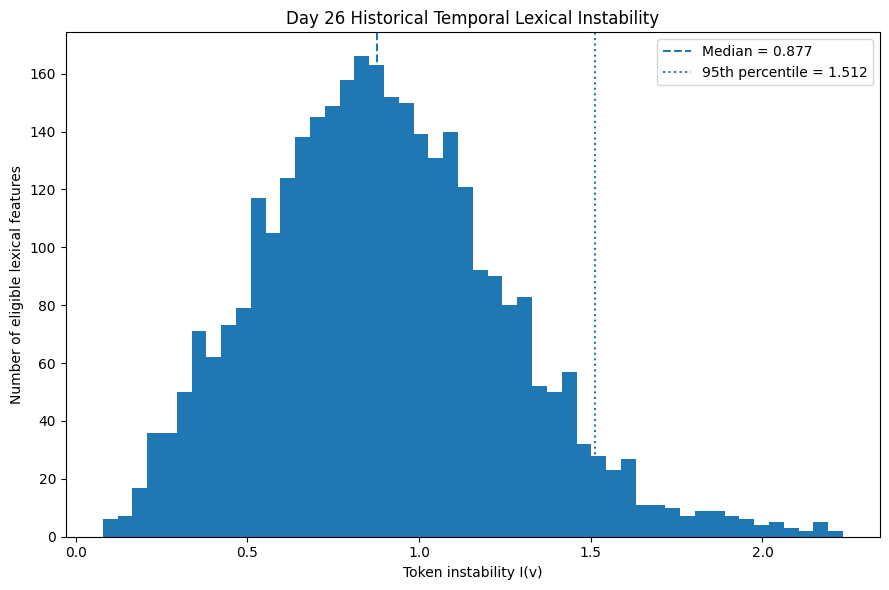

PASS   — instability_distribution_exists
PASS   — instability_distribution_nonempty
PASS   — top_unstable_tokens_exists
PASS   — top_unstable_tokens_nonempty
PASS   — bottom_stable_tokens_exists
PASS   — bottom_stable_tokens_nonempty
PASS   — responsible_class_summary_exists
PASS   — responsible_class_summary_nonempty
PASS   — top_unstable_n_50
PASS   — bottom_stable_n_50
PASS   — responsible_class_summary_all_three_classes
PASS   — responsible_class_counts_sum_to_3240
DAY 26 — INSTABILITY RANKING QC + DESCRIPTIVE RESULTS
Primary eligible vocabulary    : 3,240
Median instability             : 0.876694
95th percentile                : 1.512223
99th percentile                : 1.901816

[RESPONSIBLE CLASS SUMMARY]
responsible_class  n_tokens  mean_instability  median_instability  mean_historical_df  direction_flip_n  token_fraction  direction_flip_fraction
         negative      1200            0.8920              0.8797             93.8333               902          0.3704              

In [17]:
# ============================================================
# DAY 26 — CODE CELL 14
# Descriptive QC + instability distribution + top/bottom tables
# ============================================================

import matplotlib.pyplot as plt


TOKEN_INSTABILITY_DISTRIBUTION_PATH = (
    DAY26_DIR / "token_instability_distribution.png"
)

TOP_UNSTABLE_TOKENS_PATH = (
    DAY26_DIR / "top_unstable_tokens.csv"
)

BOTTOM_STABLE_TOKENS_PATH = (
    DAY26_DIR / "bottom_stable_tokens.csv"
)

RESPONSIBLE_CLASS_SUMMARY_PATH = (
    DAY26_DIR / "responsible_class_summary.csv"
)


# ------------------------------------------------------------
# 1. Frozen descriptive table sizes
# ------------------------------------------------------------

DESCRIPTIVE_TOP_N = 50
DESCRIPTIVE_BOTTOM_N = 50


# ------------------------------------------------------------
# 2. Top unstable tokens
# ------------------------------------------------------------

top_unstable_tokens = (
    token_instability_rank
    .head(
        DESCRIPTIVE_TOP_N
    )
    .copy()
)

top_unstable_tokens[
    "descriptive_group"
] = "TOP_UNSTABLE"


# ------------------------------------------------------------
# 3. Bottom stable tokens
# ------------------------------------------------------------

bottom_stable_tokens = (
    token_instability_rank
    .tail(
        DESCRIPTIVE_BOTTOM_N
    )
    .copy()
)

bottom_stable_tokens[
    "descriptive_group"
] = "BOTTOM_STABLE"


# ------------------------------------------------------------
# 4. Responsible-class summary
# ------------------------------------------------------------

responsible_class_summary = (
    token_instability_rank
    .groupby(
        "responsible_class",
        observed=True
    )
    .agg(
        n_tokens=(
            "token",
            "size"
        ),
        mean_instability=(
            "token_instability",
            "mean"
        ),
        median_instability=(
            "token_instability",
            "median"
        ),
        mean_historical_df=(
            "historical_df",
            "mean"
        ),
        direction_flip_n=(
            "responsible_direction_flip",
            "sum"
        ),
    )
    .reindex(
        CLASS_ORDER
    )
    .reset_index()
)


responsible_class_summary[
    "token_fraction"
] = (
    responsible_class_summary[
        "n_tokens"
    ]
    /
    len(
        token_instability_rank
    )
)

responsible_class_summary[
    "direction_flip_fraction"
] = (
    responsible_class_summary[
        "direction_flip_n"
    ]
    /
    responsible_class_summary[
        "n_tokens"
    ]
)


# ------------------------------------------------------------
# 5. Save descriptive tables
# ------------------------------------------------------------

top_unstable_tokens.to_csv(
    TOP_UNSTABLE_TOKENS_PATH,
    index=False
)

bottom_stable_tokens.to_csv(
    BOTTOM_STABLE_TOKENS_PATH,
    index=False
)

responsible_class_summary.to_csv(
    RESPONSIBLE_CLASS_SUMMARY_PATH,
    index=False
)


# ------------------------------------------------------------
# 6. Distribution plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.hist(
    token_instability_rank[
        "token_instability"
    ],
    bins=50
)

ax.axvline(
    primary_quantiles["q50"],
    linestyle="--",
    linewidth=1.5,
    label=(
        f"Median = "
        f"{primary_quantiles['q50']:.3f}"
    )
)

ax.axvline(
    primary_quantiles["q95"],
    linestyle=":",
    linewidth=1.5,
    label=(
        f"95th percentile = "
        f"{primary_quantiles['q95']:.3f}"
    )
)

ax.set_title(
    "Day 26 Historical Temporal Lexical Instability"
)

ax.set_xlabel(
    "Token instability I(v)"
)

ax.set_ylabel(
    "Number of eligible lexical features"
)

ax.legend()

fig.tight_layout()

fig.savefig(
    TOKEN_INSTABILITY_DISTRIBUTION_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. Artifact integrity
# ------------------------------------------------------------

for name, path in {
    "instability_distribution":
        TOKEN_INSTABILITY_DISTRIBUTION_PATH,

    "top_unstable_tokens":
        TOP_UNSTABLE_TOKENS_PATH,

    "bottom_stable_tokens":
        BOTTOM_STABLE_TOKENS_PATH,

    "responsible_class_summary":
        RESPONSIBLE_CLASS_SUMMARY_PATH,

}.items():

    audit_check(
        f"{name}_exists",
        path.is_file()
    )

    audit_check(
        f"{name}_nonempty",
        path.stat().st_size > 0
    )


audit_check(
    "top_unstable_n_50",
    len(top_unstable_tokens)
    == DESCRIPTIVE_TOP_N
)

audit_check(
    "bottom_stable_n_50",
    len(bottom_stable_tokens)
    == DESCRIPTIVE_BOTTOM_N
)

audit_check(
    "responsible_class_summary_all_three_classes",
    responsible_class_summary[
        "responsible_class"
    ].tolist()
    == CLASS_ORDER
)

audit_check(
    "responsible_class_counts_sum_to_3240",
    int(
        responsible_class_summary[
            "n_tokens"
        ].sum()
    )
    ==
    len(token_instability_rank)
)


# ------------------------------------------------------------
# 8. Support diagnostics for top unstable tail
# ------------------------------------------------------------

top_50_min_df = int(
    top_unstable_tokens[
        "historical_df"
    ].min()
)

top_50_median_df = float(
    top_unstable_tokens[
        "historical_df"
    ].median()
)

top_50_df_ge_50_n = int(
    (
        top_unstable_tokens[
            "historical_df"
        ] >= 50
    ).sum()
)

top_50_all4windows_n = int(
    (
        top_unstable_tokens[
            "windows_present"
        ] == FINAL_N_WINDOWS
    ).sum()
)


# ------------------------------------------------------------
# 9. Hash descriptive artifacts
# ------------------------------------------------------------

TOKEN_INSTABILITY_DISTRIBUTION_SHA256 = (
    sha256_file(
        TOKEN_INSTABILITY_DISTRIBUTION_PATH
    )
)

TOP_UNSTABLE_TOKENS_SHA256 = (
    sha256_file(
        TOP_UNSTABLE_TOKENS_PATH
    )
)

BOTTOM_STABLE_TOKENS_SHA256 = (
    sha256_file(
        BOTTOM_STABLE_TOKENS_PATH
    )
)

RESPONSIBLE_CLASS_SUMMARY_SHA256 = (
    sha256_file(
        RESPONSIBLE_CLASS_SUMMARY_PATH
    )
)


# ------------------------------------------------------------
# 10. Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 26 — INSTABILITY RANKING QC + DESCRIPTIVE RESULTS")
print("=" * 120)

print(
    f"Primary eligible vocabulary    : "
    f"{len(token_instability_rank):,}"
)

print(
    f"Median instability             : "
    f"{primary_quantiles['q50']:.6f}"
)

print(
    f"95th percentile                : "
    f"{primary_quantiles['q95']:.6f}"
)

print(
    f"99th percentile                : "
    f"{primary_quantiles['q99']:.6f}"
)

print("\n[RESPONSIBLE CLASS SUMMARY]")

display_responsible = (
    responsible_class_summary
    .copy()
)

for col in [
    "mean_instability",
    "median_instability",
    "mean_historical_df",
    "token_fraction",
    "direction_flip_fraction",
]:

    display_responsible[
        col
    ] = (
        display_responsible[
            col
        ]
        .round(4)
    )

print(
    display_responsible.to_string(
        index=False
    )
)


print("\n[TOP-50 SUPPORT QC]")

print(
    f"Minimum historical DF          : "
    f"{top_50_min_df}"
)

print(
    f"Median historical DF           : "
    f"{top_50_median_df:.1f}"
)

print(
    f"Tokens with historical DF>=50  : "
    f"{top_50_df_ge_50_n}/{DESCRIPTIVE_TOP_N}"
)

print(
    f"Tokens present in all windows  : "
    f"{top_50_all4windows_n}/{DESCRIPTIVE_TOP_N}"
)


print("\n[TOP 15 UNSTABLE FEATURES]")

print(
    top_unstable_tokens[
        [
            "instability_rank",
            "token",
            "feature_type",
            "historical_df",
            "windows_present",
            "token_instability",
            "responsible_class",
            "responsible_direction_flip",
        ]
    ]
    .head(15)
    .round(
        {
            "token_instability": 6
        }
    )
    .to_string(
        index=False
    )
)


print("\n[BOTTOM 15 STABLE FEATURES]")

print(
    bottom_stable_tokens[
        [
            "instability_rank",
            "token",
            "feature_type",
            "historical_df",
            "windows_present",
            "token_instability",
            "responsible_class",
            "responsible_direction_flip",
        ]
    ]
    .tail(15)
    .round(
        {
            "token_instability": 6
        }
    )
    .to_string(
        index=False
    )
)


print("\n[ARTIFACT HASHES]")

print(
    f"Distribution figure : "
    f"{TOKEN_INSTABILITY_DISTRIBUTION_SHA256}"
)

print(
    f"Top unstable CSV    : "
    f"{TOP_UNSTABLE_TOKENS_SHA256}"
)

print(
    f"Bottom stable CSV   : "
    f"{BOTTOM_STABLE_TOKENS_SHA256}"
)

print(
    f"Class summary CSV   : "
    f"{RESPONSIBLE_CLASS_SUMMARY_SHA256}"
)

print("-" * 120)

print(
    "PASS — frozen instability ranking summarized descriptively"
)

print(
    "PASS — top/bottom reference tables saved without modifying the ranking"
)

print(
    "PASS — responsible-class composition summarized"
)

print(
    "PASS — instability distribution figure saved"
)

print(
    "NOTE — high instability is descriptive historical behavior, not evidence of future error"
)

print(
    "NOTE — Day25 retrospective lexical lookup has still not been performed"
)

print("=" * 120)

In [19]:
# ============================================================
# DAY 26 — CODE CELL 15
# Retrospective Day25 lexical-term lookup
#
# IMPORTANT:
# The Day26 instability ranking was frozen BEFORE this lookup.
# This cell is descriptive only and cannot modify the ranking.
# ============================================================

DAY25_RETROSPECTIVE_LOOKUP_PATH = (
    DAY26_DIR / "day25_retrospective_lexical_lookup.csv"
)

DAY25_POSNEG_SIGNATURE_LOOKUP_PATH = (
    DAY26_DIR / "day25_posneg_signature_lookup.csv"
)

DAY25_WITHIN_SOURCE_LOOKUP_PATH = (
    DAY26_DIR / "day25_within_source_term_lookup.csv"
)


# ------------------------------------------------------------
# 1. Reload frozen Day25 lexical artifacts
# ------------------------------------------------------------

day25_lexical_contrast = pd.read_csv(
    DAY25_LEXICAL_CONTRAST_PATH
)

day25_top_terms = pd.read_csv(
    DAY25_TOP_TERMS_PATH
)

day25_within_source_summary = pd.read_csv(
    DAY25_WITHIN_SOURCE_SUMMARY_PATH
)


# ------------------------------------------------------------
# 2. Required-schema verification
# ------------------------------------------------------------

require_columns(
    day25_lexical_contrast,
    [
        "term",
        "mean_tfidf_posneg",
        "mean_tfidf_pospos",
        "mean_tfidf_difference",
        "abs_mean_tfidf_difference",
        "df_posneg",
        "df_pospos",
        "df_total",
        "df_rate_posneg",
        "df_rate_pospos",
        "df_rate_difference",
        "direction",
    ],
    object_name="day25_lexical_contrast"
)

require_columns(
    day25_within_source_summary,
    [
        "source",
        "stable_for_interpretation",
        "top_10_posneg_enriched_terms",
    ],
    object_name="day25_within_source_summary"
)


# ------------------------------------------------------------
# 3. Verify Day25 artifacts remain unchanged
# ------------------------------------------------------------

DAY25_LEXICAL_CONTRAST_SHA256 = (
    sha256_file(
        DAY25_LEXICAL_CONTRAST_PATH
    )
)

DAY25_TOP_TERMS_SHA256 = (
    sha256_file(
        DAY25_TOP_TERMS_PATH
    )
)

DAY25_WITHIN_SOURCE_SUMMARY_SHA256 = (
    sha256_file(
        DAY25_WITHIN_SOURCE_SUMMARY_PATH
    )
)


audit_check(
    "day25_lexical_contrast_hash_matches_inspected_artifact",
    DAY25_LEXICAL_CONTRAST_SHA256
    ==
    "d800a383a2374ef9e1fa93262a04b7edbd384a3cc115a79b23e5527e3ca425f2"
)

audit_check(
    "day25_top_terms_hash_matches_inspected_artifact",
    DAY25_TOP_TERMS_SHA256
    ==
    "573f907301c11eaf9fa83c10fb70610d53d5112c59e31a8407bb10a06133a0b0"
)

audit_check(
    "day25_within_source_summary_hash_matches_inspected_artifact",
    DAY25_WITHIN_SOURCE_SUMMARY_SHA256
    ==
    "0c94c236c3ac12eef68c5ee909c47e1788b5e07f048cf54ad34a54a2e7db15ad"
)


# ------------------------------------------------------------
# 4. Normalize Day25 terms only for exact Day26 lookup
# ------------------------------------------------------------

day25_lexical_contrast[
    "term_normalized"
] = (
    day25_lexical_contrast[
        "term"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)


audit_check(
    "day25_contrast_terms_nonmissing",
    day25_lexical_contrast[
        "term_normalized"
    ].str.len().gt(0).all()
)


# ------------------------------------------------------------
# 5. Build frozen Day26 ranking lookup
# ------------------------------------------------------------

day26_rank_lookup = (
    token_instability_rank[
        [
            "token",
            "instability_rank",
            "instability_percentile",
            "feature_type",
            "historical_df",
            "windows_present",
            "token_instability",
            "responsible_class",
            "responsible_direction_flip",
            "responsible_sign_change_count",
        ]
    ]
    .copy()
    .rename(
        columns={
            "token": "term_normalized"
        }
    )
)


audit_check(
    "day26_lookup_terms_unique",
    day26_rank_lookup[
        "term_normalized"
    ].is_unique
)


# ------------------------------------------------------------
# 6. Full retrospective lookup
# ------------------------------------------------------------

day25_retrospective_lookup = (
    day25_lexical_contrast
    .merge(
        day26_rank_lookup,
        on="term_normalized",
        how="left",
        validate="many_to_one"
    )
)


day25_retrospective_lookup[
    "in_day26_eligible_vocabulary"
] = (
    day25_retrospective_lookup[
        "instability_rank"
    ].notna()
)


# ------------------------------------------------------------
# 7. Deterministic Day25 P->N signature
#
# Descriptive rule:
# direction = enriched_in_positive_to_negative,
# sorted by Day25 frozen mean_tfidf_difference descending.
#
# Top 15 is used only for retrospective display.
# It does NOT redefine Day26 vocabulary or instability.
# ------------------------------------------------------------

DAY25_POSNEG_SIGNATURE_N = 15

day25_posneg_signature_terms = (
    day25_lexical_contrast[
        day25_lexical_contrast[
            "direction"
        ]
        ==
        "enriched_in_positive_to_negative"
    ]
    .sort_values(
        [
            "mean_tfidf_difference",
            "term_normalized",
        ],
        ascending=[
            False,
            True,
        ],
        kind="mergesort"
    )
    .head(
        DAY25_POSNEG_SIGNATURE_N
    )[
        "term_normalized"
    ]
    .tolist()
)


audit_check(
    "day25_posneg_signature_n_15",
    len(day25_posneg_signature_terms)
    == DAY25_POSNEG_SIGNATURE_N
)

audit_check(
    "day25_posneg_signature_unique",
    len(
        set(
            day25_posneg_signature_terms
        )
    )
    ==
    DAY25_POSNEG_SIGNATURE_N
)


day25_retrospective_lookup[
    "is_day25_posneg_top15"
] = (
    day25_retrospective_lookup[
        "term_normalized"
    ].isin(
        day25_posneg_signature_terms
    )
)


day25_posneg_signature_lookup = (
    day25_retrospective_lookup[
        day25_retrospective_lookup[
            "is_day25_posneg_top15"
        ]
    ]
    .copy()
    .sort_values(
        [
            "mean_tfidf_difference",
            "term_normalized",
        ],
        ascending=[
            False,
            True,
        ],
        kind="mergesort"
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 8. Parse within-source Day25 top-10 P->N terms
# ------------------------------------------------------------

within_source_rows = []

for _, row in (
    day25_within_source_summary
    .iterrows()
):

    source = str(
        row["source"]
    )

    stable = bool(
        row[
            "stable_for_interpretation"
        ]
    )

    raw_terms = str(
        row[
            "top_10_posneg_enriched_terms"
        ]
    )

    parsed_terms = [
        term.strip().lower()
        for term in raw_terms.split("|")
        if term.strip()
    ]

    for source_rank, term in enumerate(
        parsed_terms,
        start=1
    ):

        within_source_rows.append(
            {
                "source":
                    source,

                "stable_for_interpretation":
                    stable,

                "source_term_rank":
                    int(source_rank),

                "term_normalized":
                    term,
            }
        )


day25_within_source_terms = pd.DataFrame(
    within_source_rows
)


audit_check(
    "within_source_term_table_nonempty",
    len(
        day25_within_source_terms
    ) > 0
)


day25_within_source_lookup = (
    day25_within_source_terms
    .merge(
        day26_rank_lookup,
        on="term_normalized",
        how="left",
        validate="many_to_one"
    )
)


day25_within_source_lookup[
    "in_day26_eligible_vocabulary"
] = (
    day25_within_source_lookup[
        "instability_rank"
    ].notna()
)


# ------------------------------------------------------------
# 9. Add within-source corroboration to full lookup
# ------------------------------------------------------------

within_source_union = (
    day25_within_source_terms
    .groupby(
        "term_normalized",
        observed=True
    )
    .agg(
        within_source_count=(
            "source",
            "nunique"
        ),

        within_source_sources=(
            "source",
            lambda x:
                " | ".join(
                    sorted(
                        set(
                            map(str, x)
                        )
                    )
                )
        ),
    )
    .reset_index()
)


day25_retrospective_lookup = (
    day25_retrospective_lookup
    .merge(
        within_source_union,
        on="term_normalized",
        how="left",
        validate="many_to_one"
    )
)


day25_retrospective_lookup[
    "within_source_count"
] = (
    day25_retrospective_lookup[
        "within_source_count"
    ]
    .fillna(0)
    .astype(int)
)


day25_retrospective_lookup[
    "in_within_source_top10_union"
] = (
    day25_retrospective_lookup[
        "within_source_count"
    ] > 0
)


# ------------------------------------------------------------
# 10. Save canonical retrospective artifacts
# ------------------------------------------------------------

day25_retrospective_lookup.to_csv(
    DAY25_RETROSPECTIVE_LOOKUP_PATH,
    index=False
)

day25_posneg_signature_lookup.to_csv(
    DAY25_POSNEG_SIGNATURE_LOOKUP_PATH,
    index=False
)

day25_within_source_lookup.to_csv(
    DAY25_WITHIN_SOURCE_LOOKUP_PATH,
    index=False
)


# ------------------------------------------------------------
# 11. Artifact integrity
# ------------------------------------------------------------

for name, path in {
    "day25_retrospective_lookup":
        DAY25_RETROSPECTIVE_LOOKUP_PATH,

    "day25_posneg_signature_lookup":
        DAY25_POSNEG_SIGNATURE_LOOKUP_PATH,

    "day25_within_source_lookup":
        DAY25_WITHIN_SOURCE_LOOKUP_PATH,

}.items():

    audit_check(
        f"{name}_exists",
        path.is_file()
    )

    audit_check(
        f"{name}_nonempty",
        path.stat().st_size > 0
    )


# ------------------------------------------------------------
# 12. Frozen Day26 ranking must remain unchanged
# ------------------------------------------------------------

audit_check(
    "day26_primary_rank_hash_unchanged_after_day25_lookup",
    sha256_file(
        TOKEN_INSTABILITY_RANK_PATH
    )
    ==
    TOKEN_INSTABILITY_RANK_SHA256
)

audit_check(
    "day26_instability_table_hash_unchanged_after_day25_lookup",
    sha256_file(
        TOKEN_TEMPORAL_INSTABILITY_PATH
    )
    ==
    TOKEN_TEMPORAL_INSTABILITY_SHA256
)


# ------------------------------------------------------------
# 13. Lookup summaries
# ------------------------------------------------------------

contrast_total_n = int(
    len(
        day25_retrospective_lookup
    )
)

contrast_matched_n = int(
    day25_retrospective_lookup[
        "in_day26_eligible_vocabulary"
    ].sum()
)

contrast_match_fraction = (
    contrast_matched_n
    /
    contrast_total_n
)


posneg_signature_matched_n = int(
    day25_posneg_signature_lookup[
        "in_day26_eligible_vocabulary"
    ].sum()
)


within_source_total_rows = int(
    len(
        day25_within_source_lookup
    )
)

within_source_matched_rows = int(
    day25_within_source_lookup[
        "in_day26_eligible_vocabulary"
    ].sum()
)


# ------------------------------------------------------------
# 14. Hash outputs
# ------------------------------------------------------------

DAY25_RETROSPECTIVE_LOOKUP_SHA256 = (
    sha256_file(
        DAY25_RETROSPECTIVE_LOOKUP_PATH
    )
)

DAY25_POSNEG_SIGNATURE_LOOKUP_SHA256 = (
    sha256_file(
        DAY25_POSNEG_SIGNATURE_LOOKUP_PATH
    )
)

DAY25_WITHIN_SOURCE_LOOKUP_SHA256 = (
    sha256_file(
        DAY25_WITHIN_SOURCE_LOOKUP_PATH
    )
)


# ------------------------------------------------------------
# 15. Display deterministic P->N signature
# ------------------------------------------------------------

posneg_display_columns = [
    "term",
    "mean_tfidf_difference",
    "df_posneg",
    "df_pospos",
    "direction",
    "in_day26_eligible_vocabulary",
    "instability_rank",
    "instability_percentile",
    "historical_df",
    "token_instability",
    "responsible_class",
]


print("=" * 120)
print("DAY 26 — RETROSPECTIVE DAY25 LEXICAL RANKING LOOKUP")
print("=" * 120)

print(
    f"Day25 full contrast terms       : "
    f"{contrast_total_n:,}"
)

print(
    f"Matched to Day26 vocabulary     : "
    f"{contrast_matched_n:,} "
    f"({contrast_match_fraction:.3%})"
)

print(
    f"Day25 deterministic P->N set    : "
    f"{DAY25_POSNEG_SIGNATURE_N}"
)

print(
    f"P->N set matched to Day26       : "
    f"{posneg_signature_matched_n}/"
    f"{DAY25_POSNEG_SIGNATURE_N}"
)

print(
    f"Within-source lookup rows        : "
    f"{within_source_total_rows:,}"
)

print(
    f"Within-source matched rows       : "
    f"{within_source_matched_rows:,}"
)


print("\n[DAY25 TOP-15 POSITIVE->NEGATIVE ENRICHED TERMS]")

print(
    day25_posneg_signature_lookup[
        posneg_display_columns
    ]
    .round(
        {
            "mean_tfidf_difference": 6,
            "instability_percentile": 4,
            "token_instability": 6,
        }
    )
    .to_string(
        index=False
    )
)


print("\n[WITHIN-SOURCE TOP-10 TERMS MAPPED TO DAY26]")

within_source_display = (
    day25_within_source_lookup[
        [
            "source",
            "source_term_rank",
            "term_normalized",
            "in_day26_eligible_vocabulary",
            "instability_rank",
            "instability_percentile",
            "historical_df",
            "token_instability",
            "responsible_class",
        ]
    ]
    .copy()
)

print(
    within_source_display
    .round(
        {
            "instability_percentile": 4,
            "token_instability": 6,
        }
    )
    .to_string(
        index=False
    )
)


print("\n[ARTIFACT HASHES]")

print(
    f"Full retrospective lookup : "
    f"{DAY25_RETROSPECTIVE_LOOKUP_SHA256}"
)

print(
    f"P->N signature lookup     : "
    f"{DAY25_POSNEG_SIGNATURE_LOOKUP_SHA256}"
)

print(
    f"Within-source lookup      : "
    f"{DAY25_WITHIN_SOURCE_LOOKUP_SHA256}"
)

print("-" * 120)

print(
    "PASS — Day25 lexical findings were inspected only after Day26 ranking freeze"
)

print(
    "PASS — retrospective terms came from frozen Day25 artifacts, not a manual whitelist"
)

print(
    "PASS — Day26 primary ranking and instability artifacts remain unchanged"
)

print(
    "NOTE — overlap or non-overlap is descriptive only and does not test H1"
)

print("=" * 120)

PASS   — day25_lexical_contrast_hash_matches_inspected_artifact
PASS   — day25_top_terms_hash_matches_inspected_artifact
PASS   — day25_within_source_summary_hash_matches_inspected_artifact
PASS   — day25_contrast_terms_nonmissing
PASS   — day26_lookup_terms_unique
PASS   — day25_posneg_signature_n_15
PASS   — day25_posneg_signature_unique
PASS   — within_source_term_table_nonempty
PASS   — day25_retrospective_lookup_exists
PASS   — day25_retrospective_lookup_nonempty
PASS   — day25_posneg_signature_lookup_exists
PASS   — day25_posneg_signature_lookup_nonempty
PASS   — day25_within_source_lookup_exists
PASS   — day25_within_source_lookup_nonempty
PASS   — day26_primary_rank_hash_unchanged_after_day25_lookup
PASS   — day26_instability_table_hash_unchanged_after_day25_lookup
DAY 26 — RETROSPECTIVE DAY25 LEXICAL RANKING LOOKUP
Day25 full contrast terms       : 339
Matched to Day26 vocabulary     : 305 (89.971%)
Day25 deterministic P->N set    : 15
P->N set matched to Day26       : 9/15
Wi

## Stage 8 — Scientific Closure and Day 27 Handoff

Day 26 has constructed a historical-only lexical-label instability estimator without using future prediction errors to define the predictor.

The primary frozen lexical score is:

\[
I(v)
=
\max_c
SD_t\left[A(v,c,t)\right],
\]

where:

\[
A(v,c,t)
=
\log\frac{n_{11}+0.5}{n_{10}+0.5}
-
\log\frac{n_{01}+0.5}{n_{00}+0.5}.
\]

The resulting vocabulary, token scores, and deterministic ranking are now frozen.

### Descriptive Day 26 finding

Historical lexical-label associations exhibit heterogeneous temporal stability.

The retrospective comparison with Day 25 indicates that the previously observed F3 energy / commodity / supply-disruption lexical signature does not map uniformly to highly unstable historical lexical-label associations. Some terms show high instability, while many prominent Day 25 terms remain historically stable under the frozen Day 26 estimator.

This descriptive result does not test the primary hypothesis.

### Day 26 interpretation boundary

Day 26 may conclude:

> A reproducible historical-only lexical-label instability predictor was constructed and frozen.

Day 26 must not conclude:

> Historically unstable lexical features cause future classification errors.

Day 26 also must not conclude:

> H1 is supported.

The primary hypothesis remains reserved for the Day 27 out-of-time evaluation.

In [20]:
# ============================================================
# DAY 26 — CODE CELL 16
# Day27 handoff manifest + final Day26 artifact audit
# ============================================================

DAY26_DAY27_HANDOFF_PATH = (
    DAY26_DIR / "day26_day27_handoff_manifest.json"
)

DAY26_FINAL_ARTIFACT_AUDIT_PATH = (
    DAY26_DIR / "day26_final_artifact_audit.csv"
)


# ------------------------------------------------------------
# 1. Freeze Day27 interface
# ------------------------------------------------------------

day27_handoff_manifest = {
    "day": 26,
    "artifact": "day26_day27_handoff_manifest",
    "status": "FROZEN_FOR_DAY27",

    "scientific_role": (
        "Define the immutable historical lexical-instability "
        "predictor interface for Day27 out-of-time testing."
    ),

    "token_score": {
        "field": "token_instability",
        "definition": (
            "I(v) = max_c sample SD across historical windows "
            "of smoothed one-vs-rest lexical-label log-odds."
        ),
        "ddof": 1,
        "association_alpha": 0.5,
    },

    "tokenizer": {
        "implementation":
            "sklearn.feature_extraction.text.CountVectorizer",

        "sklearn_version":
            sklearn.__version__,

        "lowercase":
            True,

        "ngram_range":
            [1, 2],

        "stop_words":
            None,

        "max_df_historical_fit":
            0.95,

        "binary_document_presence":
            True,

        "token_pattern":
            vectorizer.get_params().get(
                "token_pattern"
            ),
    },

    "vocabulary": {
        "source":
            str(
                HISTORICAL_VOCABULARY_PATH
            ),

        "eligible_token_count":
            int(
                len(
                    historical_vocabulary
                )
            ),

        "minimum_historical_df":
            20,

        "minimum_windows_present":
            3,

        "token_order_sha256":
            VOCABULARY_TOKEN_ORDER_SHA256,

        "vocabulary_table_sha256":
            VOCABULARY_TABLE_SHA256,

        "vocabulary_manifest_sha256":
            HISTORICAL_VOCABULARY_MANIFEST_SHA256,
    },

    "instability_lookup": {
        "source":
            str(
                TOKEN_INSTABILITY_RANK_PATH
            ),

        "n_tokens":
            int(
                len(
                    token_instability_rank
                )
            ),

        "primary_ranking_sha256":
            TOKEN_INSTABILITY_RANK_SHA256,

        "instability_table_sha256":
            TOKEN_TEMPORAL_INSTABILITY_SHA256,
    },

    "future_observation_exposure": {
        "primary_definition": (
            "Mean token_instability across eligible frozen "
            "historical-vocabulary tokens present in the "
            "future observation."
        ),

        "token_weighting":
            "binary presence",

        "unknown_or_ineligible_tokens":
            "ignored",

        "coverage_definition": (
            "Number of eligible frozen-vocabulary tokens "
            "present divided by the number of vectorized "
            "unigram/bigram features present under the "
            "frozen tokenizer interface."
        ),

        "zero_eligible_tokens": (
            "Exposure is missing. Do not impute using "
            "future labels or correctness."
        ),
    },

    "day27_primary_test": {
        "outcome":
            "future classification error",

        "primary_contrast": (
            "Mean instability exposure among misclassified "
            "future observations minus mean instability "
            "exposure among correctly classified future "
            "observations."
        ),

        "bootstrap_replicates":
            1000,

        "bootstrap_seed":
            42,

        "confidence_interval":
            "95% observation-level bootstrap CI",
    },

    "day27_secondary_analyses": [
        "F3-only analysis",
        "true-positive P->N versus P->P",
        "within-source contrasts",
        "future-window descriptive relation",
        "coverage diagnostics",
        "df>=50 vocabulary sensitivity",
    ],

    "scientific_firewall": {
        "future_labels_used_to_define_token_score":
            False,

        "future_errors_used_to_select_vocabulary":
            False,

        "future_errors_used_to_select_instability_metric":
            False,

        "future_errors_used_to_select_support_threshold":
            False,

        "day25_terms_used_to_modify_primary_ranking":
            False,

        "new_model_training_performed":
            False,

        "new_full_model_inference_performed":
            False,

        "checkpoint_reselection_performed":
            False,

        "prompt_modification_performed":
            False,

        "threshold_tuning_performed":
            False,
    },

    "day26_primary_artifact_hashes": {
        "analysis_manifest":
            DAY26_ANALYSIS_MANIFEST_SHA256,

        "historical_population_manifest":
            HISTORICAL_POPULATION_MANIFEST_SHA256,

        "historical_window_manifest":
            HISTORICAL_WINDOW_MANIFEST_SHA256,

        "historical_window_distribution":
            HISTORICAL_WINDOW_DISTRIBUTION_SHA256,

        "historical_vocabulary_manifest":
            HISTORICAL_VOCABULARY_MANIFEST_SHA256,

        "historical_vocabulary":
            sha256_file(
                HISTORICAL_VOCABULARY_PATH
            ),

        "token_class_association":
            TOKEN_CLASS_ASSOCIATION_SHA256,

        "token_temporal_instability":
            TOKEN_TEMPORAL_INSTABILITY_SHA256,

        "token_instability_rank":
            TOKEN_INSTABILITY_RANK_SHA256,

        "support_sensitivity":
            TOKEN_INSTABILITY_SUPPORT_SENSITIVITY_SHA256,
    },

    "day24_future_prediction_identity": {
        "path":
            str(
                DAY24_FUTURE_PREDICTIONS_PATH
            ),

        "sha256":
            actual_day24_predictions_sha256,

        "n":
            20002,

        "immutable":
            True,
    },

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),
}


save_json(
    day27_handoff_manifest,
    DAY26_DAY27_HANDOFF_PATH
)


# ------------------------------------------------------------
# 2. Handoff integrity checks
# ------------------------------------------------------------

audit_check(
    "day27_handoff_exists",
    DAY26_DAY27_HANDOFF_PATH.is_file()
)

audit_check(
    "day27_handoff_nonempty",
    DAY26_DAY27_HANDOFF_PATH.stat().st_size > 0
)

audit_check(
    "day27_handoff_token_count_3240",
    day27_handoff_manifest[
        "instability_lookup"
    ][
        "n_tokens"
    ] == 3240
)

audit_check(
    "day27_handoff_bootstrap_1000",
    day27_handoff_manifest[
        "day27_primary_test"
    ][
        "bootstrap_replicates"
    ] == 1000
)

audit_check(
    "day27_handoff_seed_42",
    day27_handoff_manifest[
        "day27_primary_test"
    ][
        "bootstrap_seed"
    ] == 42
)


# ------------------------------------------------------------
# 3. Define required Day26 artifacts available at this stage
# ------------------------------------------------------------

required_day26_artifacts = {
    "day26_analysis_manifest":
        DAY26_ANALYSIS_MANIFEST_PATH,

    "historical_population_manifest":
        HISTORICAL_POPULATION_MANIFEST_PATH,

    "historical_population_ids":
        HISTORICAL_POPULATION_IDS_PATH,

    "historical_window_manifest":
        HISTORICAL_WINDOW_MANIFEST_PATH,

    "historical_window_observation_ids":
        HISTORICAL_WINDOW_ID_MAP_PATH,

    "historical_window_distribution_summary":
        HISTORICAL_WINDOW_DISTRIBUTION_PATH,

    "historical_vocabulary_manifest":
        HISTORICAL_VOCABULARY_MANIFEST_PATH,

    "historical_vocabulary":
        HISTORICAL_VOCABULARY_PATH,

    "token_class_association_by_window":
        TOKEN_CLASS_ASSOCIATION_PATH,

    "token_temporal_instability":
        TOKEN_TEMPORAL_INSTABILITY_PATH,

    "token_instability_rank":
        TOKEN_INSTABILITY_RANK_PATH,

    "token_instability_support_sensitivity":
        TOKEN_INSTABILITY_SUPPORT_SENSITIVITY_PATH,

    "token_instability_distribution":
        TOKEN_INSTABILITY_DISTRIBUTION_PATH,

    "top_unstable_tokens":
        TOP_UNSTABLE_TOKENS_PATH,

    "bottom_stable_tokens":
        BOTTOM_STABLE_TOKENS_PATH,

    "responsible_class_summary":
        RESPONSIBLE_CLASS_SUMMARY_PATH,

    "day25_retrospective_lexical_lookup":
        DAY25_RETROSPECTIVE_LOOKUP_PATH,

    "day25_posneg_signature_lookup":
        DAY25_POSNEG_SIGNATURE_LOOKUP_PATH,

    "day25_within_source_term_lookup":
        DAY25_WITHIN_SOURCE_LOOKUP_PATH,

    "day26_day27_handoff_manifest":
        DAY26_DAY27_HANDOFF_PATH,
}


# ------------------------------------------------------------
# 4. Build final artifact audit table
# ------------------------------------------------------------

artifact_audit_rows = []

for artifact_name, artifact_path in (
    required_day26_artifacts.items()
):

    exists = artifact_path.is_file()

    size_bytes = (
        artifact_path.stat().st_size
        if exists
        else 0
    )

    file_sha256 = (
        sha256_file(
            artifact_path
        )
        if exists and size_bytes > 0
        else None
    )

    artifact_audit_rows.append(
        {
            "artifact":
                artifact_name,

            "path":
                str(
                    artifact_path
                ),

            "exists":
                bool(
                    exists
                ),

            "nonempty":
                bool(
                    size_bytes > 0
                ),

            "size_bytes":
                int(
                    size_bytes
                ),

            "sha256":
                file_sha256,
        }
    )


day26_final_artifact_audit = (
    pd.DataFrame(
        artifact_audit_rows
    )
)


day26_final_artifact_audit[
    "pass"
] = (
    day26_final_artifact_audit[
        "exists"
    ]
    &
    day26_final_artifact_audit[
        "nonempty"
    ]
)


day26_final_artifact_audit.to_csv(
    DAY26_FINAL_ARTIFACT_AUDIT_PATH,
    index=False
)


# ------------------------------------------------------------
# 5. Artifact audit checks
# ------------------------------------------------------------

audit_check(
    "all_required_day26_artifacts_exist",
    day26_final_artifact_audit[
        "exists"
    ].all()
)

audit_check(
    "all_required_day26_artifacts_nonempty",
    day26_final_artifact_audit[
        "nonempty"
    ].all()
)

audit_check(
    "all_required_day26_artifacts_pass",
    day26_final_artifact_audit[
        "pass"
    ].all()
)

audit_check(
    "final_artifact_audit_exists",
    DAY26_FINAL_ARTIFACT_AUDIT_PATH.is_file()
)

audit_check(
    "final_artifact_audit_nonempty",
    DAY26_FINAL_ARTIFACT_AUDIT_PATH.stat().st_size > 0
)


# ------------------------------------------------------------
# 6. Re-check immutable core scientific artifacts
# ------------------------------------------------------------

audit_check(
    "analysis_manifest_hash_unchanged",
    sha256_file(
        DAY26_ANALYSIS_MANIFEST_PATH
    )
    ==
    DAY26_ANALYSIS_MANIFEST_SHA256
)

audit_check(
    "historical_population_manifest_hash_unchanged",
    sha256_file(
        HISTORICAL_POPULATION_MANIFEST_PATH
    )
    ==
    HISTORICAL_POPULATION_MANIFEST_SHA256
)

audit_check(
    "historical_window_manifest_hash_unchanged",
    sha256_file(
        HISTORICAL_WINDOW_MANIFEST_PATH
    )
    ==
    HISTORICAL_WINDOW_MANIFEST_SHA256
)

audit_check(
    "vocabulary_manifest_hash_unchanged",
    sha256_file(
        HISTORICAL_VOCABULARY_MANIFEST_PATH
    )
    ==
    HISTORICAL_VOCABULARY_MANIFEST_SHA256
)

audit_check(
    "association_hash_unchanged",
    sha256_file(
        TOKEN_CLASS_ASSOCIATION_PATH
    )
    ==
    TOKEN_CLASS_ASSOCIATION_SHA256
)

audit_check(
    "instability_hash_unchanged",
    sha256_file(
        TOKEN_TEMPORAL_INSTABILITY_PATH
    )
    ==
    TOKEN_TEMPORAL_INSTABILITY_SHA256
)

audit_check(
    "primary_ranking_hash_unchanged",
    sha256_file(
        TOKEN_INSTABILITY_RANK_PATH
    )
    ==
    TOKEN_INSTABILITY_RANK_SHA256
)


# ------------------------------------------------------------
# 7. Re-check Day24 future prediction immutability
# ------------------------------------------------------------

final_day24_prediction_sha256 = (
    sha256_file(
        DAY24_FUTURE_PREDICTIONS_PATH
    )
)


audit_check(
    "day24_prediction_sha256_still_unchanged",
    final_day24_prediction_sha256
    ==
    EXPECTED_DAY24_PREDICTIONS_SHA256
)


# ------------------------------------------------------------
# 8. Freeze handoff / audit hashes
# ------------------------------------------------------------

DAY26_DAY27_HANDOFF_SHA256 = (
    sha256_file(
        DAY26_DAY27_HANDOFF_PATH
    )
)

DAY26_FINAL_ARTIFACT_AUDIT_SHA256 = (
    sha256_file(
        DAY26_FINAL_ARTIFACT_AUDIT_PATH
    )
)


# ------------------------------------------------------------
# 9. Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 26 — DAY27 HANDOFF + FINAL ARTIFACT INTEGRITY AUDIT")
print("=" * 120)

print(
    f"Frozen Day27 token score       : "
    f"token_instability = I(v)"
)

print(
    f"Frozen vocabulary size         : "
    f"{len(token_instability_rank):,}"
)

print(
    f"Future exposure definition     : "
    f"mean I(v) across eligible tokens present"
)

print(
    f"Unknown/ineligible token rule  : "
    f"ignore + report coverage"
)

print(
    f"Zero eligible-token rule       : "
    f"missing exposure; no label-based imputation"
)

print(
    f"Primary Day27 bootstrap        : "
    f"1,000 replicates, seed=42"
)

print(
    f"Required artifacts audited     : "
    f"{len(day26_final_artifact_audit)}"
)

print(
    f"Artifacts passing              : "
    f"{int(day26_final_artifact_audit['pass'].sum())}"
)

print(
    f"Day27 handoff SHA256           : "
    f"{DAY26_DAY27_HANDOFF_SHA256}"
)

print(
    f"Final artifact audit SHA256    : "
    f"{DAY26_FINAL_ARTIFACT_AUDIT_SHA256}"
)

print(
    f"Day24 prediction SHA256        : "
    f"{final_day24_prediction_sha256}"
)

print("-" * 120)

print(
    "PASS — Day27 lexical-instability interface frozen"
)

print(
    "PASS — all current Day26 scientific artifacts exist and are non-empty"
)

print(
    "PASS — all frozen primary scientific artifact hashes remain unchanged"
)

print(
    "PASS — Day24 future prediction artifact remains immutable"
)

print(
    "PASS — no future outcome has been used to redefine the Day26 predictor"
)

print(
    "NOTE — final scientific summary and completion checkpoint remain to be written"
)

print("=" * 120)

PASS   — day27_handoff_exists
PASS   — day27_handoff_nonempty
PASS   — day27_handoff_token_count_3240
PASS   — day27_handoff_bootstrap_1000
PASS   — day27_handoff_seed_42
PASS   — all_required_day26_artifacts_exist
PASS   — all_required_day26_artifacts_nonempty
PASS   — all_required_day26_artifacts_pass
PASS   — final_artifact_audit_exists
PASS   — final_artifact_audit_nonempty
PASS   — analysis_manifest_hash_unchanged
PASS   — historical_population_manifest_hash_unchanged
PASS   — historical_window_manifest_hash_unchanged
PASS   — vocabulary_manifest_hash_unchanged
PASS   — association_hash_unchanged
PASS   — instability_hash_unchanged
PASS   — primary_ranking_hash_unchanged
PASS   — day24_prediction_sha256_still_unchanged
DAY 26 — DAY27 HANDOFF + FINAL ARTIFACT INTEGRITY AUDIT
Frozen Day27 token score       : token_instability = I(v)
Frozen vocabulary size         : 3,240
Future exposure definition     : mean I(v) across eligible tokens present
Unknown/ineligible token rule  : ignore

In [21]:
# ============================================================
# DAY 26 — CODE CELL 17
# Final scientific summary + scientific conclusion
# ============================================================

DAY26_FINAL_SCIENTIFIC_SUMMARY_PATH = (
    DAY26_DIR / "day26_final_scientific_summary.json"
)

DAY26_SCIENTIFIC_CONCLUSION_PATH = (
    DAY26_DIR / "day26_scientific_conclusion.txt"
)


# ------------------------------------------------------------
# 1. Key descriptive quantities
# ------------------------------------------------------------

n_primary_tokens = int(
    len(token_instability_rank)
)

n_secondary_df50 = int(
    len(support_sensitivity)
)

n_direction_flip = int(
    token_temporal_instability[
        "responsible_direction_flip"
    ].sum()
)

direction_flip_fraction = (
    n_direction_flip
    /
    n_primary_tokens
)

top50_low_support_n = int(
    (
        top_unstable_tokens[
            "historical_df"
        ] < 50
    ).sum()
)

top50_df50_n = int(
    (
        top_unstable_tokens[
            "historical_df"
        ] >= 50
    ).sum()
)

top50_all4_n = int(
    (
        top_unstable_tokens[
            "windows_present"
        ] == 4
    ).sum()
)


# ------------------------------------------------------------
# 2. Day25 retrospective summary quantities
# ------------------------------------------------------------

day25_signature_n = int(
    len(day25_posneg_signature_lookup)
)

day25_signature_matched_n = int(
    day25_posneg_signature_lookup[
        "in_day26_eligible_vocabulary"
    ].sum()
)

matched_signature = (
    day25_posneg_signature_lookup[
        day25_posneg_signature_lookup[
            "in_day26_eligible_vocabulary"
        ]
    ]
    .copy()
)

if len(matched_signature) > 0:

    day25_signature_median_percentile = float(
        matched_signature[
            "instability_percentile"
        ].median()
    )

    day25_signature_high90_n = int(
        (
            matched_signature[
                "instability_percentile"
            ] >= 0.90
        ).sum()
    )

else:

    day25_signature_median_percentile = None
    day25_signature_high90_n = 0


# ------------------------------------------------------------
# 3. Build final scientific summary
# ------------------------------------------------------------

day26_final_scientific_summary = {
    "day": 26,
    "artifact": "day26_final_scientific_summary",
    "status": "COMPLETE",

    "scientific_objective": (
        "Construct and freeze a historical-only measure of "
        "temporal lexical-label instability for subsequent "
        "out-of-time evaluation."
    ),

    "primary_research_question": (
        "Do lexical features whose sentiment-label associations "
        "are unstable across historical time contribute to higher "
        "future classification error?"
    ),

    "hypothesis_status": {
        "H1_tested_on_day26": False,
        "H1_supported_claim_permitted": False,
        "H0_rejected_claim_permitted": False,
        "reason": (
            "Day26 constructs the historical predictor only. "
            "Future classification-error association is reserved "
            "for Day27."
        ),
    },

    "historical_population": {
        "n": int(
            len(historical_population)
        ),

        "historical_train_n": 13539,
        "historical_validation_n": 5859,

        "timestamp_min_utc":
            historical_population[
                "timestamp_utc"
            ].min().isoformat(),

        "timestamp_max_utc":
            historical_population[
                "timestamp_utc"
            ].max().isoformat(),

        "label_counts":
            {
                k: int(v)
                for k, v in
                label_counts.items()
            },

        "n_sources":
            int(
                historical_population[
                    "source"
                ].nunique()
            ),
    },

    "historical_windows": {
        "n_windows": int(
            FINAL_N_WINDOWS
        ),

        "fallback_triggered":
            bool(
                WINDOW_FALLBACK_TRIGGERED
            ),

        "window_sizes": {
            row["window"]:
                int(row["actual_n"])
            for _, row in
            historical_window_manifest.iterrows()
        },

        "minimum_class_support":
            int(
                final_class_support
                .min()
                .min()
            ),
    },

    "vocabulary": {
        "raw_features":
            int(
                raw_vocabulary_size
            ),

        "eligible_primary_tokens":
            n_primary_tokens,

        "unigram_count":
            int(
                feature_type_counts.get(
                    "unigram", 0
                )
            ),

        "bigram_count":
            int(
                feature_type_counts.get(
                    "bigram", 0
                )
            ),

        "primary_support_rule":
            "historical df >= 20 and presence in >= 3 windows",

        "secondary_df50_tokens":
            n_secondary_df50,
    },

    "association_estimation": {
        "metric":
            "smoothed_one_vs_rest_log_odds",

        "alpha":
            float(ALPHA),

        "token_class_window_rows":
            int(
                len(
                    token_class_association
                )
            ),

        "all_primary_associations_finite":
            True,

        "zero_df_token_window_pairs":
            int(
                zero_df_token_window_pairs
            ),
    },

    "temporal_instability": {
        "definition":
            "I(v)=max_c SD_t[A(v,c,t)], sample SD with ddof=1",

        "n_tokens":
            n_primary_tokens,

        "mean":
            float(
                token_temporal_instability[
                    "token_instability"
                ].mean()
            ),

        "median":
            float(
                primary_quantiles["q50"]
            ),

        "q95":
            float(
                primary_quantiles["q95"]
            ),

        "q99":
            float(
                primary_quantiles["q99"]
            ),

        "minimum":
            float(
                token_temporal_instability[
                    "token_instability"
                ].min()
            ),

        "maximum":
            float(
                token_temporal_instability[
                    "token_instability"
                ].max()
            ),

        "responsible_class_counts":
            {
                k: int(v)
                for k, v in
                responsible_class_counts.items()
            },

        "responsible_direction_flip_n":
            n_direction_flip,

        "responsible_direction_flip_fraction":
            float(
                direction_flip_fraction
            ),
    },

    "support_qc": {
        "top50_min_historical_df":
            int(
                top_50_min_df
            ),

        "top50_median_historical_df":
            float(
                top_50_median_df
            ),

        "top50_df_ge_50_n":
            top50_df50_n,

        "top50_df_lt_50_n":
            top50_low_support_n,

        "top50_present_in_all4_windows_n":
            top50_all4_n,

        "interpretation": (
            "The extreme instability tail is enriched for "
            "lower-support terms. This does not redefine the "
            "primary df>=20 ranking; the pre-registered df>=50 "
            "analysis remains secondary robustness evidence."
        ),
    },

    "day25_retrospective_comparison": {
        "full_day25_contrast_terms":
            int(
                contrast_total_n
            ),

        "full_contrast_matched_to_day26":
            int(
                contrast_matched_n
            ),

        "full_contrast_match_fraction":
            float(
                contrast_match_fraction
            ),

        "deterministic_posneg_signature_n":
            day25_signature_n,

        "posneg_signature_matched_n":
            day25_signature_matched_n,

        "matched_signature_median_instability_percentile":
            day25_signature_median_percentile,

        "matched_signature_top10_percentile_n":
            day25_signature_high90_n,

        "interpretation": (
            "The Day25 F3 positive-to-negative lexical/topic "
            "signature does not map uniformly to historically "
            "unstable lexical-label associations. Some terms "
            "rank highly, while several prominent energy/"
            "commodity terms are historically stable under the "
            "frozen Day26 estimator."
        ),

        "causal_interpretation_permitted":
            False,
    },

    "scientific_conclusion": (
        "Day26 successfully constructed and froze a reproducible "
        "historical-only lexical-label instability estimator. "
        "Historical lexical-label associations show heterogeneous "
        "temporal stability. The retrospective Day25 comparison "
        "shows only partial overlap between the previously observed "
        "F3 lexical/topic signature and historically unstable "
        "lexical-label associations. Day26 does not evaluate "
        "whether instability predicts future classification error; "
        "H1 remains untested until Day27."
    ),

    "day27_status": (
        "READY_FOR_OUT_OF_TIME_HYPOTHESIS_TEST"
    ),

    "scientific_firewall": {
        "future_labels_used_to_construct_predictor":
            False,

        "future_errors_used_to_construct_predictor":
            False,

        "day25_terms_used_to_define_vocabulary":
            False,

        "day25_terms_used_to_define_instability":
            False,

        "new_model_training":
            False,

        "new_full_model_inference":
            False,

        "checkpoint_reselection":
            False,

        "prompt_modification":
            False,

        "threshold_tuning":
            False,

        "H1_claim_made":
            False,
    },

    "primary_artifact_hashes": {
        "analysis_manifest":
            DAY26_ANALYSIS_MANIFEST_SHA256,

        "historical_population_manifest":
            HISTORICAL_POPULATION_MANIFEST_SHA256,

        "historical_window_manifest":
            HISTORICAL_WINDOW_MANIFEST_SHA256,

        "historical_vocabulary_manifest":
            HISTORICAL_VOCABULARY_MANIFEST_SHA256,

        "token_class_association":
            TOKEN_CLASS_ASSOCIATION_SHA256,

        "token_temporal_instability":
            TOKEN_TEMPORAL_INSTABILITY_SHA256,

        "token_instability_rank":
            TOKEN_INSTABILITY_RANK_SHA256,

        "day27_handoff":
            DAY26_DAY27_HANDOFF_SHA256,
    },

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),
}


# ------------------------------------------------------------
# 4. Save JSON summary
# ------------------------------------------------------------

save_json(
    day26_final_scientific_summary,
    DAY26_FINAL_SCIENTIFIC_SUMMARY_PATH
)


# ------------------------------------------------------------
# 5. Human-readable scientific conclusion
# ------------------------------------------------------------

scientific_conclusion_text = f"""
DAY 26 — SCIENTIFIC CONCLUSION
==============================

STATUS
------
COMPLETE — HISTORICAL TEMPORAL LEXICAL-LABEL INSTABILITY ESTIMATOR CONSTRUCTED AND FROZEN.

WHAT DAY 26 ESTABLISHED
-----------------------
1. The exact pre-future historical estimation population was frozen at 19,398 observations.
2. Four deterministic chronological historical windows were constructed without fallback.
3. A historical-only unigram+bigram vocabulary was frozen at 3,240 eligible lexical features.
4. Token-class associations were estimated using smoothed one-vs-rest log-odds with alpha=0.5.
5. Primary temporal instability was defined as:

   I(v) = max_c SD_t[A(v,c,t)]

   using sample standard deviation with ddof=1.
6. The complete token instability table and deterministic ranking were frozen before retrospective inspection of Day25 lexical terms.
7. The Day27 document-level exposure interface was frozen before future-error testing.

DESCRIPTIVE FINDINGS
--------------------
Historical lexical-label associations show heterogeneous temporal stability.

Median token instability:
{primary_quantiles["q50"]:.6f}

95th percentile:
{primary_quantiles["q95"]:.6f}

Maximum:
{token_temporal_instability["token_instability"].max():.6f}

The extreme high-instability tail is enriched for relatively low-support lexical features:
only {top50_df50_n}/50 of the top-50 tokens have historical DF >= 50.
This does not alter the pre-registered primary ranking; df>=50 remains a secondary sensitivity analysis.

The retrospective Day25 comparison shows that the previously observed F3
positive-to-negative energy / commodity / supply-disruption lexical signature
does not map uniformly to historically unstable lexical-label associations.
Some terms exhibit high historical instability, while several prominent Day25
terms are historically stable under the frozen Day26 estimator.

SCIENTIFIC BOUNDARY
-------------------
Day26 does NOT establish that lexical instability causes future classification error.

Day26 does NOT test H1.

Day26 does NOT reject H0.

No future labels or future classification errors were used to define the
historical instability predictor.

NEXT SCIENTIFIC STEP
--------------------
Day27 will apply the frozen Day26 predictor out-of-time and test whether future
observations with greater exposure to historically unstable lexical features
are more likely to be misclassified.

DAY 26 FINAL SCIENTIFIC STATUS
------------------------------
PASS — HISTORICAL TEMPORAL LEXICAL-LABEL INSTABILITY ESTIMATOR CONSTRUCTED AND FROZEN.
READY — DAY 27 OUT-OF-TIME HYPOTHESIS TEST.
""".strip()


with open(
    DAY26_SCIENTIFIC_CONCLUSION_PATH,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        scientific_conclusion_text
        + "\n"
    )


# ------------------------------------------------------------
# 6. Integrity checks
# ------------------------------------------------------------

audit_check(
    "final_scientific_summary_exists",
    DAY26_FINAL_SCIENTIFIC_SUMMARY_PATH.is_file()
)

audit_check(
    "final_scientific_summary_nonempty",
    DAY26_FINAL_SCIENTIFIC_SUMMARY_PATH.stat().st_size > 0
)

audit_check(
    "scientific_conclusion_exists",
    DAY26_SCIENTIFIC_CONCLUSION_PATH.is_file()
)

audit_check(
    "scientific_conclusion_nonempty",
    DAY26_SCIENTIFIC_CONCLUSION_PATH.stat().st_size > 0
)


reloaded_final_summary = load_json(
    DAY26_FINAL_SCIENTIFIC_SUMMARY_PATH
)


audit_check(
    "final_summary_roundtrip_exact",
    reloaded_final_summary
    ==
    day26_final_scientific_summary
)

audit_check(
    "final_summary_H1_untested",
    reloaded_final_summary[
        "hypothesis_status"
    ][
        "H1_tested_on_day26"
    ] is False
)

audit_check(
    "final_summary_day27_ready",
    reloaded_final_summary[
        "day27_status"
    ]
    ==
    "READY_FOR_OUT_OF_TIME_HYPOTHESIS_TEST"
)

audit_check(
    "final_summary_future_leakage_false",
    reloaded_final_summary[
        "scientific_firewall"
    ][
        "future_errors_used_to_construct_predictor"
    ] is False
)


# ------------------------------------------------------------
# 7. Freeze hashes
# ------------------------------------------------------------

DAY26_FINAL_SCIENTIFIC_SUMMARY_SHA256 = (
    sha256_file(
        DAY26_FINAL_SCIENTIFIC_SUMMARY_PATH
    )
)

DAY26_SCIENTIFIC_CONCLUSION_SHA256 = (
    sha256_file(
        DAY26_SCIENTIFIC_CONCLUSION_PATH
    )
)


# ------------------------------------------------------------
# 8. Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 26 — FINAL SCIENTIFIC SUMMARY")
print("=" * 120)

print(
    f"Historical population       : "
    f"{len(historical_population):,}"
)

print(
    f"Historical windows          : "
    f"{FINAL_N_WINDOWS}"
)

print(
    f"Frozen vocabulary           : "
    f"{n_primary_tokens:,}"
)

print(
    f"Median instability          : "
    f"{primary_quantiles['q50']:.6f}"
)

print(
    f"95th percentile             : "
    f"{primary_quantiles['q95']:.6f}"
)

print(
    f"Direction-flip tokens       : "
    f"{n_direction_flip:,} "
    f"({direction_flip_fraction:.3%})"
)

print(
    f"Top-50 with DF>=50          : "
    f"{top50_df50_n}/50"
)

print(
    f"Day25 P->N signature match  : "
    f"{day25_signature_matched_n}/"
    f"{day25_signature_n}"
)

if day25_signature_median_percentile is not None:

    print(
        f"Matched signature median pct: "
        f"{day25_signature_median_percentile:.4f}"
    )

print(
    f"Summary SHA256              : "
    f"{DAY26_FINAL_SCIENTIFIC_SUMMARY_SHA256}"
)

print(
    f"Conclusion SHA256           : "
    f"{DAY26_SCIENTIFIC_CONCLUSION_SHA256}"
)

print("-" * 120)

print(
    "PASS — Day26 final scientific summary frozen"
)

print(
    "PASS — scientific conclusion respects the pre-registered interpretation boundary"
)

print(
    "PASS — H1 explicitly remains untested"
)

print(
    "READY — completion checkpoint and canonical notebook save"
)

print("=" * 120)

PASS   — final_scientific_summary_exists
PASS   — final_scientific_summary_nonempty
PASS   — scientific_conclusion_exists
PASS   — scientific_conclusion_nonempty
PASS   — final_summary_roundtrip_exact
PASS   — final_summary_H1_untested
PASS   — final_summary_day27_ready
PASS   — final_summary_future_leakage_false
DAY 26 — FINAL SCIENTIFIC SUMMARY
Historical population       : 19,398
Historical windows          : 4
Frozen vocabulary           : 3,240
Median instability          : 0.876694
95th percentile             : 1.512223
Direction-flip tokens       : 2,204 (68.025%)
Top-50 with DF>=50          : 6/50
Day25 P->N signature match  : 9/15
Matched signature median pct: 0.1238
Summary SHA256              : e7359d7f0d0f212202df5c7f3a8974228af5ec499257852b9e9a9512c66516e4
Conclusion SHA256           : 3c088864077bb0dc3dec3a23e1e9d8e1d45546c8ddfa5817cc6208e12198017c
------------------------------------------------------------------------------------------------------------------------
PASS

In [ ]:
# Scientific provenance consumed by Day 27
DAY26_COMPLETION_CHECKPOINT_PATH = (
    DAY26_DIR / "day26_completion_checkpoint.json"
)
day26_completion_checkpoint = {
    "day": 26,

    "status": "PASS",

    "scientific_status":
        "HISTORICAL_TEMPORAL_LEXICAL_LABEL_INSTABILITY_ESTIMATOR_FROZEN",

    "primary_scientific_endpoint": {
        "historical_population_n":
            int(
                len(
                    historical_population
                )
            ),

        "historical_windows":
            int(
                FINAL_N_WINDOWS
            ),

        "eligible_vocabulary_n":
            int(
                len(
                    token_instability_rank
                )
            ),

        "primary_token_score":
            "I(v)=max_c SD_t[A(v,c,t)]",

        "association_alpha":
            float(
                ALPHA
            ),

        "instability_ddof":
            1,
    },

    "hypothesis_status": {
        "H1_tested":
            False,

        "H1_supported_claim":
            False,

        "H0_rejected_claim":
            False,

        "next_test":
            "Day27 out-of-time hypothesis test",
    },

    "scientific_findings": {
        "median_instability":
            float(
                primary_quantiles[
                    "q50"
                ]
            ),

        "q95_instability":
            float(
                primary_quantiles[
                    "q95"
                ]
            ),

        "direction_flip_n":
            int(
                n_direction_flip
            ),

        "top50_df_ge_50_n":
            int(
                top50_df50_n
            ),

        "day25_posneg_signature_matched_n":
            int(
                day25_signature_matched_n
            ),

        "day25_posneg_signature_total_n":
            int(
                day25_signature_n
            ),

        "day25_overlap_interpretation": (
            "Partial rather than uniform overlap between "
            "Day25 F3 lexical/topic signature and "
            "historically unstable lexical-label associations."
        ),
    },

    "scientific_firewall": {
        "future_labels_used_to_construct_predictor":
            False,

        "future_errors_used_to_construct_predictor":
            False,

        "day25_terms_used_to_define_vocabulary":
            False,

        "day25_terms_used_to_define_instability":
            False,

        "new_model_training_performed":
            False,

        "lora_update_performed":
            False,

        "checkpoint_reselection_performed":
            False,

        "prompt_modification_performed":
            False,

        "threshold_tuning_performed":
            False,

        "new_full_model_inference_performed":
            False,

        "causal_claim_made":
            False,
    },

    "core_artifact_hashes": {
        "analysis_manifest":
            DAY26_ANALYSIS_MANIFEST_SHA256,

        "historical_population_manifest":
            HISTORICAL_POPULATION_MANIFEST_SHA256,

        "historical_window_manifest":
            HISTORICAL_WINDOW_MANIFEST_SHA256,

        "historical_window_distribution":
            HISTORICAL_WINDOW_DISTRIBUTION_SHA256,

        "historical_vocabulary_manifest":
            HISTORICAL_VOCABULARY_MANIFEST_SHA256,

        "token_class_association":
            TOKEN_CLASS_ASSOCIATION_SHA256,

        "association_semantic":
            ASSOCIATION_SEMANTIC_SHA256,

        "token_temporal_instability":
            TOKEN_TEMPORAL_INSTABILITY_SHA256,

        "token_instability_rank":
            TOKEN_INSTABILITY_RANK_SHA256,

        "support_sensitivity":
            TOKEN_INSTABILITY_SUPPORT_SENSITIVITY_SHA256,

        "day27_handoff":
            DAY26_DAY27_HANDOFF_SHA256,

        "final_scientific_summary":
            DAY26_FINAL_SCIENTIFIC_SUMMARY_SHA256,

        "scientific_conclusion":
            DAY26_SCIENTIFIC_CONCLUSION_SHA256,
    },

    "upstream_identity": {
        "day07_historical_source_sha256":
            actual_day07_source_sha256,

        "day24_future_prediction_sha256":
            EXPECTED_DAY24_PREDICTIONS_SHA256,

        "day24_future_prediction_n":
            20002,

        "day24_future_prediction_unchanged":
            True,
    },


    "day27_handoff": {
        "status":
            "FROZEN_FOR_DAY27",

        "token_score":
            "token_instability",

        "observation_exposure":
            "mean I(v) across eligible tokens present",

        "bootstrap_replicates":
            1000,

        "bootstrap_seed":
            42,
    },

    "day26_complete":
        True,

    "next_action":
        "DAY27_OUT_OF_TIME_HYPOTHESIS_TEST",

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),
}


save_json(
    day26_completion_checkpoint,
    DAY26_COMPLETION_CHECKPOINT_PATH
)
